# Fuffaguru_AVS

## Simulazione di un Fondo Popolare Sovrano

**Un esercizio di *steelman*: prendiamo la proposta sul serio e vediamo che numeri escono.**

---

### Di cosa parliamo

Il progetto `Fuffaguru_AVS` simula un **Fondo Popolare Sovrano** alimentato da tre fonti fiscali
(recupero dell'evasione, imposta patrimoniale, imposta di successione sulle grandi aziende) che
investe il proprio patrimonio in un paniere di partecipate pubbliche italiane e in BTP, e che
— se le cose vanno meglio del previsto — eroga un **dividendo sociale** ai cittadini.

Il nome è uno sfottò affettuoso: `AVS` sta per **Alleanza Verdi Sinistra**, e l'oggetto della
simulazione è l'idea, circolata nel dibattito politico, di un fondo sovrano che «specula in borsa»
con soldi garantiti dalle imprese di Stato. Qui **non** smontiamo la proposta in partenza: la
implementiamo nella versione **più generosa e più competente possibile** (uno *steelman*, appunto)
e lasciamo che siano i numeri a dire cosa regge e cosa no.

> **Fair play.** Questo non è il programma di AVS: è una sua ricostruzione stilizzata, con
> parametri che ho scelto io. Se AVS pubblica numeri diversi, ha ragione lei sui suoi numeri.
> Il punto del notebook è metodologico: *come si quantifica* una proposta così, e quali sono
> le grandezze che decidono se funziona.

### Cosa NON è

- **Non è una previsione.** È un modello didattico, con parametri dichiaratamente rozzi.
- **Non è una consulenza finanziaria né una stima ufficiale di gettito.** I numeri fiscali sono
  stime di ordine di grandezza, ognuna etichettata con la propria fonte e con un `TODO: raffinare`.
- **Non tiene conto** di tutta la normativa UE (regole di bilancio, aiuti di Stato, concorrenza),
  che nella realtà morderebbe parecchio. Se ne parla nella §14, dove si dice anche cosa il modello
  *non* può vedere.

### Mappa del notebook

| § | Contenuto | Cosa impari |
|---|---|---|
| 1 | Setup e **pannello di controllo** | dove si girano le manopole |
| 2 | Architettura, glossario, convenzioni | come è fatto il modello, cosa significa ogni simbolo |
| 3 | Le tre fonti: **RCF, IPP, ISA** | da dove arrivano i soldi, con i conti in chiaro |
| 4 | Dinamica delle entrate | shock ±20 %, regimi politici, crollo a zero |
| 5 | Mercati: paniere, correlazioni | cosa rendono ENI, ENEL, Poste, Terna, Snam, Leonardo, FS, TIM |
| 6 | BTP: tassi, duration, politiche | la gamba obbligazionaria e l'onestà contabile |
| 7 | La ricorsione del fondo | l'interesse composto, e un percorso commentato anno per anno |
| 8 | **MCMC** (`emcee`) | come si costruiscono gli intervalli di confidenza |
| 9 | Risultati a 10/20/30/50 anni | ventagli, distribuzioni, valori reali e nominali |
| 10 | **Benchmark di nazionalizzazione** | ENI, ENEL, Poste, TIM rete, Snam, Terna, Leonardo, FS |
| 11 | **Dividendo sociale** | quanto vale, a chi va, e cosa costa in termini di obiettivi |
| 12 | Sensibilità | quale manopola sposta davvero l'ago |
| 13 | Scenari a confronto | base, ottimista, abolizione 2028, shock spread |
| 14 | Limiti e onestà contabile | dove il modello sarebbe tentato di barare |
| 15 | Il punto, e come si gioca | conclusioni e istruzioni per l'uso |

### Come si legge

Ogni sezione ha una parte discorsiva (quella che stai leggendo) e una parte di codice.
Le **manopole** stanno tutte in un unico blocco nella §1: cambia un numero, riesegui, guarda
i grafici. Nessun valore è cablato dentro le funzioni.

**Unità di misura.** Tutto in **miliardi di euro (mld €)**, salvo dove indicato.
I risultati principali sono riportati in **euro reali 2026** (potere d'acquisto di oggi);
il nominale è sempre disponibile come secondo pannello, perché a 30 anni la differenza è enorme
e mostrare solo il nominale è il modo più semplice di mentire in buona fede.


In [1]:
# ══════════════════════════════════════════════════════════════════════════════
# §1 — Setup
# ══════════════════════════════════════════════════════════════════════════════
#
#  Dipendenze minime : numpy, pandas, matplotlib, scipy
#  Dipendenza opzionale : emcee  (se manca, si usa un sampler MH interno)
#
#  Per reinstallare tutto:  pip install -r ../requirements.txt
# ──────────────────────────────────────────────────────────────────────────────

import json
import math
import time
import warnings
from dataclasses import dataclass, field, fields, asdict, is_dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats

# `display` esiste in Jupyter; fuori da Jupyter (per i test da riga di comando)
# definiamo un fallback che stampa a schermo.
try:
    from IPython.display import display
except Exception:
    def display(obj):
        print(obj)

warnings.filterwarnings("ignore", category=FutureWarning)

# --- dipendenza opzionale ----------------------------------------------------
try:
    import emcee
    HAS_EMCEE = True
    EMCEE_VERSION = emcee.__version__
except Exception:
    emcee = None
    HAS_EMCEE = False
    EMCEE_VERSION = None

# --- percorsi ---------------------------------------------------------------
# Il notebook funziona sia lanciato da notebooks/ sia dalla root del progetto.
HERE = Path.cwd()
PROJECT_ROOT = HERE.parent if HERE.name == "notebooks" else HERE
DATA_DIR = PROJECT_ROOT / "data"
FIG_DIR = PROJECT_ROOT / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 20261116

# --- stile grafico ----------------------------------------------------------
C = {
    "ink":      "#1b1b1b",
    "grid":     "#d8d8d8",
    "rcf":      "#2f6f9f",   # blu   — riscossione
    "ipp":      "#b8860b",   # oro   — patrimoniale
    "isa":      "#8b3a62",   # porpora — successioni
    "tot":      "#111111",
    "equity":   "#2a7f4f",
    "btp":      "#a8322d",
    "band1":    "#cfe3f2",
    "band2":    "#a8cae6",
    "band3":    "#6fa3ce",
    "accent":   "#d1495b",
    "grey":     "#7a7a7a",
}

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (10.5, 4.6),
    "savefig.dpi": 150,
    "font.size": 10.5,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "axes.edgecolor": "#444444",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": C["grid"],
    "grid.linewidth": 0.6,
    "grid.alpha": 0.75,
    "legend.frameon": False,
    "legend.fontsize": 9.5,
    "xtick.color": "#333333",
    "ytick.color": "#333333",
    "figure.autolayout": False,
})

plt.rcParams["axes.prop_cycle"] = mpl.cycler(
    color=[C["rcf"], C["ipp"], C["isa"], C["equity"], C["btp"], C["grey"]]
)


def savefig(fig, name: str, verbose: bool = False):
    """Salva una figura in figures/ (utile per riusarla in una presentazione)."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    if verbose:
        print(f"  → {path}")


def mld(x, _=None):
    """Formattatore: 1234.5 → '1.234'."""
    return f"{x:,.0f}".replace(",", ".")


def pct(x, _=None):
    """Formattatore: 0.073 → '7,3 %'."""
    return f"{x * 100:.1f}".replace(".", ",") + " %"


MLD = FuncFormatter(mld)
PCT = FuncFormatter(pct)

# --- utility numeriche ------------------------------------------------------

def _arr(x, n):
    """Trasforma scalare o vettore in un array di forma (n,). Serve a far
    convivere parametri fissi e parametri che variano da percorso a percorso."""
    a = np.asarray(x, dtype=float)
    if a.ndim == 0:
        return np.full(n, float(a))
    return np.broadcast_to(a, (n,)).astype(float)


def _sc(x):
    """Estrae un float da uno scalare o da un array di un solo elemento."""
    a = np.asarray(x, dtype=float).ravel()
    if a.size != 1:
        raise ValueError(f"atteso scalare, ricevuto array di forma {np.shape(x)}")
    return float(a[0])


def qtab(x, name="F"):
    """Tabella dei quantili, la forma in cui leggeremo tutti i risultati."""
    qs = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    d = {f"P{int(q * 100):02d}": np.quantile(x, q, axis=0) for q in qs}
    d["media"] = np.mean(x, axis=0)
    return pd.DataFrame(d, index=[f"{name}{t}" for t in range(np.shape(x)[1])])


print(f"numpy {np.__version__} · pandas {pd.__version__} · matplotlib {mpl.__version__}")
print(f"emcee: {'disponibile v' + str(EMCEE_VERSION) if HAS_EMCEE else 'NON disponibile → uso il sampler interno'}")
print(f"root progetto: {PROJECT_ROOT}")


numpy 2.5.4 · pandas 3.1.0 · matplotlib 3.11.2
emcee: disponibile v3.1.6
root progetto: /home/massimiliano-romanello/Documenti/Fuffaguru_AVS


## §2 — Architettura del modello, glossario, convenzioni

### 2.1 Il disegno in una riga

```
   FONTI FISCALI            MERCATI                    FONDO
   ─────────────            ───────                    ─────
   RCF ─┐
   IPP ─┼─→ I_t  ────────→  α_t (equity)   ────→  F_{t+1} = (F_t + I_t − D_t)·(1 + α_t)
   ISA ─┘                   y_t (BTP)                │
      ▲                        ▲                    └─→ D_t (dividendo sociale)
      │                        │                          se F_t > traiettoria attesa
   regime politico        inflazione, PIL
```

Tre blocchi che si parlano poco (ed è voluto: rende il modello leggibile e ogni ipotesi isolabile).

1. **Blocco fiscale** → produce il flusso annuo `I_t = RCF_t + IPP_t + ISA_t` in mld €.
2. **Blocco mercati** → produce il rendimento annuo `α_t` del portafoglio (equity + BTP).
3. **Blocco fondo** → la ricorsione, più la regola di spesa che genera il dividendo sociale.

### 2.2 Glossario

| Simbolo | Nome | Unità | Significato |
|---|---|---|---|
| `F_t` | dotazione (stock) | mld € | patrimonio del fondo a inizio anno `t` |
| `F₀` | **dote iniziale** | mld € | primo anno di incassi: `RCF₀ + IPP₀ + ISA₀` |
| `I_t` | afflusso annuo | mld € | nuovo gettito accantonato nel fondo nell'anno `t` |
| `RCF` | **Riscossione Crediti Fiscali** | mld € | cassa incassata dal magazzino delle cartelle non riscosse |
| `IPP` | **Imposta Patrimoniale Progressiva** | mld € | 0,1 % sui patrimoni netti sopra 500 k€ |
| `ISA` | **Imposta Successoria sulle Aziende** | mld € | revoca dell'esenzione sui grandi passaggi ereditari d'impresa |
| `α_t` | rendimento del portafoglio | % annuo | equity + BTP, al netto di commissioni |
| `y_t` | rendimento BTP a 10 anni | % annuo | tasso nominale, processo mean-reverting |
| `φ_t` | quota obbligazionaria | 0–1 | frazione del fondo investita in BTP |
| `D_t` | dividendo sociale | mld € | quanto viene distribuito ai cittadini nell'anno `t` |
| `g_t` | crescita del PIL nominale | % annuo | trascina le entrate fiscali |
| `π_t` | inflazione | % annuo | serve a distinguere reale e nominale |

### 2.3 Perché questi nomi (e non «A», «B», «C»)

`A`, `B`, `C` sono comodi finché il modello sta in una pagina. Appena compare un grafico con
tre curve, servono etichette che dicano **cosa sono** e **come si calcolano**:

- **`RCF` — Riscossione Crediti Fiscali.** Non «lotta all'evasione»: quella è un'attività, non un
  gettito. Qui si modella la **cassa effettivamente incassata** dal magazzino dei crediti già
  accertati e non riscossi (cartelle, ruoli, avvisi). È la grandezza che entra in bilancio, ed è
  l'unica che si può accantonare in un fondo. La sigla dice anche il parametro chiave: il *tasso
  di realizzo* sul magazzino.
- **`IPP` — Imposta Patrimoniale Progressiva.** «Progressiva» perché la soglia a 500 k€ la rende
  di fatto progressiva (0 sotto soglia, 0,1 % sopra). Evita l'ambiguità con «patrimoniale secca»
  e ricorda che la progressività sta nella soglia, non nell'aliquota.
- **`ISA` — Imposta Successoria sulle Aziende.** Deliberatamente ristretta: non è una patrimoniale
  sulle successioni in generale, è l'imposta sui **trasferimenti d'impresa** di dimensione
  rilevante, cioè esattamente il perimetro della sentenza 120/2020.

### 2.4 Convenzioni (le tre che contano)

**(a) Reale vs nominale.** Tutti i rendimenti azionari e i tassi BTP sono **nominali** (è così che
li si osserva). L'inflazione è simulata anno per anno e il risultato è riportato in **€ reali 2026**
come misura principale. Un fondo che passa da 18 a ~1.300 mld in 30 anni *nominali*, con inflazione
al 2 %, vale in realtà ~720 mld di oggi: quasi la metà. Mostrare solo il nominale è il trucco
retorico più comune, e non lo usiamo.

**(b) Total return, dividendi reinvestiti.** I rendimenti azionari includono i dividendi (ENEL ed
ENI rendono storicamente il 5–7 % solo di cedola). Un fondo che incassa dividendi e non li
reinveste non cresce: qui si assume reinvestimento immediato, al netto di commissioni.

**(c) Consolidamento.** Il fondo è **pubblico**. Comprare BTP da residenti non riduce il debito
pubblico: cambia il creditore. Comprare azioni ENI da privati trasferisce ricchezza ai privati.
Queste due cose sono vere e scomode, e le trattiamo esplicitamente nella §6.4 e nella §14 invece
di seppellirle. È il cuore dell'analisi: **il modello distingue l'attivo lordo del fondo
(`F_t`, la cifra che fa scena) dal valore netto creato per il settore pubblico** (molto più piccolo).


In [2]:
# ══════════════════════════════════════════════════════════════════════════════
# §3 — Pannello di controllo: TUTTE le manopole stanno qui
# ══════════════════════════════════════════════════════════════════════════════
#
#  Cambia un numero, riesegui da qui in giù: tutto il resto si aggiorna.
#  Ogni campo è documentato nella tabella generata in fondo a questa cella.
#  I commenti "# FONTE:" dicono da dove viene la stima; "# TODO:" cosa rifinire.
# ──────────────────────────────────────────────────────────────────────────────


@dataclass
class FontiConf:
    """Le tre fonti di gettito. Unità: mld €, salvo indicazione."""

    # ── RCF · Riscossione Crediti Fiscali ────────────────────────────────────
    rcf_magazzino_mld: float = 1200.0
    # FONTE: magazzino residuo di Agenzia delle Entrate-Riscossione (cartelle e
    # ruoli non riscossi), valori nominali lordi, ordine di grandezza 1.100–1.300.
    rcf_tasso_realizzo_annuo: float = 0.0095
    # FONTE: incasso annuo AdER ≈ 10–12 mld su magazzino ≈ 1.200 → ~0,9 %/anno.
    rcf_costo_riscossione: float = 0.12
    # FONTE: costi di gestione della riscossione coattiva ≈ 10-15 % dell'incassato.
    rcf_shock_efficienza: float = 0.20
    # MANOPOLA CHIAVE: shock moltiplicativo annuo uniforme in ±20 % sull'efficienza
    # del fisco (organico, digitalizzazione, contenzioso). Richiesto in specifica.
    rcf_elasticita_pil: float = 1.0
    rcf_moltiplicatore_regime_avverso: float = 0.60

    # ── IPP · Imposta Patrimoniale Progressiva (0,1 % sopra 500 k€) ──────────
    ipp_soglia_euro: float = 500_000.0
    ipp_aliquota: float = 0.001
    ipp_ricchezza_netta_mld: float = 10800.0
    # FONTE: ricchezza netta delle famiglie italiane ≈ 10.500–11.000 mld
    # (immobili ~6.100, attività finanziarie ~5.200, passività ~-650), BdI 2024.
    ipp_quota_oltre_soglia: float = 0.68
    # FONTE: quota di ricchezza in mano a famiglie con patrimonio > 500 k€,
    # stimata dalla distribuzione della ricchezza (top ~22 % delle famiglie
    # detiene ~65-70 % della ricchezza). Ordine di grandezza.
    ipp_compliance: float = 0.85
    # FONTE: quota effettivamente incassabile (esterovestizione, trust, estimi
    # catastali non aggiornati, esenzioni, contenzioso). Stima prudente.
    ipp_costi_gestione_mld: float = 0.40
    ipp_elasticita_pil: float = 1.2
    # I patrimoni crescono più del PIL (effetto mercato + immobili).
    ipp_moltiplicatore_regime_avverso: float = 0.0
    # Se una maggioranza avversa vince, la patrimoniale può essere abolita del tutto.

    # ── ISA · Imposta Successoria sulle Aziende ──────────────────────────────
    isa_n_imprese_sopra_soglia: float = 4000.0
    # FONTE: numero di imprese italiane con valore economico > 50 mln €.
    isa_anni_ricambio: float = 35.0
    # FONTE: turnover generazionale della proprietà ≈ 30–40 anni.
    isa_valore_medio_partecipazione_mld: float = 0.22
    # FONTE: valore medio della quota trasferita (≈ 220 mln €): partecipazioni
    # di controllo in imprese sopra soglia, spesso non totalitarie.
    isa_aliquota_media: float = 0.06
    # FONTE: aliquota legale 4 % (coniuge/figli) + progressività sopra 500 mln
    # → aliquota media effettiva ≈ 6 %. Cfr. sentenza C. Cost. 120/2020.
    isa_soglia_dimensione_mln: float = 50.0
    isa_lumpiness: float = 0.45
    # Le grandi successioni sono irregolari (poche, enormi): deviazione standard
    # della componente casuale sul gettito annuo. Modello Poisson-composto.
    isa_elasticita_pil: float = 1.0
    isa_moltiplicatore_regime_avverso: float = 0.0


@dataclass
class MacroConf:
    gdp_nominale_crescita: float = 0.025
    # FONTE: PIL nominale italiano, medio lungo periodo ≈ 2–2,5 %.
    gdp_sigma: float = 0.012
    gdp_floor: float = -0.05
    gdp_cap: float = 0.07
    inflazione_media: float = 0.020
    inflazione_sigma: float = 0.010
    inflazione_floor: float = -0.01
    inflazione_cap: float = 0.12


@dataclass
class PoliticaConf:
    p_fav_a_avv: float = 0.08
    # Probabilità annua che un governo favorevole al fondo cada e sia sostituito
    # da una maggioranza che abolisce patrimoniale e/o successoria.
    p_avv_a_fav: float = 0.40
    # Probabilità annua che la misura venga ripristinata (ciclo politico).
    regime_iniziale: int = 0
    # 0 = favorevole, 1 = avversa.
    shock_entrate_sigma: float = 0.10
    # Rumore residuo sul totale delle entrate (congiuntura, una tantum).
    anno_abolizione: int = -1
    # -1 = nessuna abolizione forzata. Altrimenti anno in cui, con certezza,
    # scatta il regime avverso e le fonti B e C vanno a zero per sempre.
    # Serve per lo scenario "abolizione nel 2031".


@dataclass
class MercatiConf:
    alpha_mode: str = "t_student"
    # "t_student" → α ~ t di Student attorno a un drift prudente (default)
    # "uniform"   → α reale = drift + semilarghezza·U(−1,+1)   [specifica originale]
    drift_atteso: float = 0.055
    # MANOPOLA CHIAVE: rendimento NOMINALE atteso del portafoglio. Il prior è
    # centrato sul μ del paniere (≈7,2 %) RIDOTTO DEL 20 % (haircut prudenziale).
    sigma_alpha: float = 0.16
    t_nu: float = 5.0
    uniform_drift_reale: float = 0.010
    uniform_semilarghezza_reale: float = 0.030
    fee_gestione: float = 0.0015
    slippage_su_afflussi: float = 0.003

    # ── gamba obbligazionaria ───────────────────────────────────────────────
    btp_quota: float = 0.30
    btp_politica: str = "constant"
    # "constant"    → φ costante
    # "glide"       → φ cresce linearmente da btp_quota a btp_quota_max
    # "equity_only" → φ = 0
    btp_quota_max: float = 0.60
    btp_anni_glide: float = 15.0
    btp_yield_lungo: float = 0.035
    # FONTE: BTP 10 anni, media di lungo periodo ≈ 3,5 % nominale.
    btp_ou_kappa: float = 0.25
    btp_ou_sigma: float = 0.011
    btp_duration: float = 7.5
    btp_convessita: float = 0.70
    spread_shock_anno: int = -1
    # -1 = nessuno. Altrimenti anno in cui scatta uno shock di spread (stile 2011).
    spread_shock_bp: float = 300.0
    quota_non_residenti: float = 0.27
    # FONTE: quota del debito pubblico italiano detenuta da non residenti ≈ 25-28 %.
    # Serve per l'onestà contabile: solo questa quota genera risparmio reale.


@dataclass
class BenchmarkConf:
    premio_controllo: float = 0.35
    # Per portare una quotata sotto controllo serve rastrellare sul mercato:
    # premio medio di takeover ≈ 30-40 % sul prezzo corrente.
    impatto_mercato: float = 0.02
    quota_controllo: float = 0.51
    riserva_minima: float = 0.50
    # Regola prudenziale: un acquisto è "permesso" solo se lascia almeno metà
    # del patrimonio libero. Serve a non far risultare tutto comprabile il
    # primo giorno: un fondo che spende il 30 % del NAV per Snam non è un fondo.


@dataclass
class SpesaConf:
    regola: str = "eccesso_su_baseline"
    # "eccesso_su_baseline" → distribuisce una quota del surplus rispetto alla
    #                          traiettoria attesa (è la richiesta della specifica)
    # "quota_nav"            → distribuisce una quota fissa del patrimonio
    # "nessuna"              → il fondo capitalizza tutto
    payout_quota: float = 0.30
    # Quota del surplus distribuita come dividendo sociale.
    payout_max_nav: float = 0.03
    # Tetto annuo: mai più del 3 % del patrimonio (protegge il fondo).
    # Il 3 % è lo standard dei fondi sovrani veri: sopra quella soglia il
    # patrimonio reale inizia a erodersi.
    anno_inizio: int = 5
    # Niente dividendi nei primi anni: prima si costruisce la dote.
    quota_nav_fissa: float = 0.02
    sconto_baseline_rendimento: float = 0.015
    # Il "piano" rispetto al quale si misura il surplus è PRUDENTE: rendimento
    # atteso ridotto di 1,5 punti percentuali. Serve perché la MEDIANA di un
    # processo composto cresce meno della MEDIA (disuguaglianza di Jensen):
    # con σ ≈ 16 % il divario è ~1,3 %/anno. Senza questo sconto, "meglio del
    # previsto" coinciderebbe con "meglio della mediana": una soglia che metà
    # dei mondi non supera mai, e il dividendo sociale sarebbe zero per sempre.
    sconto_baseline_crescita: float = 0.0025
    popolazione: float = 58_900_000.0
    # Residenti, per il calcolo del dividendo pro capite.


@dataclass
class SimConf:
    anni: int = 50
    n_paths: int = 12_000
    n_paths_sens: int = 2_500
    n_draws_posterior: int = 600
    seed: int = SEED


@dataclass
class MCMCConf:
    n_walkers: int = 24
    n_steps: int = 3600
    n_burn: int = 500
    thin: int = 2
    mu_prior_mu: float = 0.055
    mu_prior_sd: float = 0.020
    sigma_prior_scale: float = 0.18
    y_prior_lo: float = 0.005
    y_prior_hi: float = 0.090
    infl_prior_mu: float = 0.020
    infl_prior_sd: float = 0.010
    t_nu_lik: float = 5.0


@dataclass
class Config:
    fonti: FontiConf = field(default_factory=FontiConf)
    macro: MacroConf = field(default_factory=MacroConf)
    politica: PoliticaConf = field(default_factory=PoliticaConf)
    mercati: MercatiConf = field(default_factory=MercatiConf)
    benchmark: BenchmarkConf = field(default_factory=BenchmarkConf)
    spesa: SpesaConf = field(default_factory=SpesaConf)
    sim: SimConf = field(default_factory=SimConf)
    mcmc: MCMCConf = field(default_factory=MCMCConf)


CFG = Config()

# ── Documentazione dei parametri (resta sincronizzata col codice) ────────────
NOTE = {
    "fonti.rcf_magazzino_mld": "Magazzino residuo AdER: cartelle/ruoli non riscossi (1.100–1.300)",
    "fonti.rcf_tasso_realizzo_annuo": "Incasso annuo / magazzino: ~0,9 %/anno",
    "fonti.rcf_costo_riscossione": "Costi di gestione della riscossione coattiva",
    "fonti.rcf_shock_efficienza": "Shock annuo ±20 % sull'efficienza del fisco (specifica)",
    "fonti.rcf_elasticita_pil": "Elasticità delle entrate alla crescita del PIL",
    "fonti.rcf_moltiplicatore_regime_avverso": "Riduzione se il governo è ostile",
    "fonti.ipp_soglia_euro": "Soglia di esenzione: 500 k€ di patrimonio netto",
    "fonti.ipp_aliquota": "Aliquota: 0,1 % sulla parte eccedente",
    "fonti.ipp_ricchezza_netta_mld": "Ricchezza netta famiglie italiane (BdI, ~10.800 mld)",
    "fonti.ipp_quota_oltre_soglia": "Quota di ricchezza sopra la soglia (~68 %)",
    "fonti.ipp_compliance": "Quota effettivamente incassabile (erosione, elusione, costi)",
    "fonti.ipp_costi_gestione_mld": "Costi amministrativi annui",
    "fonti.ipp_elasticita_pil": "I patrimoni crescono più del PIL",
    "fonti.ipp_moltiplicatore_regime_avverso": "0 = abolita se vince una maggioranza ostile",
    "fonti.isa_n_imprese_sopra_soglia": "Imprese italiane con valore > 50 mln €",
    "fonti.isa_anni_ricambio": "Turnover generazionale della proprietà",
    "fonti.isa_valore_medio_partecipazione_mld": "Valore medio della quota trasferita (220 mln €)",
    "fonti.isa_aliquota_media": "Aliquota media effettiva (4 % + progressività)",
    "fonti.isa_soglia_dimensione_mln": "Soglia dimensionale dell'impresa (mln €)",
    "fonti.isa_lumpiness": "Irregolarità: poche successioni enormi (Poisson-composto)",
    "fonti.isa_elasticita_pil": "Elasticità al PIL",
    "fonti.isa_moltiplicatore_regime_avverso": "0 = abolita se vince una maggioranza ostile",
    "macro.gdp_nominale_crescita": "Crescita del PIL nominale (media di lungo periodo)",
    "macro.gdp_sigma": "Volatilità della crescita",
    "macro.inflazione_media": "Inflazione media attesa",
    "macro.inflazione_sigma": "Volatilità dell'inflazione",
    "politica.p_fav_a_avv": "P(governo favorevole → avverso) per anno",
    "politica.p_avv_a_fav": "P(governo avverso → favorevole) per anno",
    "politica.regime_iniziale": "0 = si parte con una maggioranza favorevole",
    "politica.shock_entrate_sigma": "Rumore residuo sulle entrate totali",
    "mercati.alpha_mode": "t_student (default) oppure uniform (±3 % reale)",
    "mercati.drift_atteso": "Rendimento nominale atteso del portafoglio (prior MCMC)",
    "mercati.sigma_alpha": "Volatilità del portafoglio",
    "mercati.t_nu": "Gradi di libertà della t di Student (code grasse)",
    "mercati.uniform_drift_reale": "Drift reale nella modalità 'uniform'",
    "mercati.uniform_semilarghezza_reale": "Semilarghezza ±3 % reale (specifica originale)",
    "mercati.fee_gestione": "Costo di gestione annuo",
    "mercati.slippage_su_afflussi": "Costo di transazione sull'investimento degli afflussi",
    "mercati.btp_quota": "Quota del fondo in BTP",
    "mercati.btp_politica": "constant | glide | equity_only",
    "mercati.btp_quota_max": "Quota BTP a fine glide-path",
    "mercati.btp_anni_glide": "Durata del glide-path",
    "mercati.btp_yield_lungo": "BTP 10 anni: tasso di lungo periodo (media di ritorno)",
    "mercati.btp_ou_kappa": "Velocità di mean reversion dei tassi",
    "mercati.btp_ou_sigma": "Volatilità annua dei tassi",
    "mercati.btp_duration": "Duration modificata del portafoglio BTP",
    "mercati.btp_convessita": "Convessità (effetto di secondo ordine)",
    "mercati.spread_shock_anno": "Anno dello shock di spread (-1 = nessuno)",
    "mercati.spread_shock_bp": "Entità dello shock in punti base",
    "mercati.quota_non_residenti": "Quota del debito detenuta da non residenti (~27 %)",
    "benchmark.premio_controllo": "Premio di controllo pagato ai privati",
    "benchmark.impatto_mercato": "Costo di impatto sul mercato",
    "benchmark.quota_controllo": "Quota necessaria per il controllo (51 %)",
    "spesa.regola": "Come si calcola il dividendo sociale",
    "spesa.payout_quota": "Quota del surplus distribuita",
    "spesa.payout_max_nav": "Tetto annuo in % del patrimonio",
    "spesa.anno_inizio": "Primo anno in cui si può distribuire",
    "spesa.popolazione": "Residenti (per il dividendo pro capite)",
    "sim.anni": "Orizzonte di simulazione",
    "sim.n_paths": "Numero di traiettorie Monte Carlo",
    "sim.n_draws_posterior": "Numero di estrazioni dal posterior",
    "mcmc.n_walkers": "Numero di walker emcee",
    "mcmc.n_steps": "Passi per walker",
    "mcmc.n_burn": "Burn-in",
    "mcmc.mu_prior_mu": "Prior: rendimento atteso del paniere",
    "mcmc.mu_prior_sd": "Prior: incertezza sul rendimento atteso",
    "mcmc.sigma_prior_scale": "Prior: scala della volatilità (HalfNormal)",
    "mcmc.y_prior_lo": "Prior: minimo del tasso BTP di lungo periodo",
    "mcmc.y_prior_hi": "Prior: massimo del tasso BTP di lungo periodo",
    "mcmc.infl_prior_mu": "Prior: inflazione media",
    "mcmc.infl_prior_sd": "Prior: incertezza sull'inflazione",
}


def flat(cfg):
    """Appiattisce la configurazione in un dizionario 'sezione.parametro' → valore.
    È il formato che usa il simulatore: così anche l'MCMC può sovrascrivere
    singoli parametri per singolo percorso."""
    out = {}
    for f in fields(cfg):
        v = getattr(cfg, f.name)
        if is_dataclass(v):
            for g in fields(v):
                out[f"{f.name}.{g.name}"] = getattr(v, g.name)
        else:
            out[f.name] = v
    return out


def config_table(cfg):
    rows = []
    for f in fields(cfg):
        v = getattr(cfg, f.name)
        if is_dataclass(v):
            for g in fields(v):
                key = f"{f.name}.{g.name}"
                val = getattr(v, g.name)
                rows.append({
                    "Gruppo": f.name,
                    "Parametro": key,
                    "Valore": val,
                    "Tipo": type(val).__name__,
                    "Note / fonte": NOTE.get(key, ""),
                })
    return pd.DataFrame(rows)


P0 = flat(CFG)
TAB = config_table(CFG)

pd.set_option("display.max_colwidth", 95)
pd.set_option("display.width", 190)
pd.set_option("display.max_rows", 200)

print(f"{len(TAB)} parametri modificabili. Anteprima dei più importanti:\n")
TAB[TAB["Gruppo"].isin(["fonti", "mercati"])].set_index("Parametro")[["Valore", "Note / fonte"]]


84 parametri modificabili. Anteprima dei più importanti:



,Valore,Note / fonte
Parametro,,
fonti.rcf_magazzino_mld,1200.0,Magazzino residuo AdER: cartelle/ruoli non riscossi (1.100–1.300)
fonti.rcf_tasso_realizzo_annuo,0.0095,"Incasso annuo / magazzino: ~0,9 %/anno"
fonti.rcf_costo_riscossione,0.12,Costi di gestione della riscossione coattiva
fonti.rcf_shock_efficienza,0.2,Shock annuo ±20 % sull'efficienza del fisco (specifica)
fonti.rcf_elasticita_pil,1.0,Elasticità delle entrate alla crescita del PIL
fonti.rcf_moltiplicatore_regime_avverso,0.6,Riduzione se il governo è ostile
fonti.ipp_soglia_euro,500000.0,Soglia di esenzione: 500 k€ di patrimonio netto
fonti.ipp_aliquota,0.001,"Aliquota: 0,1 % sulla parte eccedente"
fonti.ipp_ricchezza_netta_mld,10800.0,"Ricchezza netta famiglie italiane (BdI, ~10.800 mld)"


## §4 — Da dove arrivano i soldi (spoiler: non dal cielo)

Prima regola di ogni modello fiscale: **il gettito non è un numero, è un prodotto di numeri**, e
ognuno di quei numeri è contestabile. Qui li scriviamo tutti, in sequenza, in modo che si possa
litigare con ciascuno separatamente invece di litigare col totale.

### 4.1 RCF — Riscossione Crediti Fiscali

Il magazzino di Agenzia delle Entrate-Riscossione (cartelle, ruoli, avvisi non riscossi) vale
**~1.200 mld €** in valori nominali lordi, comprensivi di sanzioni e interessi. È un numero enorme
e in buona parte inesigibile: ciò che conta è il **tasso di realizzo** annuo.

$$\text{RCF} = \underbrace{1.200}_{\text{magazzino}} \times \underbrace{0{,}95\%}_{\text{realizzo}} \times (1 - \underbrace{12\%}_{\text{costi}}) \approx 10{,}0 \ \text{mld}$$

**Perché non di più.** Il magazzino è vecchio: gran parte dei crediti è già stata oggetto di
dilazioni, rottamazioni e rateizzazioni; il residuo è ciò che i debitori non possono pagare.
L'esperienza delle rottamazioni mostra che un'accelerazione produce cassa una volta, non ogni anno.
Un tasso di realizzo del 2 % annuo (24 mld/anno) sarebbe fuori scala rispetto a qualunque dato
osservato: lo teniamo come estremo superiore di sensibilità, non come scenario.

### 4.2 IPP — Imposta Patrimoniale Progressiva (0,1 % sopra 500 k€)

$$\text{IPP} = \underbrace{10.800}_{\text{ricchezza netta}} \times \underbrace{68\%}_{\text{sopra 500k}} \times \underbrace{0{,}1\%}_{\text{aliquota}} \times \underbrace{85\%}_{\text{compliance}} - \underbrace{0{,}4}_{\text{costi}} \approx 5{,}8 \ \text{mld}$$

**I tre punti dove si perde gettito.** *(i)* La base è la ricchezza **netta** delle famiglie: chi ha
un immobile da 600 k€ e un mutuo da 400 k€ non paga quasi nulla. *(ii)* Gli estimi catastali sono
fermi a valori storici: un immobile che vale 800 k€ può risultare da 250 k€, e va sotto soglia.
*(iii)* La compliance non è 100 %: trust, società-veicolo, residenza fiscale estera, contenzioso.
Un'aliquota dello 0,1 % è bassa abbastanza da non giustificare grandi migrazioni patrimoniali, ma
non abbastanza da rendere il gettito certo.

**Sul 500 k€.** È una soglia che colpisce ~20-25 % delle famiglie italiane, ma il grosso del gettito
viene dal 5 % più ricco: è una patrimoniale *di fatto* molto concentrata, e questo è politicamente
rilevante (pochi contribuenti molto visibili, molta capacità di reazione).

### 4.3 ISA — Imposta Successoria sulle Aziende

Qui il punto non è il gettito, è **il principio**: la sentenza **120/2020** della Corte
Costituzionale ha osservato che «risulta in concreto eccessivo che anche trasferimenti di grandi
aziende […], che possono valere centinaia di milioni o addirittura diversi miliardi di euro, vengano
interamente esentati dall'imposta, anche quando i beneficiari sarebbero pienamente in grado di
assolvere l'onere fiscale». L'esenzione attuale (art. 3, comma 4-*ter*, TUS) copre *qualsiasi*
azienda o partecipazione di controllo, senza limite di valore.

Stima:

$$\text{ISA} = \underbrace{\frac{4.000}{35}}_{\text{successioni/anno}} \times \underbrace{0{,}22}_{\text{valore medio}} \times \underbrace{6\%}_{\text{aliquota}} \approx 1{,}5 \ \text{mld}$$

**Perché è "lumpy".** Le grandi successioni non sono un flusso: sono eventi. In un anno possono
esserci due passaggi da 2 mld e in quello dopo nessuno. Le simuliamo con un processo
**Poisson-composto** (numero di eventi × valore lognormale), perché trattarle come una rendita
costante sarebbe il modo più facile di sbagliare la varianza — e la varianza è tutto, in questo
modello.

### 4.4 La dote iniziale

$$F_0 = \text{RCF}_0 + \text{IPP}_0 + \text{ISA}_0$$

Un'osservazione che vale più di tutte le altre: **questi soldi non nascono dal nulla**. Sono
gettito che oggi finanzia altro (sanità, scuola, debito). Accantonarli nel fondo è una *scelta di
destinazione*, non un guadagno. Il fondo non crea ricchezza per lo Stato: la **sposta**, e spera
di spostarla verso impieghi con rendimento migliore. Il guadagno netto, se c'è, è la differenza
tra il rendimento del fondo e il costo del finanziamento che quelle risorse sostituivano.
Ne riparliamo nella §14, ma segniamolo subito: è il punto su cui si gioca tutta la credibilità
dell'operazione.


In [3]:
# ══════════════════════════════════════════════════════════════════════════════
# §4 — Livelli base delle tre fonti, con i conti in chiaro
# ══════════════════════════════════════════════════════════════════════════════

# Curva di incidenza della soglia patrimoniale: quota di ricchezza sopra la soglia.
# Valori interpolati dalla distribuzione della ricchezza (BdI, ordine di grandezza).
_SOGLIA_SHARE = {
    0:      1.00,
    250e3:  0.82,
    500e3:  0.68,
    750e3:  0.58,
    1.0e6:  0.50,
    2.0e6:  0.38,
    5.0e6:  0.22,
}


def quota_oltre_soglia(soglia_euro):
    """Quota di ricchezza detenuta da chi sta sopra la soglia.
    Interpolazione lineare sulla tabella _SOGLIA_SHARE.
    (Tenerla fissa mentre si cambia soglia sarebbe un errore da dilettanti.)"""
    xs = np.array(sorted(_SOGLIA_SHARE), dtype=float)
    ys = np.array([_SOGLIA_SHARE[k] for k in sorted(_SOGLIA_SHARE)], dtype=float)
    return float(np.interp(soglia_euro, xs, ys))


def livelli_base(p, n=1):
    """Livelli dell'anno 0 delle tre fonti (mld €). Accetta parametri vettoriali,
    così l'MCMC può far variare i parametri da percorso a percorso."""
    # ── RCF ──────────────────────────────────────────────────────────────────
    rcf = (_arr(p["fonti.rcf_magazzino_mld"], n)
           * _arr(p["fonti.rcf_tasso_realizzo_annuo"], n)
           * (1.0 - _arr(p["fonti.rcf_costo_riscossione"], n)))

    # ── IPP ──────────────────────────────────────────────────────────────────
    ipp_lordo = (_arr(p["fonti.ipp_ricchezza_netta_mld"], n)
                 * _arr(p["fonti.ipp_quota_oltre_soglia"], n)
                 * _arr(p["fonti.ipp_aliquota"], n)
                 * _arr(p["fonti.ipp_compliance"], n))
    ipp = np.maximum(ipp_lordo - _arr(p["fonti.ipp_costi_gestione_mld"], n), 0.0)

    # ── ISA ──────────────────────────────────────────────────────────────────
    n_succ = (_arr(p["fonti.isa_n_imprese_sopra_soglia"], n)
              / _arr(p["fonti.isa_anni_ricambio"], n))
    isa_base = (n_succ
                * _arr(p["fonti.isa_valore_medio_partecipazione_mld"], n)
                * _arr(p["fonti.isa_aliquota_media"], n))
    isa = isa_base  # già al netto: l'aliquota media è intesa effettiva

    return {
        "RCF": rcf, "IPP": ipp, "ISA": isa, "ISA_base_attesa": isa_base,
        "IPP_lordo": ipp_lordo, "n_successioni_anno": n_succ,
        "totale": rcf + ipp + isa,
    }


BASE0 = {k: (_sc(v) if np.size(v) == 1 else v) for k, v in livelli_base(P0).items()}


# ── Derivazione passo-passo, stampata a schermo ──────────────────────────────
def derivazione_tabella(p):
    """Ricostruisce i passaggi aritmetici delle tre fonti, per poterli contestare
    uno per uno invece di contestare il totale."""
    f = p

    # RCF
    rcf_pass = [
        ("Magazzino residuo (mld)", f["fonti.rcf_magazzino_mld"]),
        ("× tasso di realizzo annuo", f["fonti.rcf_tasso_realizzo_annuo"]),
        ("= incasso lordo (mld)", f["fonti.rcf_magazzino_mld"] * f["fonti.rcf_tasso_realizzo_annuo"]),
        ("× (1 − costi di riscossione)", 1 - f["fonti.rcf_costo_riscossione"]),
        ("= RCF (mld)", f["fonti.rcf_magazzino_mld"] * f["fonti.rcf_tasso_realizzo_annuo"] * (1 - f["fonti.rcf_costo_riscossione"])),
    ]
    # IPP
    ipp_lordo = (f["fonti.ipp_ricchezza_netta_mld"] * f["fonti.ipp_quota_oltre_soglia"]
                 * f["fonti.ipp_aliquota"] * f["fonti.ipp_compliance"])
    ipp_pass = [
        ("Ricchezza netta famiglie (mld)", f["fonti.ipp_ricchezza_netta_mld"]),
        ("× quota sopra la soglia", f["fonti.ipp_quota_oltre_soglia"]),
        ("= base imponibile (mld)", f["fonti.ipp_ricchezza_netta_mld"] * f["fonti.ipp_quota_oltre_soglia"]),
        ("× aliquota", f["fonti.ipp_aliquota"]),
        ("× compliance", f["fonti.ipp_compliance"]),
        ("= gettito lordo (mld)", ipp_lordo),
        ("− costi di gestione (mld)", f["fonti.ipp_costi_gestione_mld"]),
        ("= IPP (mld)", max(ipp_lordo - f["fonti.ipp_costi_gestione_mld"], 0)),
    ]
    # ISA
    n_succ = f["fonti.isa_n_imprese_sopra_soglia"] / f["fonti.isa_anni_ricambio"]
    isa_pass = [
        ("Imprese sopra soglia", f["fonti.isa_n_imprese_sopra_soglia"]),
        ("÷ anni di ricambio generazionale", f["fonti.isa_anni_ricambio"]),
        ("= successioni rilevanti / anno", n_succ),
        ("× valore medio partecipazione (mld)", f["fonti.isa_valore_medio_partecipazione_mld"]),
        ("= base imponibile annua (mld)", n_succ * f["fonti.isa_valore_medio_partecipazione_mld"]),
        ("× aliquota media", f["fonti.isa_aliquota_media"]),
        ("= ISA attesa (mld)", n_succ * f["fonti.isa_valore_medio_partecipazione_mld"] * f["fonti.isa_aliquota_media"]),
    ]
    return pd.DataFrame(
        {"RCF": pd.Series(dict(rcf_pass)),
         "IPP": pd.Series(dict(ipp_pass)),
         "ISA": pd.Series(dict(isa_pass))}
    )


DER = derivazione_tabella(P0)
display(DER.style.format("{:,.3f}", na_rep=""))

print(f"\nDOTE INIZIALE  F₀ = RCF + IPP + ISA = "
      f"{BASE0['RCF']:.2f} + {BASE0['IPP']:.2f} + {BASE0['ISA']:.2f} "
      f"= {BASE0['totale']:.2f} mld €/anno")
print(f"Successioni rilevanti stimate: {BASE0['n_successioni_anno']:.0f} per anno "
      f"(base imponibile {BASE0['n_successioni_anno'] * P0['fonti.isa_valore_medio_partecipazione_mld']:.1f} mld)")


,RCF,IPP,ISA
= IPP (mld),,5.842,
= ISA attesa (mld),,,1.509
= RCF (mld),10.032,,
= base imponibile (mld),,"7,344.000",
= base imponibile annua (mld),,,25.143
= gettito lordo (mld),,6.242,
= incasso lordo (mld),11.400,,
= successioni rilevanti / anno,,,114.286
Imprese sopra soglia,,,"4,000.000"
Magazzino residuo (mld),"1,200.000",,



DOTE INIZIALE  F₀ = RCF + IPP + ISA = 10.03 + 5.84 + 1.51 = 17.38 mld €/anno
Successioni rilevanti stimate: 114 per anno (base imponibile 25.1 mld)


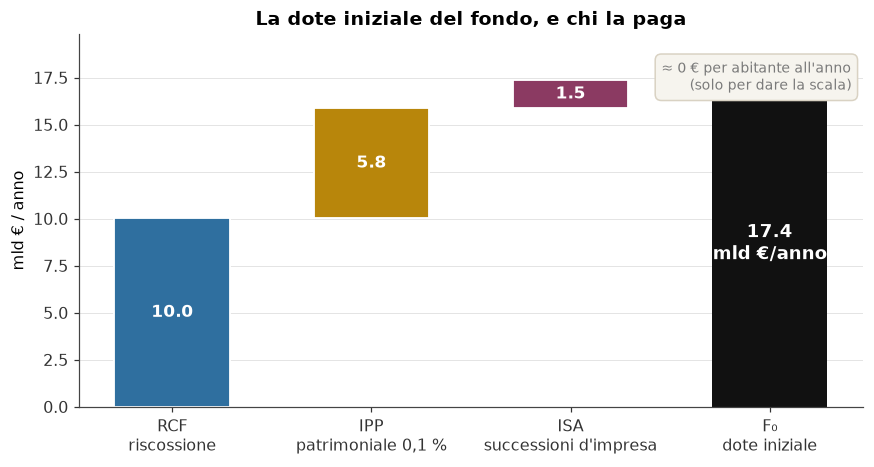

Le tre fonti valgono rispettivamente il 58%, 34% e 9% del totale.
La patrimoniale è la fonte più "solida", la successoria la più volatile.


In [4]:
# ── Chi paga cosa: waterfall della dote iniziale ─────────────────────────────
fig, ax = plt.subplots(figsize=(9.2, 4.4))

nomi = ["RCF\nriscossione", "IPP\npatrimoniale 0,1 %", "ISA\nsuccessioni d'impresa"]
vals = [BASE0["RCF"], BASE0["IPP"], BASE0["ISA"]]
cols = [C["rcf"], C["ipp"], C["isa"]]

bottom = 0.0
for nome, v, col in zip(nomi, vals, cols):
    ax.bar(nome, v, bottom=bottom, color=col, width=0.58, edgecolor="white", linewidth=1.2)
    ax.text(nome, bottom + v / 2, f"{v:.1f}", ha="center", va="center",
            color="white", fontweight="bold", fontsize=11)
    bottom += v

ax.bar("F₀\ndote iniziale", bottom, color=C["tot"], width=0.58)
ax.text(3, bottom / 2, f"{bottom:.1f}\nmld €/anno", ha="center", va="center",
        color="white", fontweight="bold", fontsize=12)

ax.set_ylabel("mld € / anno")
ax.set_title("La dote iniziale del fondo, e chi la paga")
ax.set_ylim(0, bottom * 1.14)
ax.xaxis.grid(False)
ax.spines[["top", "right"]].set_visible(False)
ax.annotate(f"≈ {bottom / 58.9:.0f} € per abitante all'anno\n(solo per dare la scala)",
            xy=(0.985, 0.93), xycoords="axes fraction", ha="right", va="top",
            fontsize=9, color=C["grey"],
            bbox=dict(boxstyle="round,pad=0.45", fc="#f6f4ee", ec="#d9d2c3"))
savefig(fig, "01_waterfall_dote")
plt.show()

print(f"Le tre fonti valgono rispettivamente il "
      f"{BASE0['RCF'] / BASE0['totale']:.0%}, {BASE0['IPP'] / BASE0['totale']:.0%} e "
      f"{BASE0['ISA'] / BASE0['totale']:.0%} del totale.")
print("La patrimoniale è la fonte più \"solida\", la successoria la più volatile.")


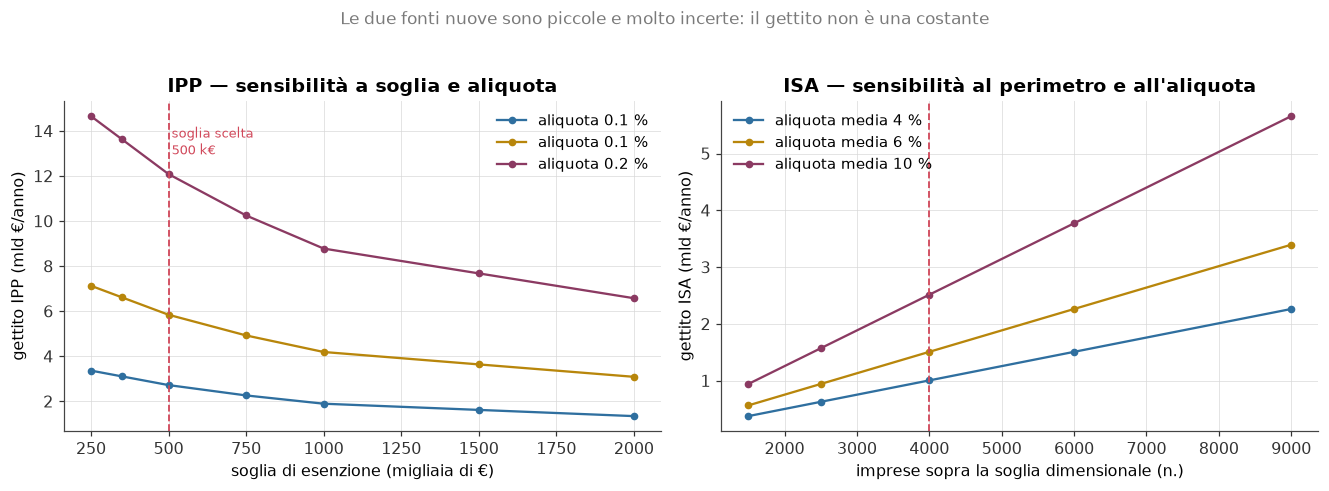

Impatto sulla dote iniziale di un errore del ±50 % su una singola fonte:
  RCF: ± 5.0 mld  →  F₀ tra 12.4 e 22.4 mld
  IPP: ± 2.9 mld  →  F₀ tra 14.5 e 20.3 mld
  ISA: ± 0.8 mld  →  F₀ tra 16.6 e 18.1 mld


In [5]:
# ── Sensibilità: quanto valgono davvero le mani che stiamo mettendo ──────────
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.3))

# (a) IPP — soglia × aliquota
soglie = np.array([250e3, 350e3, 500e3, 750e3, 1e6, 1.5e6, 2e6])
aliquote = [0.0005, 0.001, 0.002]
for al in aliquote:
    y = [(P0["fonti.ipp_ricchezza_netta_mld"] * quota_oltre_soglia(s) * al
          * P0["fonti.ipp_compliance"]) - P0["fonti.ipp_costi_gestione_mld"] for s in soglie]
    axes[0].plot(soglie / 1e3, np.maximum(y, 0), marker="o", ms=4,
                 label=f"aliquota {al * 100:.1f} %")
axes[0].axvline(500, color=C["accent"], ls="--", lw=1.2)
axes[0].text(510, axes[0].get_ylim()[1] * 0.93, "soglia scelta\n500 k€", fontsize=8.5,
             color=C["accent"], va="top")
axes[0].set_xlabel("soglia di esenzione (migliaia di €)")
axes[0].set_ylabel("gettito IPP (mld €/anno)")
axes[0].set_title("IPP — sensibilità a soglia e aliquota")
axes[0].legend(loc="upper right")

# (b) ISA — numero imprese × aliquota
n_imp = np.array([1500, 2500, 4000, 6000, 9000])
for al in [0.04, 0.06, 0.10]:
    y = (n_imp / P0["fonti.isa_anni_ricambio"]) * P0["fonti.isa_valore_medio_partecipazione_mld"] * al
    axes[1].plot(n_imp, y, marker="o", ms=4, label=f"aliquota media {al * 100:.0f} %")
axes[1].axvline(4000, color=C["accent"], ls="--", lw=1.2)
axes[1].set_xlabel("imprese sopra la soglia dimensionale (n.)")
axes[1].set_ylabel("gettito ISA (mld €/anno)")
axes[1].set_title("ISA — sensibilità al perimetro e all'aliquota")
axes[1].legend(loc="upper left")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Le due fonti nuove sono piccole e molto incerte: il gettito non è una costante",
             y=1.03, fontsize=11, color=C["grey"])
plt.tight_layout()
savefig(fig, "02_sensibilita_fonti")
plt.show()

# Quanto pesa un errore del 50 % su ciascuna fonte?
print("Impatto sulla dote iniziale di un errore del ±50 % su una singola fonte:")
for k in ["RCF", "IPP", "ISA"]:
    d = 0.5 * BASE0[k]
    print(f"  {k}: ±{d:4.1f} mld  →  F₀ tra {BASE0['totale'] - d:4.1f} e {BASE0['totale'] + d:4.1f} mld")


## §5 — La dinamica delle entrate: shock, cicli, e il rischio che qualcuno le abolisca

Tre meccanismi, in ordine di importanza.

**1. Il trascinamento del PIL.** Le entrate crescono con l'economia. Il PIL nominale cresce al
2,5 % con volatilità dell'1,2 %; la patrimoniale cresce un po' di più (elasticità 1,2) perché i
patrimoni — soprattutto finanziari — battono il PIL. Non è un dettaglio: su 30 anni l'elasticità
1,2 vs 1,0 vale decine di miliardi.

**2. Lo shock di efficienza del fisco, ±20 %.** Come richiesto: ogni anno il gettito da riscossione
può variare di ±20 % per ragioni operative (organico, turnover dei funzionari, digitalizzazione,
esiti del contenzioso). È un **rumore sul livello**, non cumulativo: un anno storto non penalizza
per sempre. È il modo corretto di modellare un'efficienza amministrativa.

**3. Il rischio politico — il meccanismo che decide tutto.**

Un fondo che poggia su due imposte *nuove* e politicamente contestate è esposto a un rischio che
nessun modello finanziario standard cattura: **la maggioranza successiva le abolisce**. Lo
modelliamo con una **catena di Markov a due stati**:

```
        p(fav→avv) = 8 %/anno
   ┌─────────────┐          ┌─────────────┐
   │ FAVOREVOLE  │ ───────► │   AVVERSA   │
   │   (nessun   │          │  patrimoniale│
   │   rischio)  │ ◄─────── │  e successoria│
   └─────────────┘  p=40 %  │  → ZERO      │
                             └─────────────┘
```

Perché una catena e non tre monete indipendenti? Perché **la stessa maggioranza** abolisce tutte le
sue misure insieme: gli shock sono correlati, e trattarli come indipendenti sottostimerebbe
brutalmente la varianza del risultato. Nel regime avverso: `IPP → 0`, `ISA → 0`, `RCF → 60 %`
(il fisco si indebolisce, ma l'Agenzia delle Entrate non si chiude).

Con `p(fav→avv) = 8 %` e `p(avv→fav) = 40 %`, il regime avverso occupa circa il **17 % del tempo**,
con permanenze medie di ~2,5 anni. Se ti sembra poco: significa che in un orizzonte di 30 anni la
probabilità di attraversare almeno una fase di blackout è vicina al **90 %**. Prova a mettere
`p_fav_a_avv = 0.02` e guarda quanto cambiano i risultati: è la manopola più potente del notebook
dopo il rendimento.


In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# §5 — Percorsi delle entrate fiscali
# ══════════════════════════════════════════════════════════════════════════════

def percorsi_macro(p, n, T, rng):
    """PIL nominale e inflazione. Restituisce array (n, T)."""
    g_mu = _arr(p["macro.gdp_nominale_crescita"], n)
    g_sd = _arr(p["macro.gdp_sigma"], n)
    g = np.clip(g_mu[:, None] + g_sd[:, None] * rng.standard_normal((n, T)),
                p["macro.gdp_floor"], p["macro.gdp_cap"])

    i_mu = _arr(p["macro.inflazione_media"], n)
    i_sd = _arr(p["macro.inflazione_sigma"], n)
    infl = np.clip(i_mu[:, None] + i_sd[:, None] * rng.standard_normal((n, T)),
                   p["macro.inflazione_floor"], p["macro.inflazione_cap"])
    return g, infl


def percorsi_regime(p, n, T, rng):
    """Catena di Markov a due stati. 0 = favorevole, 1 = avversa. Array (n, T)."""
    p_ff = _arr(p["politica.p_fav_a_avv"], n)
    p_rr = _arr(p["politica.p_avv_a_fav"], n)
    stato = np.full(n, int(p["politica.regime_iniziale"]), dtype=np.int8)
    reg = np.zeros((n, T), dtype=np.int8)
    for t in range(T):
        u = rng.random(n)
        vai_avv = (stato == 0) & (u < p_ff)
        torna_fav = (stato == 1) & (u < p_rr)
        stato = np.where(vai_avv, 1, stato)
        stato = np.where(torna_fav, 0, stato)
        reg[:, t] = stato
    return reg


def percorsi_entrate(p, n, T, rng):
    """Le tre fonti anno per anno, in mld €. Tutto vettorizzato su (n, T)."""
    g, infl = percorsi_macro(p, n, T, rng)
    reg = percorsi_regime(p, n, T, rng)
    _abol = int(p.get("politica.anno_abolizione", -1))
    if _abol > 0:
        reg[:, max(_abol - 1, 0):] = 1        # abolizione certa e permanente
    b = livelli_base(p, n)

    # moltiplicatori di regime
    m_rcf = np.where(reg == 1, _arr(p["fonti.rcf_moltiplicatore_regime_avverso"], n)[:, None], 1.0)
    m_ipp = np.where(reg == 1, _arr(p["fonti.ipp_moltiplicatore_regime_avverso"], n)[:, None], 1.0)
    m_isa = np.where(reg == 1, _arr(p["fonti.isa_moltiplicatore_regime_avverso"], n)[:, None], 1.0)

    # crescita cumulata (indice anno t = 1, 2, ... perché l'anno 0 è già in F₀)
    cum_rcf = np.cumprod(1.0 + g * _arr(p["fonti.rcf_elasticita_pil"], n)[:, None], axis=1)
    cum_ipp = np.cumprod(1.0 + g * _arr(p["fonti.ipp_elasticita_pil"], n)[:, None], axis=1)
    cum_isa = np.cumprod(1.0 + g * _arr(p["fonti.isa_elasticita_pil"], n)[:, None], axis=1)

    # shock di efficienza del fisco: uniforme ±20 %, sul livello, non cumulativo
    s_rcf = _arr(p["fonti.rcf_shock_efficienza"], n)[:, None]
    u = rng.uniform(-1.0, 1.0, (n, T))
    eff = 1.0 + s_rcf * u

    RCF = b["RCF"][:, None] * cum_rcf * eff * m_rcf

    IPP_lordo = b["IPP_lordo"][:, None] * cum_ipp
    IPP = np.maximum(IPP_lordo - _arr(p["fonti.ipp_costi_gestione_mld"], n)[:, None], 0.0) * m_ipp

    # ISA: componente regolare × irregolarità (Poisson-composto approssimato
    # con una lognormale a media 1, così il valore atteso resta quello di base)
    lam = _arr(p["fonti.isa_lumpiness"], n)[:, None]
    lump = np.exp(rng.normal(0.0, 1.0, (n, T)) * lam - 0.5 * lam ** 2)
    ISA = b["ISA"][:, None] * cum_isa * lump * m_isa

    # rumore residuo sul totale, applicato in modo proporzionale per mantenere
    # l'additività: I = RCF + IPP + ISA esattamente.
    s_tot = rng.normal(0.0, _arr(p["politica.shock_entrate_sigma"], n)[:, None], (n, T))
    scala = np.maximum(1.0 + s_tot, 0.05)
    RCF, IPP, ISA = RCF * scala, IPP * scala, ISA * scala

    return {
        "RCF": RCF, "IPP": IPP, "ISA": ISA,
        "I": RCF + IPP + ISA, "g": g, "infl": infl, "regime": reg,
    }


# ── verifica rapida ─────────────────────────────────────────────────────────
_t0 = time.time()
_chk = percorsi_entrate(P0, 4000, CFG.sim.anni, np.random.default_rng(1))
print(f"Simulazione di prova: {_chk['I'].shape[0]} percorsi × {_chk['I'].shape[1]} anni "
      f"in {time.time() - _t0:.2f} s")

_anni = np.arange(1, CFG.sim.anni + 1)
_tab = pd.DataFrame({
    "mediana": np.median(_chk["I"], axis=0),
    "P10": np.quantile(_chk["I"], 0.10, axis=0),
    "P90": np.quantile(_chk["I"], 0.90, axis=0),
    "P(I = 0)": np.mean(_chk["I"] < 0.5, axis=0),
}, index=_anni)

print(f"\nEntrate totali: mediana anno 1 = {np.median(_chk['I'][:, 0]):.1f} mld, "
      f"anno 30 = {np.median(_chk['I'][:, 29]):.1f} mld")
print(f"Quota di percorsi in regime avverso in un anno qualsiasi: "
      f"{_chk['regime'].mean():.1%}")
print(f"Probabilità di attraversare almeno un blackout entro 30 anni: "
      f"{np.mean(_chk['regime'][:, :30].max(axis=1) == 1):.1%}")

_tab.iloc[[0, 4, 9, 19, 29]].round(2)


Simulazione di prova: 4000 percorsi × 50 anni in 0.02 s

Entrate totali: mediana anno 1 = 17.4 mld, anno 30 = 37.2 mld
Quota di percorsi in regime avverso in un anno qualsiasi: 16.3%
Probabilità di attraversare almeno un blackout entro 30 anni: 92.4%


,mediana,P10,P90,P(I = 0)
1,17.38,13.27,20.66,0.0
5,19.07,7.20,22.91,0.0
10,21.80,8.00,26.33,0.0
20,28.48,10.17,34.57,0.0
30,37.23,13.03,45.20,0.0


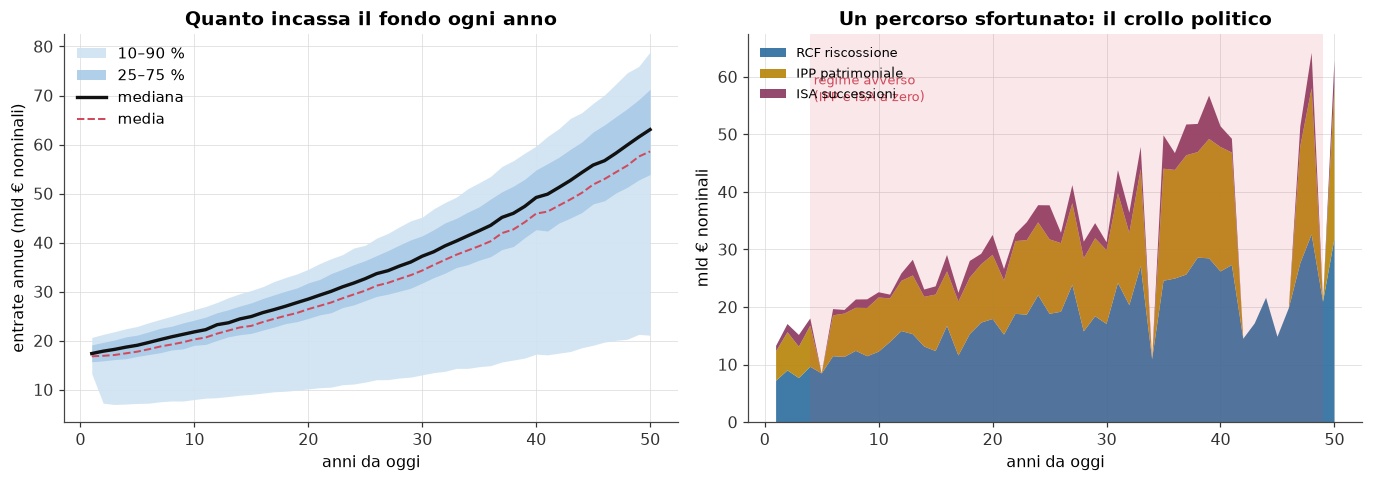

rischio basso (1 %/anno)    : entrate cumulate a 30 anni, mediana =      801 mld nominali
base (8 %/anno)             : entrate cumulate a 30 anni, mediana =      732 mld nominali
rischio alto (20 %/anno)    : entrate cumulate a 30 anni, mediana =      635 mld nominali


In [7]:
# ── Ventaglio delle entrate + un percorso esemplificativo ───────────────────
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.5))

ax = axes[0]
x = _anni
for lo, hi, col, lab in [(0.10, 0.90, C["band1"], "10–90 %"),
                         (0.25, 0.75, C["band2"], "25–75 %")]:
    ax.fill_between(x, np.quantile(_chk["I"], lo, axis=0), np.quantile(_chk["I"], hi, axis=0),
                    color=col, alpha=0.9, lw=0, label=lab)
ax.plot(x, np.median(_chk["I"], axis=0), color=C["tot"], lw=2.2, label="mediana")
ax.plot(x, np.mean(_chk["I"], axis=0), color=C["accent"], lw=1.3, ls="--", label="media")
ax.set_xlabel("anni da oggi")
ax.set_ylabel("entrate annue (mld € nominali)")
ax.set_title("Quanto incassa il fondo ogni anno")
ax.legend(loc="upper left", ncol=1)
ax.spines[["top", "right"]].set_visible(False)

# percorso esemplificativo: primo percorso che attraversa un blackout
j = int(np.argmax(_chk["regime"].max(axis=1) == 1))
ax = axes[1]
ax.stackplot(x, _chk["RCF"][j], _chk["IPP"][j], _chk["ISA"][j],
             labels=["RCF riscossione", "IPP patrimoniale", "ISA successioni"],
             colors=[C["rcf"], C["ipp"], C["isa"]], alpha=0.92, lw=0)
bl = np.where(_chk["regime"][j] == 1)[0]
if len(bl):
    ax.axvspan(bl.min(), bl.max() + 1, color=C["accent"], alpha=0.13, lw=0)
    ax.text(bl.min() + 0.3, ax.get_ylim()[1] * 0.9,
            "regime avverso\n(IPP e ISA a zero)", fontsize=8.5, color=C["accent"], va="top")
ax.set_xlabel("anni da oggi")
ax.set_ylabel("mld € nominali")
ax.set_title("Un percorso sfortunato: il crollo politico")
ax.legend(loc="upper left", fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
savefig(fig, "03_entrate")
plt.show()

# Quanto vale il rischio politico in termini attesi?
_p_basso = {**P0, "politica.p_fav_a_avv": 0.01}
_p_alto = {**P0, "politica.p_fav_a_avv": 0.20}
for nome, pp in [("rischio basso (1 %/anno)", _p_basso), ("base (8 %/anno)", P0), ("rischio alto (20 %/anno)", _p_alto)]:
    r = percorsi_entrate(pp, 3000, 30, np.random.default_rng(7))
    tot = np.median(r["I"].sum(axis=1))
    print(f"{nome:28s}: entrate cumulate a 30 anni, mediana = {tot:8.0f} mld nominali")


## §6 — Dove mette i soldi: il paniere delle partecipate

### 6.1 Il paniere

Il fondo investe in una selezione di società **partecipate dallo Stato** (via MEF o Cassa Depositi
e Prestiti), concentrate su energia e trasporti come richiesto, con due innesti: Poste (servizi) e
Leonardo (difesa). I pesi sono scelti per **non** essere una scommessa su un singolo titolo:
nessuna posizione sopra il 22 %.

| Titolo | Peso | μ nominale | σ | Quota pubblica | Nota |
|---|---|---|---|---|---|
| **ENEL** | 22 % | 8,0 % | 22 % | ~23,6 % (MEF) | utility regolata, dividendo alto |
| **ENI** | 18 % | 7,2 % | 25 % | ~9,2 % (MEF+CDP) | petrolifero, ciclico |
| **Poste Italiane** | 12 % | 7,5 % | 22 % | ~64,3 % (MEF+CDP) | già a controllo pubblico |
| **Terna** | 10 % | 6,8 % | 17 % | ~29,9 % (CDP) | rete elettrica, bassa beta |
| **Snam** | 10 % | 6,5 % | 19 % | ~30,9 % (CDP) | gasdotti, regolata |
| **Leonardo** | 8 % | 10,0 % | 33 % | ~30,2 % (MEF) | difesa, alta volatilità |
| **FS / Trenitalia** | 12 % | 5,5 % | 20 % | 100 % (MEF) | **non quotata** → serie sintetica |
| **TIM rete (NetCo)** | 8 % | 5,5 % | 28 % | ~0 (KKR, CDP ~10 %) | **non quotata** → serie sintetica |

**Le due eccezioni, dichiarate.** *Trenitalia* non è quotata: è dentro il gruppo Ferrovie dello
Stato, 100 % MEF. *La rete TIM* (NetCo) è stata venduta a KKR nel 2024 e non è quotata. Per queste
due costruiamo una **serie sintetica** (inflazione + crescita reale + dividendo, con volatilità più
alta per la rete) e lo diciamo chiaramente: sono stime, non dati. Verranno sostituite con i bilanci
quando avremo voglia di raffinare il modello.

### 6.2 I rendimenti sono nominali e total return

`μ` sono rendimenti **nominali**, **al lordo delle commissioni**, **con dividendi reinvestiti**.
Sono medie di lungo periodo prudenti: ENEL ed ENI hanno reso storicamente il 6-9 % nominale con
dividendi reinvestiti, ma includere gli anni d'oro del 2005-2007 sarebbe barare. Il rendimento
realizzato in eccesso rispetto ai BTP è ciò che paga il rischio: se il fondo rende come i BTP,
non ha senso comprare azioni.

### 6.3 Il prior è volutamente pessimista

Il μ di portafoglio implicito nei pesi è ≈ **7,2 % nominale**. Nel modello il prior sul rendimento
atteso è centrato a **5,5 %**, cioè un **haircut del 20 %**: un fondo pubblico che compra grandi
pacchetti con impatto di mercato, paga commissioni e deve giustificare i risultati non può
ragionevolmente attendersi il rendimento storico pieno. L'MCMC aggiornerà questa convinzione con
i dati, ma parte da lì.

### 6.4 Correlazione: perché non si diversifica più di tanto

Otto titoli italiani dello stesso settore, con lo stesso Stato come azionista di riferimento, si
muovono insieme. Una correlazione media di **0,55** è realistica e va detta: il paniere riduce la
volatilità idiosincratica ma **non** il rischio di scenario (una crisi energetica o uno shock sui
tassi colpisce tutti insieme). Chi racconta che il fondo "diversifica" sta vendendo fumo.


In [8]:
# ══════════════════════════════════════════════════════════════════════════════
# §6 — Paniere, correlazioni, rendimenti
# ══════════════════════════════════════════════════════════════════════════════

BASKET = pd.DataFrame([
    dict(titolo="ENEL",               peso=0.22, mu=0.080, sigma=0.22, quota_pubblica=0.236, quotata=True,
         nota="utility regolata, dividendo elevato"),
    dict(titolo="ENI",                peso=0.18, mu=0.072, sigma=0.25, quota_pubblica=0.092, quotata=True,
         nota="petrolifero, ciclico"),
    dict(titolo="Poste Italiane",     peso=0.12, mu=0.075, sigma=0.22, quota_pubblica=0.643, quotata=True,
         nota="servizi, già a controllo pubblico"),
    dict(titolo="Terna",              peso=0.10, mu=0.068, sigma=0.17, quota_pubblica=0.299, quotata=True,
         nota="rete elettrica, bassa beta"),
    dict(titolo="Snam",               peso=0.10, mu=0.065, sigma=0.19, quota_pubblica=0.309, quotata=True,
         nota="gasdotti, regolata"),
    dict(titolo="Leonardo",           peso=0.08, mu=0.100, sigma=0.33, quota_pubblica=0.302, quotata=True,
         nota="difesa, alta volatilità"),
    dict(titolo="FS / Trenitalia",    peso=0.12, mu=0.055, sigma=0.20, quota_pubblica=1.000, quotata=False,
         nota="NON quotata → serie sintetica"),
    dict(titolo="TIM rete (NetCo)",   peso=0.08, mu=0.055, sigma=0.28, quota_pubblica=0.000, quotata=False,
         nota="NON quotata (KKR) → serie sintetica"),
]).set_index("titolo")

assert abs(BASKET["peso"].sum() - 1.0) < 1e-9, "i pesi devono sommare a 1"

RHO = 0.55  # correlazione media tra i titoli del paniere

mu_paniere = float((BASKET["peso"] * BASKET["mu"]).sum())
w = BASKET["peso"].to_numpy()
s = BASKET["sigma"].to_numpy()
var_paniere = RHO * (w * s).sum() ** 2 + (1 - RHO) * (w ** 2 * s ** 2).sum()
sigma_paniere = float(np.sqrt(var_paniere))

display(BASKET.style.format({"peso": "{:.0%}", "mu": "{:.1%}", "sigma": "{:.1%}",
                             "quota_pubblica": "{:.1%}"}))

print(f"μ di portafoglio (pesi × μ)        : {mu_paniere:6.2%} nominale")
print(f"σ di portafoglio (ρ = {RHO:.2f})        : {sigma_paniere:6.2%}")
print(f"μ usato nel modello (prudenziale)  : {CFG.mercati.drift_atteso:.2%} nominale "
      f"(haircut {(1 - CFG.mercati.drift_atteso / mu_paniere):.0%})")
print(f"  → in termini reali (infl. 2 %)    : {(1 + CFG.mercati.drift_atteso) / 1.02 - 1:.2%}")
print(f"  → premio per il rischio vs BTP    : {CFG.mercati.drift_atteso - CFG.mercati.btp_yield_lungo:.2%}")


,peso,mu,sigma,quota_pubblica,quotata,nota
titolo,,,,,,
ENEL,22%,8.0%,22.0%,23.6%,True,"utility regolata, dividendo elevato"
ENI,18%,7.2%,25.0%,9.2%,True,"petrolifero, ciclico"
Poste Italiane,12%,7.5%,22.0%,64.3%,True,"servizi, già a controllo pubblico"
Terna,10%,6.8%,17.0%,29.9%,True,"rete elettrica, bassa beta"
Snam,10%,6.5%,19.0%,30.9%,True,"gasdotti, regolata"
Leonardo,8%,10.0%,33.0%,30.2%,True,"difesa, alta volatilità"
FS / Trenitalia,12%,5.5%,20.0%,100.0%,False,NON quotata → serie sintetica
TIM rete (NetCo),8%,5.5%,28.0%,0.0%,False,NON quotata (KKR) → serie sintetica


μ di portafoglio (pesi × μ)        :  7.19% nominale
σ di portafoglio (ρ = 0.55)        : 17.92%
μ usato nel modello (prudenziale)  : 5.50% nominale (haircut 23%)
  → in termini reali (infl. 2 %)    : 3.43%
  → premio per il rischio vs BTP    : 2.00%


α nominale: mediana 5.35%, media 5.32%, σ 20.63%, P5 -26.91%, P95 37.50%
α reale   : mediana 3.26%


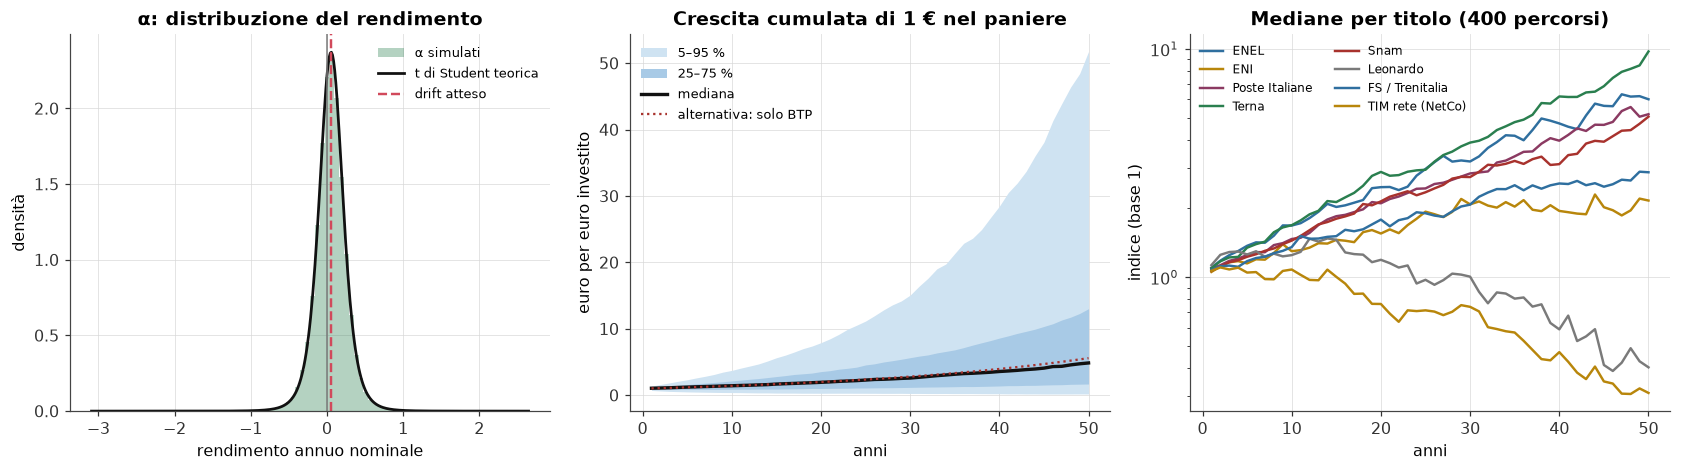

In [9]:
# ── α_t: il rendimento annuo del portafoglio ────────────────────────────────

def percorsi_alpha(p, n, T, rng, infl):
    """Rendimento NOMINALE annuo del portafoglio, al netto delle commissioni.
    Due modalità:
      t_student → α = drift + σ·t(ν)          [default: prudente, code grasse]
      uniform   → α reale = drift + hw·U(−1,1), poi convertito in nominale
    """
    if p["mercati.alpha_mode"] == "uniform":
        drift_r = _arr(p["mercati.uniform_drift_reale"], n)[:, None]
        hw = _arr(p["mercati.uniform_semilarghezza_reale"], n)[:, None]
        a_reale = drift_r + hw * rng.uniform(-1.0, 1.0, (n, T))
        alpha = (1.0 + a_reale) * (1.0 + infl) - 1.0
    else:
        drift = _arr(p["mercati.drift_atteso"], n)[:, None]
        sd = _arr(p["mercati.sigma_alpha"], n)[:, None]
        nu = float(p["mercati.t_nu"])
        alpha = drift + sd * rng.standard_t(nu, size=(n, T))
    return alpha - _arr(p["mercati.fee_gestione"], n)[:, None]


def percorsi_titoli(n, T, rng, rho=RHO):
    """Percorsi per singolo titolo (solo per i grafici della §6)."""
    A = len(BASKET)
    R = np.full((A, A), rho) + (1 - rho) * np.eye(A)
    L = np.linalg.cholesky(R)
    z = rng.standard_normal((n, T, A)) @ L.T
    z = z / np.sqrt(rng.chisquare(5.0, size=(n, T, 1)) / 5.0)   # t di Student
    r = BASKET["mu"].to_numpy() + BASKET["sigma"].to_numpy() * z
    return np.cumprod(1 + r, axis=1)   # indice di valore, base 1


_rng_a = np.random.default_rng(2)
_infl_a = percorsi_macro(P0, 6000, CFG.sim.anni, _rng_a)[1]
_AL = percorsi_alpha(P0, 6000, CFG.sim.anni, _rng_a, _infl_a)
print(f"α nominale: mediana {np.median(_AL):.2%}, media {_AL.mean():.2%}, "
      f"σ {_AL.std():.2%}, P5 {np.quantile(_AL, 0.05):.2%}, P95 {np.quantile(_AL, 0.95):.2%}")
print(f"α reale   : mediana {np.median((1 + _AL) / (1 + _infl_a) - 1):.2%}")

fig, axes = plt.subplots(1, 3, figsize=(15.4, 4.4))

# (a) distribuzione di α
ax = axes[0]
ax.hist(_AL.ravel(), bins=90, density=True, color=C["equity"], alpha=0.35, label="α simulati")
xs = np.linspace(_AL.min(), _AL.max(), 400)
ax.plot(xs, stats.t.pdf(xs, CFG.mercati.t_nu, loc=CFG.mercati.drift_atteso,
                        scale=CFG.mercati.sigma_alpha), color=C["tot"], lw=1.8, label="t di Student teorica")
ax.axvline(CFG.mercati.drift_atteso, color=C["accent"], lw=1.6, ls="--", label="drift atteso")
ax.axvline(0, color=C["grey"], lw=1)
ax.set_xlabel("rendimento annuo nominale")
ax.set_ylabel("densità")
ax.set_title("α: distribuzione del rendimento")
ax.legend(fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

# (b) ventaglio del rendimento cumulato
ax = axes[1]
cum = np.cumprod(1 + _AL, axis=1)
x = np.arange(1, CFG.sim.anni + 1)
ax.fill_between(x, np.quantile(cum, 0.05, axis=0), np.quantile(cum, 0.95, axis=0),
                color=C["band1"], lw=0, label="5–95 %")
ax.fill_between(x, np.quantile(cum, 0.25, axis=0), np.quantile(cum, 0.75, axis=0),
                color=C["band2"], lw=0, label="25–75 %")
ax.plot(x, np.median(cum, axis=0), color=C["tot"], lw=2.2, label="mediana")
ax.plot(x, np.cumprod(np.full(CFG.sim.anni, 1 + CFG.mercati.btp_yield_lungo)), color=C["btp"],
        lw=1.5, ls=":", label="alternativa: solo BTP")
ax.set_xlabel("anni")
ax.set_ylabel("euro per euro investito")
ax.set_title("Crescita cumulata di 1 € nel paniere")
ax.legend(fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

# (c) percorsi per titolo
ax = axes[2]
paths = percorsi_titoli(400, CFG.sim.anni, np.random.default_rng(3))
for i, t in enumerate(BASKET.index):
    ax.plot(np.arange(1, CFG.sim.anni + 1), np.median(paths[:, :, i], axis=0),
            lw=1.6, label=t)
ax.set_xlabel("anni")
ax.set_ylabel("indice (base 1)")
ax.set_title("Mediane per titolo (400 percorsi)")
ax.legend(fontsize=7.6, ncol=2, loc="upper left")
ax.set_yscale("log")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
savefig(fig, "04_rendimenti")
plt.show()


## §7 — La gamba BTP, e la trappola contabile che nessuno racconta

### 7.1 Modello dei tassi

Il tasso BTP a 10 anni segue un processo **mean-reverting** (Ornstein-Uhlenbeck, in tempo discreto):

$$y_{t+1} = y_t + \kappa\,(\bar{y} - y_t) + \sigma_y\,\varepsilon_t, \qquad \kappa = 0{,}25,\ \bar{y} = 3{,}5\%,\ \sigma_y = 1{,}1\%$$

Cioè: i tassi tornano verso il 3,5 % con memoria di ~4 anni, ma possono stare lontani per anni —
è esattamente quello che è successo tra il 2011 e il 2022. Il rendimento totale del portafoglio
obbligazionario non è la cedola: è cedola **più** variazione di prezzo:

$$r^{\text{BTP}}_t \approx y_t - D\,\Delta y_t + \tfrac{1}{2} C\,(\Delta y_t)^2,\qquad D = 7{,}5,\ C = 0{,}70$$

La **duration** è il punto: se i tassi salgono dell'1 %, il fondo perde il 7,5 % del capitale
investito in BTP. Un fondo che compra BTP a 30 anni per "incassare i tassi" sta scommettendo sui
tassi, non facendo una scelta prudente. Le cedole non sono gratis: il rischio è sul capitale.

### 7.2 Tre politiche di allocazione

| Politica | φ | A cosa serve |
|---|---|---|
| `constant` | 30 %, costante | caso base prudente |
| `glide` | da 30 % a 60 % in 15 anni | "progressiva sostituzione del debito privato" |
| `equity_only` | 0 % | per confronto: quanto costa rinunciare alle cedole |

### 7.3 Il punto scomodo: comprare BTP non riduce il debito pubblico

Questa è la parte che di solito sparisce dalle presentazioni politiche.

Il fondo è **pubblico**. Quando compra un BTP sul secondario, il Tesoro non incassa nulla: il
titolo cambia semplicemente proprietario. Lo Stato continua a pagare la stessa cedola, solo a
un creditore diverso — sé stesso, per interposta persona. **Nel bilancio consolidato del settore
pubblico, debito e credito si elidono: il debito netto non scende di un euro.**

Il beneficio reale esiste, ma solo su due canali:

1. **La quota detenuta da non residenti (~27 %).** Su quella parte, la cedola esce dal Paese. Se il
   fondo la ricompra, quella cedola resta in Italia: è un vero trasferimento di ricchezza
   dall'estero al contribuente italiano. Su 800 mld di debito estero al 3,5 %, sono ~28 mld/anno
   di interessi che smettono di uscire — ma servono decenni per ricomprarli tutti.
2. **La riduzione dello spread.** Un creditore stabile e domestico riduce la volatilità dei prezzi
   e quindi il premio di rischio richiesto dal mercato. Questo è il vero guadagno strategico, ed è
   anche il più difficile da quantificare con onestà: dipende dalla credibilità, non dalla size.

Il modello calcola entrambi e li tiene separati. Nel grafico sotto: la linea nera è l'attivo del
fondo (`F_t`, il numero che fa scena), la linea rossa è il **valore netto creato** per il settore
pubblico — molto più piccola, e molto più onesta.


Rendimento BTP: media 3.54%, σ 9.38%, P5 -11.87%, P95 19.02%
Anni con rendimento BTP totale NEGATIVO (effetto prezzo): 35.2% — la cedola c'è sempre, ma il capitale oscilla.


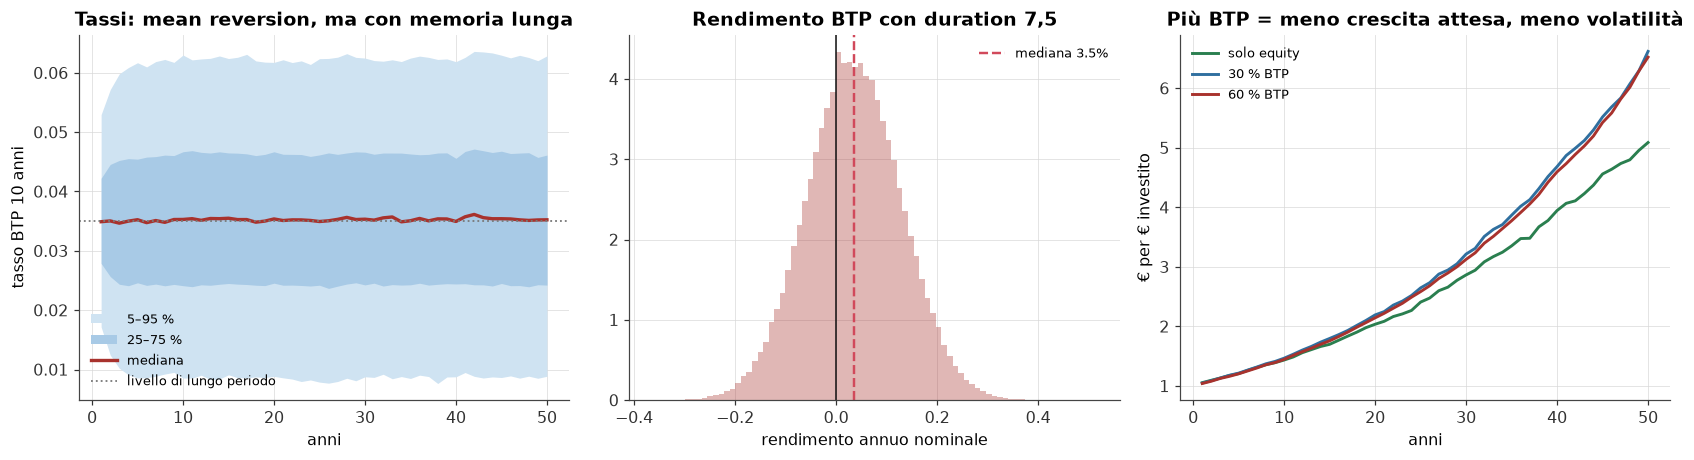

In [10]:
# ══════════════════════════════════════════════════════════════════════════════
# §7 — BTP: tassi, duration, allocazione
# ══════════════════════════════════════════════════════════════════════════════

def quota_btp(p, T, n=None):
    """Quota obbligazionaria anno per anno → array (T,)."""
    pol = p["mercati.btp_politica"]
    q0 = float(p["mercati.btp_quota"])
    if pol == "equity_only":
        return np.zeros(T)
    if pol == "glide":
        q1 = float(p["mercati.btp_quota_max"])
        k = float(p["mercati.btp_anni_glide"])
        return np.clip(q0 + (q1 - q0) * np.arange(T) / max(k, 1), 0, 1)
    return np.full(T, q0)


def percorsi_btp(p, n, T, rng):
    """Rendimento NOMINALE annuo di un portafoglio BTP con duration.
    Restituisce (n, T) più il percorso dei tassi (n, T+1)."""
    theta = _arr(p["mercati.btp_yield_lungo"], n)[:, None]
    kappa = float(p["mercati.btp_ou_kappa"])
    sd = float(p["mercati.btp_ou_sigma"])
    D = float(p["mercati.btp_duration"])
    Cx = float(p["mercati.btp_convessita"])

    y = np.empty((n, T + 1))
    y[:, 0] = theta[:, 0]                      # si parte dal livello di lungo periodo
    eps = rng.standard_normal((n, T))
    for t in range(T):
        dy = kappa * (theta[:, 0] - y[:, t]) + sd * eps[:, t]
        if int(p["mercati.spread_shock_anno"]) == t + 1:
            dy = dy + float(p["mercati.spread_shock_bp"]) / 10_000.0
        y[:, t + 1] = np.clip(y[:, t] + dy, 0.001, 0.20)

    dy = np.diff(y, axis=1)
    r = y[:, :-1] - D * dy + 0.5 * Cx * dy ** 2
    return r, y


# ── diagnostica ─────────────────────────────────────────────────────────────
_btp_ret, _y = percorsi_btp(P0, 6000, CFG.sim.anni, np.random.default_rng(4))
print(f"Rendimento BTP: media {_btp_ret.mean():.2%}, σ {_btp_ret.std():.2%}, "
      f"P5 {np.quantile(_btp_ret, 0.05):.2%}, P95 {np.quantile(_btp_ret, 0.95):.2%}")
print(f"Anni con rendimento BTP totale NEGATIVO (effetto prezzo): "
      f"{np.mean(_btp_ret < 0):.1%} — la cedola c'è sempre, ma il capitale oscilla.")

fig, axes = plt.subplots(1, 3, figsize=(15.4, 4.3))
x = np.arange(1, CFG.sim.anni + 1)

ax = axes[0]
ax.fill_between(x, np.quantile(_y[:, 1:], 0.05, axis=0), np.quantile(_y[:, 1:], 0.95, axis=0),
                color=C["band1"], lw=0, label="5–95 %")
ax.fill_between(x, np.quantile(_y[:, 1:], 0.25, axis=0), np.quantile(_y[:, 1:], 0.75, axis=0),
                color=C["band2"], lw=0, label="25–75 %")
ax.plot(x, np.median(_y[:, 1:], axis=0), color=C["btp"], lw=2.2, label="mediana")
ax.axhline(CFG.mercati.btp_yield_lungo, color=C["grey"], ls=":", lw=1.2, label="livello di lungo periodo")
ax.set_xlabel("anni")
ax.set_ylabel("tasso BTP 10 anni")
ax.set_title("Tassi: mean reversion, ma con memoria lunga")
ax.legend(fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
ax.hist(_btp_ret.ravel(), bins=80, density=True, color=C["btp"], alpha=0.35)
ax.axvline(0, color=C["tot"], lw=1)
ax.axvline(np.median(_btp_ret), color=C["accent"], lw=1.6, ls="--",
           label=f"mediana {np.median(_btp_ret):.1%}")
ax.set_xlabel("rendimento annuo nominale")
ax.set_title("Rendimento BTP con duration 7,5")
ax.legend(fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

ax = axes[2]
for pol, lab, col in [(0.0, "solo equity", C["equity"]), (0.30, "30 % BTP", C["rcf"]),
                      (0.60, "60 % BTP", C["btp"])]:
    al = percorsi_alpha(P0, 3000, CFG.sim.anni, np.random.default_rng(5), _infl_a[:3000])
    port = pol * _btp_ret[:3000] + (1 - pol) * al
    ax.plot(x, np.median(np.cumprod(1 + port, axis=1), axis=0), lw=1.9, color=col, label=lab)
ax.set_xlabel("anni")
ax.set_ylabel("€ per € investito")
ax.set_title("Più BTP = meno crescita attesa, meno volatilità")
ax.legend(fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
savefig(fig, "05_btp")
plt.show()


## §8 — La ricorsione: l'interesse composto non è magia

Il cuore del modello sta in una riga sola:

$$F_{t+1} = \big(F_t + I_t - D_t\big)\cdot(1 + \alpha_t)$$

dove `I_t` sono gli afflussi fiscali, `D_t` il dividendo sociale e `α_t` il rendimento del
portafoglio (equity + BTP, al netto di commissioni). Sembra banale, ma contiene tutta la sostanza:

- **Il rendimento si applica anche agli afflussi.** Un euro incassato nel 2040 lavora per 10 anni,
  uno incassato nel 2026 per 25. L'ordine temporale conta enormemente.
- **Il dividendo sociale sottrae capitale *prima* che cresca.** È una scelta politica, non tecnica,
  e per questo ha una sezione dedicata (§11).
- **`D_t` dipende dal confronto con la traiettoria attesa.** La regola di default distribuisce il
  30 % del surplus rispetto al percorso deterministico di base: è la traduzione letterale di
  «se ci sono residui perché le cose vanno meglio del previsto, stacca un dividendo sociale».

### La traiettoria di riferimento

Per definire «meglio del previsto» serve un *previsto*. Lo costruiamo come il percorso
**deterministico**: nessuno shock, nessun regime avverso, crescita al valore medio, rendimento
atteso. È il sentiero che il fondo seguirebbe se tutto andasse come da piano. I residui sono
`F_t − F_t^{base}`, e su quelli si calcola il dividendo.

Questo ha un effetto importante e voluto: **in un anno qualsiasi, circa metà dei mondi non
distribuisce nulla** — la mediana del dividendo è zero. Nell'86 % dei mondi, però, si distribuisce
qualcosa almeno una volta in 30 anni: non è «mai», è «a intermittenza». Un mondo in cui la
patrimoniale viene abolita nel 2031 non solo ha meno soldi: non distribuisce nulla, perché non ha
mai superato il piano.


In [11]:
# ══════════════════════════════════════════════════════════════════════════════
# §8 — Il simulatore del fondo
# ══════════════════════════════════════════════════════════════════════════════

def rendimento_atteso(p):
    """Rendimento nominale atteso del portafoglio (per la traiettoria di riferimento)."""
    if p["mercati.alpha_mode"] == "uniform":
        a_reale = float(p["mercati.uniform_drift_reale"])
        a_nom = (1 + a_reale) * (1 + float(p["macro.inflazione_media"])) - 1
    else:
        a_nom = float(p["mercati.drift_atteso"])
    return a_nom - float(p["mercati.fee_gestione"])


def _media_param(p):
    """Riduce i parametri (che possono essere vettori per-path) al loro valore medio.
    Serve per la traiettoria di riferimento: il 'piano' è costruito sui valori attesi."""
    out = {}
    for k, v in p.items():
        if isinstance(v, (bool, str)):
            out[k] = v
        elif isinstance(v, np.ndarray):
            out[k] = float(np.mean(v)) if v.size > 1 else float(v.ravel()[0])
        else:
            out[k] = float(v)
    return out


def fondo_baseline(p, T):
    """Traiettoria deterministica: il 'previsto' rispetto al quale si misura il surplus."""
    p = _media_param(p)
    b = livelli_base(p, 1)
    g = float(p["macro.gdp_nominale_crescita"]) - float(p["spesa.sconto_baseline_crescita"])
    slip = float(p["mercati.slippage_su_afflussi"])
    a = rendimento_atteso(p) - float(p["spesa.sconto_baseline_rendimento"])
    e_rcf = float(p["fonti.rcf_elasticita_pil"])
    e_ipp = float(p["fonti.ipp_elasticita_pil"])
    e_isa = float(p["fonti.isa_elasticita_pil"])

    F = np.zeros(T + 1)
    F[0] = _sc(b["totale"])
    for t in range(T):
        s = t + 1
        I = (_sc(b["RCF"]) * (1 + g) ** (s * e_rcf)
             + _sc(b["IPP"]) * (1 + g) ** (s * e_ipp)
             + _sc(b["ISA"]) * (1 + g) ** (s * e_isa)) * (1 - slip)
        F[t + 1] = (F[t] + I) * (1 + a)
    return F


def simula_fondo(p, n, T, rng, dividendo=True, baseline=None):
    """Simulazione completa. Restituisce un dizionario di array (n, T) e (n, T+1)."""
    ent = percorsi_entrate(p, n, T, rng)
    alpha = percorsi_alpha(p, n, T, rng, ent["infl"])
    r_btp, y_btp = percorsi_btp(p, n, T, rng)

    phi = quota_btp(p, T)
    port = phi[None, :] * r_btp + (1 - phi[None, :]) * alpha      # (n, T)

    slip = float(p["mercati.slippage_su_afflussi"])
    I = ent["I"] * (1 - slip)
    F0 = livelli_base(p, n)["totale"]          # vettore (n,): il gettito varia per percorso

    if baseline is None:
        baseline = fondo_baseline(p, T)

    regola = p["spesa.regola"]
    payout = float(p["spesa.payout_quota"])
    cap = float(p["spesa.payout_max_nav"])
    t0 = int(p["spesa.anno_inizio"])
    qfissa = float(p["spesa.quota_nav_fissa"])

    F = np.zeros((n, T + 1))
    D = np.zeros((n, T))
    F[:, 0] = F0

    for t in range(T):
        disponibile = F[:, t] + I[:, t]
        if dividendo and t >= t0:
            if regola == "eccesso_su_baseline":
                surplus = np.maximum(F[:, t] - baseline[t], 0.0)
                D[:, t] = np.minimum(payout * surplus, cap * F[:, t])
            elif regola == "quota_nav":
                D[:, t] = qfissa * F[:, t]
        F[:, t + 1] = (disponibile - D[:, t]) * (1 + port[:, t])

    idx = np.cumprod(1 + ent["infl"], axis=1)                      # (n, T)
    idx_full = np.concatenate([np.ones((n, 1)), idx], axis=1)
    F_reale = F / idx_full
    D_reale = D / idx

    return {
        "F": F, "F_reale": F_reale, "D": D, "D_reale": D_reale,
        "I": I, "port": port, "alpha": alpha, "r_btp": r_btp, "y_btp": y_btp,
        "phi": phi, "ent": ent, "infl": ent["infl"], "idx": idx,
        "baseline": baseline, "F0": F0,
    }


# ── prova su un percorso singolo, commentato anno per anno ───────────────────
_rng1 = np.random.default_rng(11)
_S1 = simula_fondo(P0, 1, 20, _rng1)
_base = fondo_baseline(P0, 20)

righe = []
for t in range(0, 20):
    righe.append({
        "anno": 2026 + t,
        "entrate I_t": _S1["I"][0, t],
        "F_t inizio": _S1["F"][0, t],
        "dividendo D_t": _S1["D"][0, t],
        "rendimento α_t": _S1["port"][0, t],
        "F_t+1 fine": _S1["F"][0, t + 1],
        "F reale": _S1["F_reale"][0, t + 1],
    })
SAMPLE = pd.DataFrame(righe).set_index("anno")

print(f"Percorso esemplificativo · dote iniziale F₀ = {_sc(_S1['F0']):.1f} mld €")
display(SAMPLE.style.format({
    "entrate I_t": "{:,.1f}", "F_t inizio": "{:,.1f}", "dividendo D_t": "{:,.1f}",
    "rendimento α_t": "{:+.1%}", "F_t+1 fine": "{:,.1f}", "F reale": "{:,.0f}",
}).background_gradient(subset=["F_t+1 fine"], cmap="Blues"))


Percorso esemplificativo · dote iniziale F₀ = 17.4 mld €


,entrate I_t,F_t inizio,dividendo D_t,rendimento α_t,F_t+1 fine,F reale
anno,,,,,,
2026,4.9,17.4,0.0,-2.6%,21.7,21
2027,18.0,21.7,0.0,+1.4%,40.2,40
2028,21.0,40.2,0.0,+16.7%,71.5,69
2029,17.8,71.5,0.0,+4.3%,93.2,88
2030,21.5,93.2,0.0,-11.7%,101.3,96
2031,19.9,101.3,0.0,+12.9%,136.8,128
2032,15.9,136.8,0.0,+13.3%,173.1,160
2033,7.4,173.1,0.0,-6.8%,168.2,154
2034,26.8,168.2,0.0,-11.4%,172.8,157


## §9 — Gli intervalli di confidenza: MCMC bayesiano

Un modello con 60 parametri e nessun dato produce solo le opinioni di chi l'ha scritto. Servono
due cose: **dati** dove esistono, e **prior dichiarati** dove non esistono. Questo è esattamente
ciò che fa l'inferenza bayesiana, e la ragione per cui la usiamo qui invece di un Monte Carlo
"liscio" con parametri fissi.

### 9.1 Cosa hanno i dati, cosa no

| Blocco | Dati disponibili | Cosa facciamo |
|---|---|---|
| Rendimenti del paniere | ~20 anni (2005-2024) | **likelihood vera**, MCMC con `emcee` |
| Tassi BTP | ~20 anni | likelihood vera |
| Inflazione | ~20 anni | likelihood vera |
| Gettito RCF, IPP, ISA | **nessuno** (non esistono) | **solo prior**: si dichiara l'incertezza, non la si finge |
| Rischio politico | nessuno | solo prior |

Questa distinzione è il punto più importante della sezione. Un modello che finge di sapere il
gettito della patrimoniale al decimale è peggio di uno che dice «tra 4 e 8 miliardi». Nel codice
i due blocchi sono separati: `emcee` campiona i parametri con dati, le estrazioni da prior
campionano quelli senza.

### 9.2 Il modello

$$\alpha^{\text{oss}}_t \sim t_{\nu=5}\big(\mu,\ \sigma\big),\qquad
y^{\text{oss}}_t \sim \mathcal{N}(\bar{y},\ 0{,}13),\qquad
\pi^{\text{oss}}_t \sim \mathcal{N}(\bar{\pi},\ 0{,}012)$$

con prior

$$\mu \sim \mathcal{N}(5{,}5\%,\ 2\%),\quad
\sigma \sim \text{HalfNormal}(18\%),\quad
\bar{y} \sim \mathcal{U}(0{,}5\%,\ 9\%),\quad
\bar{\pi} \sim \mathcal{N}(2\%,\ 1\%)$$

La **t di Student con 5 gradi di libertà** non è un vezzo: i rendimenti azionari hanno code grasse
(2008, 2020, 2022), e una normale sottostimerebbe sistematicamente gli eventi estremi — cioè
proprio quelli che decidono se il fondo ce la fa.

### 9.3 Il campionamento

`emcee` è un *ensemble sampler*: 24 walker che si muovono contemporaneamente nello spazio dei
parametri con una mossa di "stretch". È l'algoritmo giusto per questo problema (4 dimensioni,
valutazioni economiche, nessun gradiente). Se `emcee` non è installato, il notebook usa un
Metropolis-Hastings adattivo interno con la stessa interfaccia: stessi output, stessa diagnostica.

**Diagnostica.** Non ci si fida di una catena senza guardarla: `R̂` (deve essere < 1,01),
dimensione effettiva del campione (ESS), tasso di accettazione (target 20-50 %), e i trace plot.

### 9.4 Il prior sulle fonti (dove non ci sono dati)

Per la parte fiscale dichiariamo un intervallo plausibile e campioniamo uniformemente da lì.
Nessuna pretesa di precisione: solo onestà sull'ordine di grandezza.

| Parametro | Intervallo | Da dove viene |
|---|---|---|
| `rcf_tasso_realizzo` | 0,75 % – 1,15 % | incassi AdER osservati / magazzino |
| `ipp_compliance` | 75 % – 93 % | confronto internazionale su patrimoniali |
| `isa_aliquota_media` | 4 % – 8 % | 4 % legale + progressività ipotizzata |
| `gdp_nominale_crescita` | 1,7 % – 3,3 % | storico italiano, lungo periodo |
| `p_fav_a_avv` | 4 % – 14 % | frequenza di alternanza politica |

**Nota metodologica onesta:** con questi prior e senza dati, ciò che otteniamo non è una
"stima" del gettito: è una **distribuzione di plausibilità**. Va letta così: «se le cose stanno
in questo intervallo, allora il fondo arriva tra X e Y». Chi legge un numero singolo da questo
modello sta leggendo male.


Dati: 20 anni (2005-2024) · letto da mkt_snapshot.csv
Paniere: media 4.49%, σ 16.03%, min -42.0%, max 24.2%


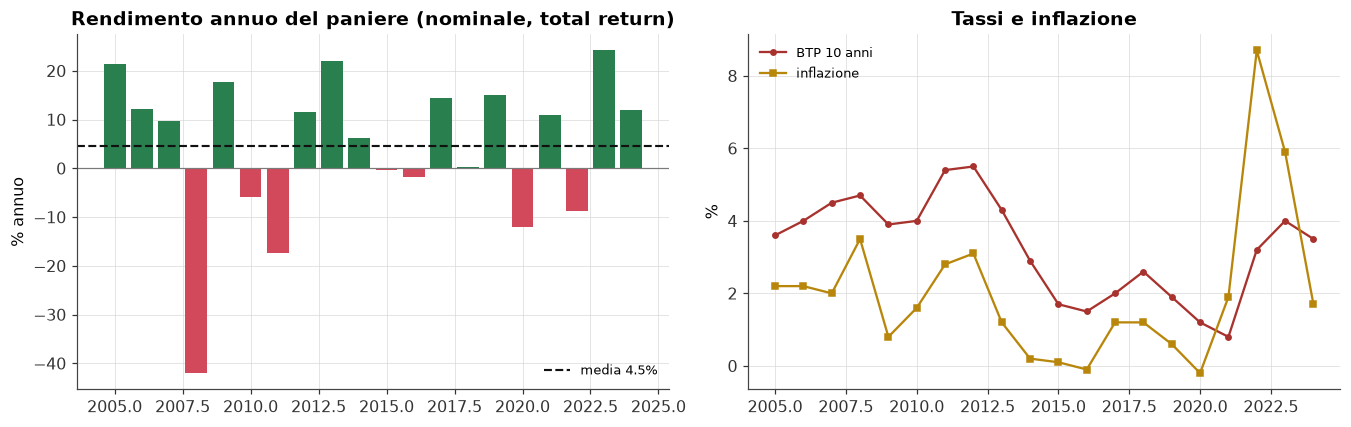

In [12]:
# ══════════════════════════════════════════════════════════════════════════════
# §9.1 — I dati (pochi, rozzi, ma dichiarati)
# ══════════════════════════════════════════════════════════════════════════════
#
#  Rendimenti annui TOTAL RETURN approssimati (dividendi reinvestiti, nominali).
#  ATTENZIONE: sono ricostruzioni a memoria e a ordine di grandezza, NON dati
#  ufficiali. Servono a dare una likelihood al MCMC, non a fare ricerca.
#  Sostituiscili con una serie vera (Bloomberg, Refinitiv, Borsa Italiana) e il
#  modello migliora gratis: la struttura non cambia.
#  NaN = titolo non quotato in quell'anno.
# ──────────────────────────────────────────────────────────────────────────────

RAW = {
    "anno":     list(range(2005, 2025)),
    "enel":     [0.25, 0.12, 0.14, -0.48, 0.12, -0.12, -0.21, 0.05, 0.25, 0.18,
                 -0.08, 0.05, 0.25, 0.09, 0.18, 0.01, -0.08, -0.34, 0.38, 0.14],
    "eni":      [0.32, 0.10, 0.12, -0.50, 0.19, -0.07, -0.11, 0.12, 0.19, -0.14,
                 -0.14, 0.12, 0.06, 0.06, 0.12, -0.40, 0.39, 0.15, 0.06, -0.14],
    "poste":    [None, None, None, None, None, None, None, None, None, None,
                 -0.02, -0.21, 0.18, -0.08, 0.31, -0.15, 0.12, -0.08, 0.12, 0.31],
    "terna":    [0.21, 0.13, 0.08, -0.42, 0.30, 0.04, -0.09, 0.17, 0.10, 0.24,
                 0.10, 0.17, 0.21, 0.10, 0.17, 0.10, 0.04, -0.16, 0.10, 0.17],
    "snam":     [0.24, 0.17, 0.11, -0.36, 0.24, 0.00, -0.16, 0.11, 0.13, 0.17,
                 0.08, 0.11, 0.13, 0.04, 0.13, 0.04, 0.11, -0.09, 0.17, 0.24],
    "leonardo": [0.38, 0.24, -0.09, -0.60, 0.11, -0.15, -0.42, 0.31, 0.51, -0.22,
                 0.11, -0.48, 0.18, -0.15, 0.11, -0.28, 0.11, 0.38, 0.85, 0.24],
    "fs":       [0.05, 0.07, 0.08, -0.08, 0.09, 0.05, -0.01, 0.05, 0.07, 0.05,
                 0.07, 0.05, 0.07, 0.05, 0.07, -0.08, 0.07, 0.01, 0.05, 0.05],
    "tim":      [-0.06, 0.07, 0.14, -0.48, 0.27, -0.13, -0.33, 0.14, 0.40, 0.14,
                 0.07, -0.26, 0.00, -0.33, 0.07, -0.19, 0.14, -0.46, 0.40, 0.14],
    "btp10y":   [0.036, 0.040, 0.045, 0.047, 0.039, 0.040, 0.054, 0.055, 0.043, 0.029,
                 0.017, 0.015, 0.020, 0.026, 0.019, 0.012, 0.008, 0.032, 0.040, 0.035],
    "inflazione": [0.022, 0.022, 0.020, 0.035, 0.008, 0.016, 0.028, 0.031, 0.012, 0.002,
                   0.001, -0.001, 0.012, 0.012, 0.006, -0.002, 0.019, 0.087, 0.059, 0.017],
}

CSV_PATH = DATA_DIR / "mkt_snapshot.csv"
if CSV_PATH.exists():
    MKT = pd.read_csv(CSV_PATH)
    fonte = f"letto da {CSV_PATH.name}"
else:
    MKT = pd.DataFrame(RAW)
    MKT.to_csv(CSV_PATH, index=False)
    fonte = f"scritto in {CSV_PATH.name} (modificalo e rilancia per usare i tuoi dati)"

COLMAP = {"ENEL": "enel", "ENI": "eni", "Poste Italiane": "poste", "Terna": "terna",
          "Snam": "snam", "Leonardo": "leonardo", "FS / Trenitalia": "fs",
          "TIM rete (NetCo)": "tim"}

_cols = [COLMAP[t] for t in BASKET.index]
_R = MKT[_cols].to_numpy(dtype=float)
_w = BASKET["peso"].to_numpy()
_mask = ~np.isnan(_R)
MKT["paniere"] = np.sum(np.where(_mask, _R * _w, 0.0), axis=1) / np.sum(_mask * _w, axis=1)

RET = MKT["paniere"].to_numpy(dtype=float)
BTP_OBS = MKT["btp10y"].to_numpy(dtype=float)
INF_OBS = MKT["inflazione"].to_numpy(dtype=float)

print(f"Dati: {len(MKT)} anni ({MKT['anno'].min()}-{MKT['anno'].max()}) · {fonte}")
print(f"Paniere: media {RET.mean():.2%}, σ {RET.std(ddof=1):.2%}, "
      f"min {RET.min():.1%}, max {RET.max():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.0))
axes[0].bar(MKT["anno"], RET * 100, color=[C["equity"] if x > 0 else C["accent"] for x in RET])
axes[0].axhline(RET.mean() * 100, color=C["tot"], ls="--", lw=1.4, label=f"media {RET.mean():.1%}")
axes[0].axhline(0, color=C["grey"], lw=0.8)
axes[0].set_title("Rendimento annuo del paniere (nominale, total return)")
axes[0].set_ylabel("% annuo")
axes[0].legend(fontsize=8.5)
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].plot(MKT["anno"], BTP_OBS * 100, marker="o", ms=3.5, color=C["btp"], label="BTP 10 anni")
axes[1].plot(MKT["anno"], INF_OBS * 100, marker="s", ms=3.5, color=C["ipp"], label="inflazione")
axes[1].set_title("Tassi e inflazione")
axes[1].set_ylabel("%")
axes[1].legend(fontsize=8.5)
axes[1].spines[["top", "right"]].set_visible(False)
plt.tight_layout()
savefig(fig, "06_dati")
plt.show()


In [13]:
# ══════════════════════════════════════════════════════════════════════════════
# §9.2 — MCMC sui parametri di mercato
# ══════════════════════════════════════════════════════════════════════════════

M = CFG.mcmc


def log_prior(th):
    mu, log_sig, y, infl = th
    sig = np.exp(log_sig)
    if not (M.y_prior_lo < y < M.y_prior_hi):
        return -np.inf
    if not (0.0 < infl < 0.08):
        return -np.inf
    lp = stats.norm.logpdf(mu, M.mu_prior_mu, M.mu_prior_sd)
    lp += stats.halfnorm.logpdf(sig, scale=M.sigma_prior_scale)
    lp += -np.log(sig)                                  # jacobiano del cambio di variabile
    lp += stats.norm.logpdf(infl, M.infl_prior_mu, M.infl_prior_sd)
    return float(lp)


def log_lik(th):
    mu, log_sig, y, infl = th
    sig = np.exp(log_sig)
    ll = stats.t.logpdf(RET, df=M.t_nu_lik, loc=mu, scale=sig).sum()
    ll += stats.norm.logpdf(BTP_OBS, loc=y, scale=0.013).sum()
    ll += stats.norm.logpdf(INF_OBS, loc=infl, scale=0.012).sum()
    return float(ll)


def log_post(th):
    lp = log_prior(th)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_lik(th)


# ── sampler di riserva (Metropolis-Hastings adattivo) ───────────────────────
def run_mh(logprob, theta0, n_steps, n_chains=4, burn=800, thin=4, seed=SEED):
    rng = np.random.default_rng(seed)
    ndim = len(theta0)
    scale = np.abs(theta0) * 0.02 + 1e-4
    chains = np.zeros((n_chains, (n_steps - burn) // thin, ndim))
    acc_rate = np.zeros((n_chains, ndim))
    for c in range(n_chains):
        th = np.array(theta0, dtype=float) * (1 + 0.01 * rng.standard_normal(ndim))
        lp = logprob(th)
        n_acc = 0
        k = 0
        local = scale.copy()
        for i in range(n_steps):
            prop = th + local * rng.standard_normal(ndim)
            lp_new = logprob(prop)
            if np.log(rng.random()) < lp_new - lp:
                th, lp = prop, lp_new
                n_acc += 1
                acc_rate[c] += 1
            # adattamento solo durante il burn-in
            if i < burn and (i + 1) % 100 == 0:
                rate = n_acc / (i + 1)
                local *= np.where(rate < 0.25, 0.85, np.where(rate > 0.45, 1.18, 1.0))
            if i >= burn and (i - burn) % thin == 0:
                chains[c, k] = th
                k += 1
            if i == n_steps - 1:
                acc_rate[c] = n_acc / n_steps
    return chains, acc_rate


def rhat(chains):
    """Gelman-Rubin con split delle catene. chains: (n_chains, n_steps, ndim)."""
    m, n, d = chains.shape
    half = n // 2
    split = np.concatenate([chains[:, :half, :], chains[:, half:2 * half, :]], axis=0)
    M_, N_ = split.shape[0], split.shape[1]
    means = split.mean(axis=1)
    W = split.var(axis=1, ddof=1).mean(axis=0)
    B = N_ * means.var(axis=0, ddof=1)
    var_hat = (N_ - 1) / N_ * W + B / N_
    return np.sqrt(np.maximum(var_hat / np.maximum(W, 1e-30), 0))


_t_start = time.time()
_base_th = np.array([M.mu_prior_mu, np.log(M.sigma_prior_scale), 0.035, M.infl_prior_mu])
_rng_mc = np.random.default_rng(SEED)
nwalk = M.n_walkers if HAS_EMCEE else 4
p0 = _base_th + 1e-3 * _rng_mc.standard_normal((nwalk, 4))
p0[:, 1] = np.log(M.sigma_prior_scale) + 0.05 * _rng_mc.standard_normal(nwalk)
p0[:, 2] = np.clip(p0[:, 2], M.y_prior_lo + 1e-3, M.y_prior_hi - 1e-3)
p0[:, 3] = np.clip(p0[:, 3], 0.001, 0.079)

if HAS_EMCEE:
    _sampler = emcee.EnsembleSampler(nwalk, 4, log_post)
    _sampler.run_mcmc(p0, M.n_steps, progress=False)
    CHAINS = _sampler.get_chain(discard=M.n_burn, thin=M.thin)        # (nwalk, nkept, 4)
    ACC = float(np.mean(_sampler.acceptance_fraction))
    try:
        TAU = emcee.autocorr.integrated_time(CHAINS, quiet=True)
    except Exception:
        TAU = np.full(4, np.nan)
    ENGINE = f"emcee {EMCEE_VERSION} · {nwalk} walker × {M.n_steps} passi"
else:
    CHAINS, _acc = run_mh(log_post, _base_th, n_steps=6000, n_chains=4,
                          burn=1500, thin=5, seed=SEED)
    ACC = float(np.mean(_acc))
    TAU = np.full(4, np.nan)
    ENGINE = "Metropolis-Hastings adattivo interno (emcee non disponibile)"

ELAPSED = time.time() - _t_start
FLAT = CHAINS.reshape(-1, 4)
RHAT = rhat(CHAINS)
ESS = (CHAINS.shape[0] * CHAINS.shape[1] / TAU) if np.all(np.isfinite(TAU)) else np.full(4, np.nan)

NOMI = ["μ rendimento", "σ rendimento", "ȳ BTP", "π inflazione"]
DIAG = pd.DataFrame({
    "parametro": NOMI,
    "mediana": [np.median(FLAT[:, 0]), np.median(np.exp(FLAT[:, 1])),
                np.median(FLAT[:, 2]), np.median(FLAT[:, 3])],
    "P5": [np.quantile(FLAT[:, 0], .05), np.quantile(np.exp(FLAT[:, 1]), .05),
           np.quantile(FLAT[:, 2], .05), np.quantile(FLAT[:, 3], .05)],
    "P95": [np.quantile(FLAT[:, 0], .95), np.quantile(np.exp(FLAT[:, 1]), .95),
            np.quantile(FLAT[:, 2], .95), np.quantile(FLAT[:, 3], .95)],
    "R̂": RHAT,
    "ESS": ESS,
})

print(f"Motore: {ENGINE}   ({ELAPSED:.1f} s)")
print(f"Tasso di accettazione medio: {ACC:.1%}")
print(f"R̂ massimo: {np.nanmax(RHAT):.4f}   {'✓ convergenza' if np.nanmax(RHAT) < 1.05 else '✗ allunga la catena'}")
display(DIAG.style.format({"mediana": "{:.2%}", "P5": "{:.2%}", "P95": "{:.2%}",
                            "R̂": "{:.4f}", "ESS": "{:,.0f}"}))


Motore: emcee 3.1.6 · 24 walker × 3600 passi   (15.1 s)
Tasso di accettazione medio: 59.7%
R̂ massimo: 1.0021   ✓ convergenza


,parametro,mediana,P5,P95,R̂,ESS
0,μ rendimento,5.90%,3.10%,8.70%,1.0009,"1,792"
1,σ rendimento,11.89%,8.74%,16.50%,1.0021,"1,677"
2,ȳ BTP,3.27%,2.79%,3.74%,0.9984,"1,791"
3,π inflazione,2.02%,1.60%,2.44%,0.9981,"1,829"


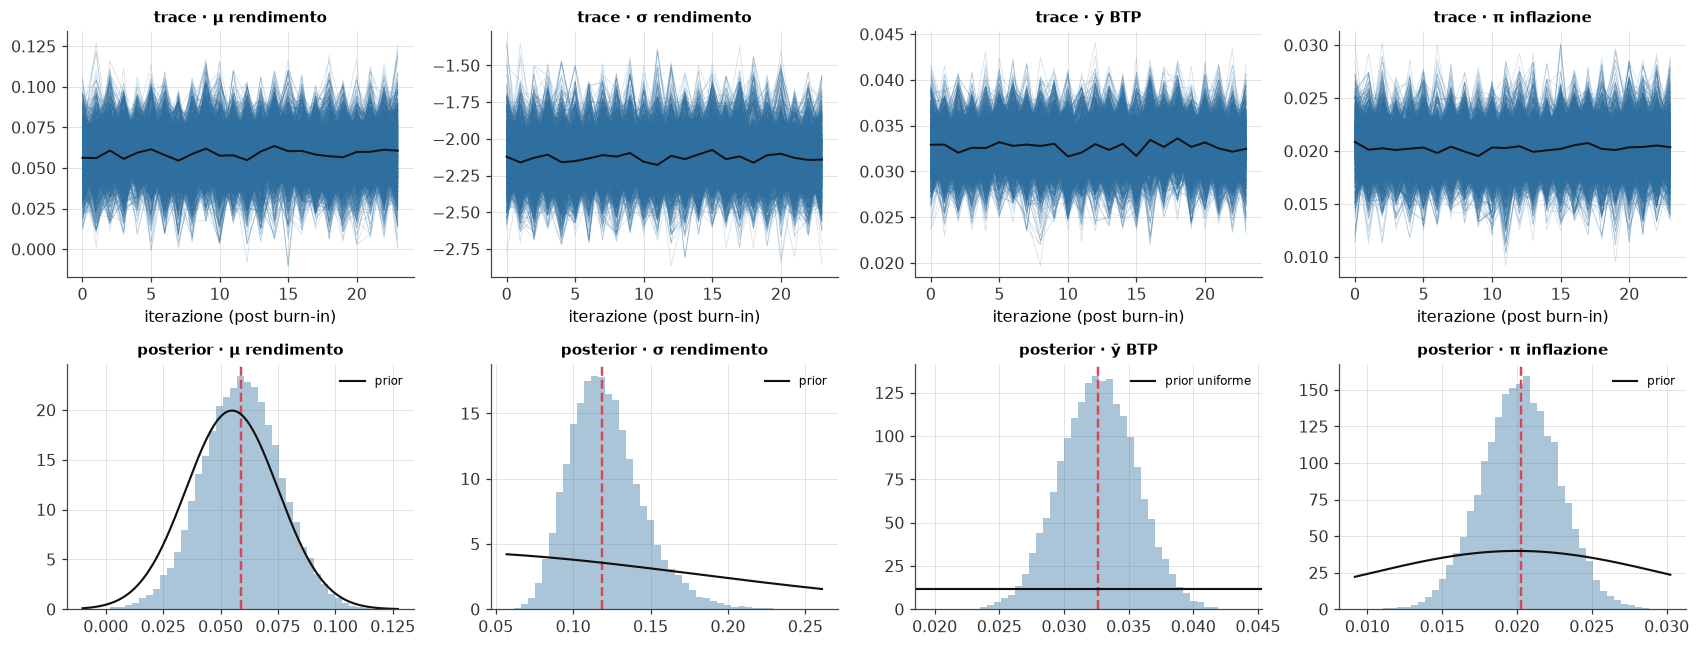

600 estrazioni dal posterior, pronte per la simulazione.
  μ   : 5.93%  (90 % CI 3.09% – 9.04%)
  σ   : 11.92%
  ȳ   : 3.26%  (90 % CI 2.81% – 3.70%)
  π   : 2.05%  (90 % CI 1.61% – 2.43%)

Nota: il prior su μ era centrato a 5,5 % con σ 2,0 %. Il posterior si sposta di poco — 20 anni di dati non spostano molto una convinzione, ed è giusto così: l'incertezza sul rendimento futuro di un paniere azionario non si risolve con 20 osservazioni annuali.


In [14]:
# ── Diagnostica: trace plot e posterior marginali ───────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(15.6, 6.0))

_faint = 0.22
for j in range(4):
    ax = axes[0, j]
    for k in range(CHAINS.shape[0]):
        ax.plot(CHAINS[k, :, j], lw=0.5, alpha=_faint, color=C["rcf"])
    ax.plot(np.median(CHAINS[:, :, j], axis=0), lw=1.3, color=C["tot"])
    ax.set_title(f"trace · {NOMI[j]}", fontsize=10)
    ax.set_xlabel("iterazione (post burn-in)")
    ax.spines[["top", "right"]].set_visible(False)

    ax = axes[1, j]
    vals = FLAT[:, j] if j != 1 else np.exp(FLAT[:, 1])
    ax.hist(vals, bins=45, density=True, color=C["rcf"], alpha=0.4)
    ax.axvline(np.median(vals), color=C["accent"], lw=1.6, ls="--")
    xs = np.linspace(vals.min(), vals.max(), 300)
    if j == 0:
        ax.plot(xs, stats.norm.pdf(xs, M.mu_prior_mu, M.mu_prior_sd), color=C["tot"], lw=1.4, label="prior")
    elif j == 1:
        ax.plot(xs, stats.halfnorm.pdf(xs, scale=M.sigma_prior_scale), color=C["tot"], lw=1.4, label="prior")
    elif j == 2:
        ax.axhline(1 / (M.y_prior_hi - M.y_prior_lo), color=C["tot"], lw=1.4, label="prior uniforme")
    else:
        ax.plot(xs, stats.norm.pdf(xs, M.infl_prior_mu, M.infl_prior_sd), color=C["tot"], lw=1.4, label="prior")
    ax.set_title(f"posterior · {NOMI[j]}", fontsize=10)
    ax.legend(fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
savefig(fig, "07_mcmc_diagnostica")
plt.show()

# ── dal posterior alle estrazioni che useremo nella simulazione ─────────────
S = CFG.sim.n_draws_posterior
_rng_post = np.random.default_rng(SEED + 1)
_sel = _rng_post.choice(len(FLAT), size=S, replace=False)

POST = {
    "mu_a": FLAT[_sel, 0],
    "sigma_a": np.exp(FLAT[_sel, 1]),
    "y_lt": FLAT[_sel, 2],
    "infl": FLAT[_sel, 3],
}

print(f"{S} estrazioni dal posterior, pronte per la simulazione.")
print(f"  μ   : {np.median(POST['mu_a']):.2%}  (90 % CI {np.quantile(POST['mu_a'], .05):.2%} – {np.quantile(POST['mu_a'], .95):.2%})")
print(f"  σ   : {np.median(POST['sigma_a']):.2%}")
print(f"  ȳ   : {np.median(POST['y_lt']):.2%}  (90 % CI {np.quantile(POST['y_lt'], .05):.2%} – {np.quantile(POST['y_lt'], .95):.2%})")
print(f"  π   : {np.median(POST['infl']):.2%}  (90 % CI {np.quantile(POST['infl'], .05):.2%} – {np.quantile(POST['infl'], .95):.2%})")

print("\nNota: il prior su μ era centrato a 5,5 % con σ 2,0 %. "
      "Il posterior si sposta di poco — 20 anni di dati non spostano molto "
      "una convinzione, ed è giusto così: l'incertezza sul rendimento futuro "
      "di un paniere azionario non si risolve con 20 osservazioni annuali.")


## §10 — I risultati: cosa succede a 10, 20 e 30 anni

Da qui in poi tutti i numeri vengono da **12.000 traiettorie**, ognuna con il proprio set di
parametri estratti dal posterior (mercati) e dal prior (fisco). Il risultato non è un numero:
è una **distribuzione**. Ne riportiamo mediana e intervalli 5-95 %.

**Tre letture che conviene fare insieme.**

1. **La mediana.** Il mondo «tipico»: nessuna catastrofe, nessun colpo di fortuna.
2. **La dispersione.** Se P5 e P95 stanno a un fattore 5 l'uno dall'altro, il modello ci sta
   dicendo che non sa — ed è la verità, non un difetto.
3. **La coda sinistra.** Il mondo in cui la patrimoniale viene abolita nel 2030 e il fondo si
   ferma. È lo scenario che un politico dovrebbe guardare prima di promettere qualcosa, perché
   è quello che può capitare davvero.

Nota sul nominale: a 30 anni con inflazione al 2 %, 1 € nominale vale 55 centesimi di oggi. Per
questo la tabella principale è in **euro reali 2026**.


In [15]:
# ══════════════════════════════════════════════════════════════════════════════
# §10 — Posterior predictive: 12.000 mondi possibili
# ══════════════════════════════════════════════════════════════════════════════

def estrazioni_prior(n, rng):
    """Parametri fiscali e strutturali senza dati: si campiona dal prior dichiarato.
    Vedi la tabella §9.4 per gli intervalli e la loro giustificazione."""
    return {
        "fonti.rcf_tasso_realizzo_annuo": rng.uniform(0.0075, 0.0115, n),
        "fonti.ipp_compliance": rng.uniform(0.75, 0.93, n),
        "fonti.ipp_quota_oltre_soglia": rng.uniform(0.62, 0.74, n),
        "fonti.isa_aliquota_media": rng.uniform(0.040, 0.080, n),
        "fonti.isa_valore_medio_partecipazione_mld": rng.uniform(0.15, 0.30, n),
        "macro.gdp_nominale_crescita": rng.normal(0.025, 0.004, n),
        "politica.p_fav_a_avv": rng.uniform(0.04, 0.14, n),
    }


def costruisci_parametri(n, rng, posterior=POST, base=P0, override=None):
    """Unisce: configurazione base + posterior (mercati) + prior (fisco) + override."""
    p = dict(base)
    idx = rng.integers(0, len(posterior["mu_a"]), n)
    p["mercati.drift_atteso"] = posterior["mu_a"][idx]
    p["mercati.sigma_alpha"] = posterior["sigma_a"][idx]
    p["mercati.btp_yield_lungo"] = posterior["y_lt"][idx]
    p["macro.inflazione_media"] = posterior["infl"][idx]
    p.update(estrazioni_prior(n, rng))
    if override:
        p.update(override)
    return p


# ── la simulazione principale ───────────────────────────────────────────────
T = CFG.sim.anni
NP = CFG.sim.n_paths
rng_main = np.random.default_rng(CFG.sim.seed)

PAR_MAIN = costruisci_parametri(NP, rng_main)
BASE_MAIN = fondo_baseline({**P0}, T)      # traiettoria di riferimento (deterministica)

t0 = time.time()
SIM = simula_fondo(PAR_MAIN, NP, T, rng_main, baseline=BASE_MAIN)
print(f"{NP:,} traiettorie × {T} anni simulate in {time.time() - t0:.1f} s".replace(",", "."))

F = SIM["F"]
FR = SIM["F_reale"]
D = SIM["D"]
DR = SIM["D_reale"]
anni = np.arange(T + 1)

# ── tabella dei quantili ───────────────────────────────────────────────────
def tabella_orizzonti(F, T_anni):
    out = {}
    for h in [10, 20, 30, 50]:
        if h <= T_anni:
            out[f"anno {h}"] = {
                "P5": np.quantile(F[:, h], 0.05),
                "P25": np.quantile(F[:, h], 0.25),
                "mediana": np.median(F[:, h]),
                "media": F[:, h].mean(),
                "P75": np.quantile(F[:, h], 0.75),
                "P95": np.quantile(F[:, h], 0.95),
            }
    return pd.DataFrame(out).T


TAB_REALE = tabella_orizzonti(FR, T)
TAB_NOM = tabella_orizzonti(F, T)
display(TAB_REALE.style.format("{:,.0f}").set_caption("Dotazione del fondo — mld € REALI 2026"))
display(TAB_NOM.style.format("{:,.0f}").set_caption("Dotazione del fondo — mld € NOMINALI"))

print(f"Dote iniziale F₀                : {float(np.median(SIM['F0'])):6.1f} mld €")
print(f"Mediana a 10 anni (reale)       : {np.median(FR[:, 10]):6.0f} mld €")
print(f"Mediana a 30 anni (reale)       : {np.median(FR[:, 30]):6.0f} mld €")
print(f"Mediana a 30 anni (nominale)    : {np.median(F[:, 30]):6.0f} mld €")
print(f"Moltiplicatore mediano a 30 anni: {np.median(FR[:, 30]) / float(np.median(SIM['F0'])):.1f}×")
print(f"P(il fondo supera i 100 mld reali entro 15 anni): "
      f"{np.mean(FR[:, 15] >= 100):.0%}")


12.000 traiettorie × 50 anni simulate in 0.1 s


,P5,P25,mediana,media,P75,P95
anno 10,123,170,205,206,237,298
anno 20,239,349,432,439,515,664
anno 30,353,556,712,734,869,"1,193"
anno 50,613,"1,076","1,453","1,539","1,854","2,778"


,P5,P25,mediana,media,P75,P95
anno 10,151,209,250,252,290,362
anno 20,361,524,649,655,764,975
anno 30,661,"1,030","1,307","1,335","1,571","2,121"
anno 50,"1,730","2,991","4,026","4,162","4,944","7,224"


Dote iniziale F₀                :   17.4 mld €
Mediana a 10 anni (reale)       :    205 mld €
Mediana a 30 anni (reale)       :    712 mld €
Mediana a 30 anni (nominale)    :   1307 mld €
Moltiplicatore mediano a 30 anni: 41.0×
P(il fondo supera i 100 mld reali entro 15 anni): 100%


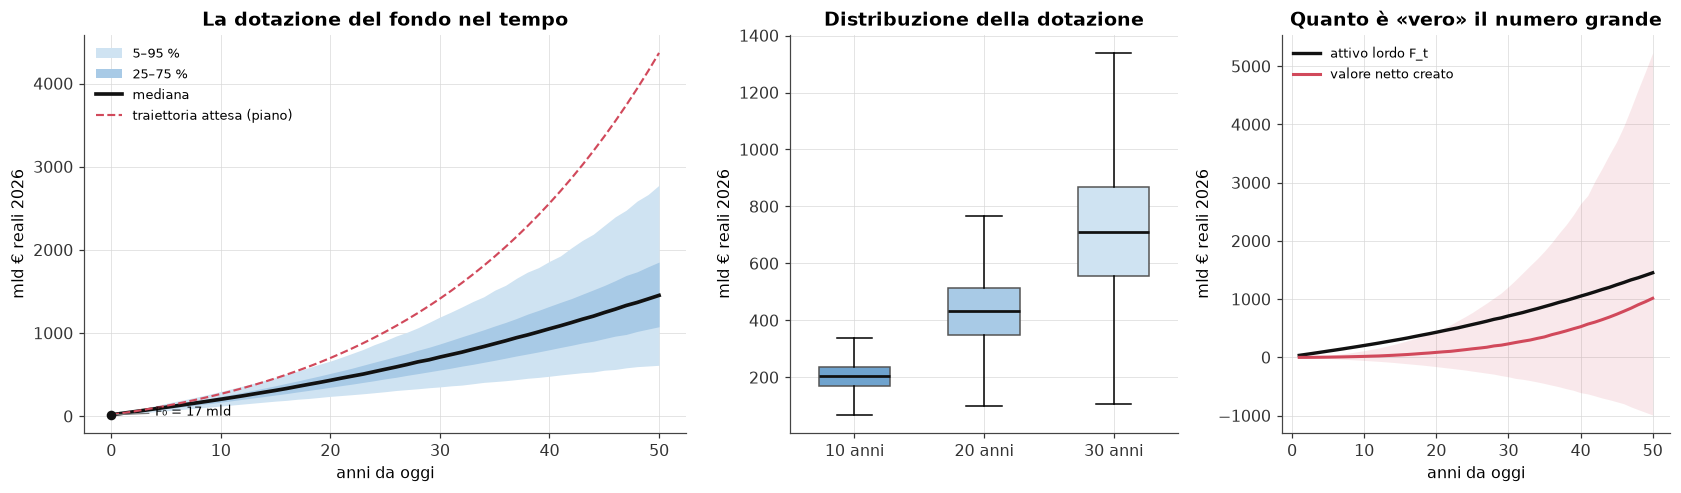

Attivo lordo mediano a 30 anni      :     712 mld € reali
Valore netto creato, mediana a 30 aa:     233 mld € reali  (33% dell'attivo)
Il resto non è ricchezza nuova: è ricchezza spostata (gettito dirottato, azioni comprate da privati, BTP ricomprati da altri creditori).


In [16]:
# ── Ventaglio della dotazione, distribuzioni, valore netto ──────────────────
fig = plt.figure(figsize=(15.4, 4.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1.55, 1.0, 1.0])

# (a) ventaglio
ax = fig.add_subplot(gs[0, 0])
ax.fill_between(anni, np.quantile(FR, 0.05, axis=0), np.quantile(FR, 0.95, axis=0),
                color=C["band1"], lw=0, label="5–95 %")
ax.fill_between(anni, np.quantile(FR, 0.25, axis=0), np.quantile(FR, 0.75, axis=0),
                color=C["band2"], lw=0, label="25–75 %")
ax.plot(anni, np.median(FR, axis=0), color=C["tot"], lw=2.4, label="mediana")
ax.plot(anni, BASE_MAIN, color=C["accent"], lw=1.4, ls="--", label="traiettoria attesa (piano)")
_F0m = float(np.median(SIM["F0"]))
ax.scatter([0], [_F0m], color=C["tot"], zorder=5, s=28)
ax.annotate(f"F₀ = {_F0m:.0f} mld", xy=(0, _F0m), xytext=(4, _F0m * 0.45),
            fontsize=8.5, arrowprops=dict(arrowstyle="-", color=C["grey"], lw=0.8))
ax.set_xlabel("anni da oggi")
ax.set_ylabel("mld € reali 2026")
ax.set_title("La dotazione del fondo nel tempo")
ax.legend(loc="upper left", fontsize=8.6)
ax.spines[["top", "right"]].set_visible(False)

# (b) distribuzione a 10/20/30 anni
ax = fig.add_subplot(gs[0, 1])
orizzonti = [10, 20, 30]
dati = [FR[:, h] for h in orizzonti]
bp = ax.boxplot(dati, tick_labels=[f"{h} anni" for h in orizzonti], patch_artist=True,
                widths=0.55, showfliers=False, medianprops=dict(color=C["tot"], lw=1.8))
for patch, col in zip(bp["boxes"], [C["band3"], C["band2"], C["band1"]]):
    patch.set_facecolor(col)
    patch.set_edgecolor("#555555")
ax.set_ylabel("mld € reali 2026")
ax.set_title("Distribuzione della dotazione")
ax.spines[["top", "right"]].set_visible(False)

# (c) valore netto creato vs attivo lordo
ax = fig.add_subplot(gs[0, 2])
phi = SIM["phi"]
qnr = float(P0["mercati.quota_non_residenti"])
y = SIM["y_btp"][:, :-1]
Fpre = SIM["F"][:, :-1]
valore = ((1 - phi[None, :]) * Fpre * (SIM["alpha"] - y)
          + qnr * phi[None, :] * Fpre * y)
cum_val = np.cumsum(valore, axis=1)
ax.plot(anni[1:], np.median(FR[:, 1:], axis=0), color=C["tot"], lw=2.2, label="attivo lordo F_t")
ax.plot(anni[1:], np.median(cum_val, axis=0), color=C["accent"], lw=2.0,
        label="valore netto creato")
ax.fill_between(anni[1:], np.quantile(cum_val, 0.05, axis=0), np.quantile(cum_val, 0.95, axis=0),
                color=C["accent"], alpha=0.12, lw=0)
ax.set_xlabel("anni da oggi")
ax.set_ylabel("mld € reali 2026")
ax.set_title("Quanto è «vero» il numero grande")
ax.legend(loc="upper left", fontsize=8.6)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
savefig(fig, "08_risultati")
plt.show()

_v30 = np.median(cum_val[:, 29])
print(f"Attivo lordo mediano a 30 anni      : {np.median(FR[:, 30]):7.0f} mld € reali")
print(f"Valore netto creato, mediana a 30 aa: {_v30:7.0f} mld € reali  "
      f"({_v30 / np.median(FR[:, 30]):.0%} dell'attivo)")
print("Il resto non è ricchezza nuova: è ricchezza spostata (gettito dirottato, "
      "azioni comprate da privati, BTP ricomprati da altri creditori).")


## §11 — Benchmark: quando il fondo può comprarsi l'Italia

Questa è la sezione che risponde alla domanda vera: **quando ci sono abbastanza soldi per
nazionalizzare ENI, ENEL, Poste, la rete TIM, Snam, Terna, Leonardo, Trenitalia?**

### 11.1 Come si calcola il costo

Per una **società quotata**, il costo di portarla sotto controllo non è «la capitalizzazione
moltiplicata per la quota mancante». Bisogna:

1. pagare un **premio di controllo** ai privati che vendono (media europea dei takeover: 30-40 %);
2. tenere conto dell'**impatto di mercato**: rastrellare il 20-30 % del capitale di una società
   del FTSE MIB fa salire il prezzo mentre lo compri (+2 % nel modello, probabilmente di più
   nella realtà);
3. sottrarre la **quota già pubblica**, che non va comprata.

$$\text{costo} = (q_{\text{target}} - q_{\text{pubblica}})\cdot \text{cap}\cdot(1+\text{premio})\cdot(1+\text{impatto})$$

Per le **società non quotate** il costo è una stima diretta: non c'è un prezzo di mercato, e
«nazionalizzare» significa semmai ricapitalizzare o comprare da un proprietario privato a
trattativa.

### 11.2 Le tre stranezze che rendono il dibattito confuso

**Poste Italiane.** Lo Stato detiene già ~64 % (MEF + CDP). Non c'è niente da nazionalizzare:
il benchmark sensato è il **delisting**, cioè comprare il 36 % rimasto per uscire dalla Borsa.
Costo: ~9 mld, premio incluso. Chi propone di «nazionalizzare Poste» non ha guardato chi è il
padrone.

**Trenitalia.** È al 100 % dentro Ferrovie dello Stato, che è al 100 % del MEF. È **già
nazionalizzata**. Il benchmark sensato non è l'acquisizione: è la **ricapitalizzazione**
(coprire il piano industriale, l'alta velocità, il rinnovo della flotta) o l'acquisizione di
operatori esteri. Chi promette di «riportare Trenitalia in mani pubbliche» promette una cosa
che è già così.

**Rete TIM.** La rete (NetCo) è stata venduta a KKR nel 2024. Qui «nazionalizzare» significa
**ricomprare**, e il prezzo è quello che KKR ha pagato più un premio: ~17 mld. È l'unico caso in
cui l'operazione ha un senso letterale e un costo definito — ed è anche quello che costa meno
di tutti.

### 11.3 Attenzione al vincolo che nessuno mette nel conto

Comprare queste società **significa pagarle**. Se il fondo spende 28 mld per ENEL, `F_t` scende
di 28 mld: non è che «possiede» ENEL *e* conserva la liquidità. Il benchmark qui sotto misura
**quando il fondo è abbastanza capiente da potersi permettere l'acquisto mantenendo una riserva**,
non un'operazione a costo zero. La riserva è fissata al **50 % del patrimonio**
(`benchmark.riserva_minima`): un acquisto è «permesso» solo se, dopo averlo pagato, resta metà del
fondo libero. È una regola prudenziale, non un tecnicismo — un fondo che spende il 30 % del NAV
per comprare Snam non è più un fondo sovrano, è una holding.

Con questa regola la soglia di accessibilità è il **doppio** del costo:
`soglia = costo / (1 − 0,50)`. La differenza tra un fondo da 1.000 mld che compra ENEL e un
fondo da 1.000 mld che ha comprato ENEL è di 28 mld, cioè circa un anno e mezzo di gettito.


In [17]:
# ══════════════════════════════════════════════════════════════════════════════
# §11 — Benchmark di nazionalizzazione
# ══════════════════════════════════════════════════════════════════════════════

# Capitalizzazioni e quote pubbliche: stime di ordine di grandezza (2025-2026).
# FONTE: capitalizzazioni approssimate da memoria; quote pubbliche da partecipazioni
# MEF/CDP dichiarate. # TODO: aggiornare con dati di Borsa Italiana.
BENCH = pd.DataFrame([
    dict(chiave="ENI",          nome="Controllo ENI (51 %)",              tipo="quotata",
         cap_mld=48.0,  quota_pub=0.092, target=0.51, costo_diretto=np.nan,
         nota="MEF 4,4 % + CDP 4,8 %"),
    dict(chiave="ENEL",         nome="Controllo ENEL (51 %)",             tipo="quotata",
         cap_mld=75.0,  quota_pub=0.236, target=0.51, costo_diretto=np.nan,
         nota="MEF ~24 %"),
    dict(chiave="Snam",         nome="Controllo Snam (51 %)",             tipo="quotata",
         cap_mld=17.0,  quota_pub=0.309, target=0.51, costo_diretto=np.nan,
         nota="CDP ~31 %"),
    dict(chiave="Terna",        nome="Controllo Terna (51 %)",            tipo="quotata",
         cap_mld=14.0,  quota_pub=0.299, target=0.51, costo_diretto=np.nan,
         nota="CDP ~30 %"),
    dict(chiave="Leonardo",     nome="Controllo Leonardo (51 %)",         tipo="quotata",
         cap_mld=30.0,  quota_pub=0.302, target=0.51, costo_diretto=np.nan,
         nota="MEF ~30 %"),
    dict(chiave="Poste",        nome="Delisting Poste Italiane (100 %)",   tipo="quotata",
         cap_mld=18.3,  quota_pub=0.643, target=1.00, costo_diretto=np.nan,
         nota="già a controllo pubblico: serve solo il 36 %"),
    dict(chiave="TIMrete",      nome="Riacquisto rete TIM (100 %)",        tipo="non_quotata",
         cap_mld=np.nan, quota_pub=0.10, target=1.00, costo_diretto=17.0,
         nota="venduta a KKR nel 2024; CDP ~10 %"),
    dict(chiave="FS",           nome="Ricapitalizzazione FS/Trenitalia",   tipo="non_quotata",
         cap_mld=np.nan, quota_pub=1.00, target=1.00, costo_diretto=12.0,
         nota="già 100 % MEF: il costo è il piano industriale, non l'acquisto"),
]).set_index("chiave")

_pc = float(P0["benchmark.premio_controllo"])
_im = float(P0["benchmark.impatto_mercato"])


def costo_benchmark(row):
    if row["tipo"] == "quotata":
        mancante = max(row["target"] - row["quota_pub"], 0.0)
        return mancante * row["cap_mld"] * (1 + _pc) * (1 + _im)
    return row["costo_diretto"] * (1 + _im)


BENCH["costo_mld"] = BENCH.apply(costo_benchmark, axis=1)

# pacchetti
PACCHETTI = {
    "Pacchetto energia (ENI+ENEL+Snam+Terna)": ["ENI", "ENEL", "Snam", "Terna"],
    "Tutti e otto gli obiettivi": list(BENCH.index),
}
for nome, chiavi in PACCHETTI.items():
    BENCH.loc[nome] = {"nome": nome, "tipo": "pacchetto", "cap_mld": np.nan,
                       "quota_pub": np.nan, "target": np.nan, "costo_diretto": np.nan,
                       "nota": "somma dei costi", "costo_mld": BENCH.loc[chiavi, "costo_mld"].sum()}

# benchmark sul debito pubblico
DEBITO = 3000.0
BENCH.loc["Debito 5 %"] = {"nome": "Copertura del 5 % del debito pubblico", "tipo": "debito",
                           "cap_mld": np.nan, "quota_pub": np.nan, "target": np.nan,
                           "costo_diretto": np.nan, "nota": "3.000 mld di stock",
                           "costo_mld": 0.05 * DEBITO}
BENCH.loc["Debito estero"] = {"nome": "Sostituire la quota non residente del debito", "tipo": "debito",
                              "cap_mld": np.nan, "quota_pub": np.nan, "target": np.nan,
                              "costo_diretto": np.nan, "nota": "~27 % dello stock",
                              "costo_mld": float(P0["mercati.quota_non_residenti"]) * DEBITO}

display(BENCH[["nome", "nota", "costo_mld"]]
        .rename(columns={"nome": "obiettivo", "nota": "note", "costo_mld": "costo (mld € 2026)"})
        .style.format({"costo (mld € 2026)": "{:,.1f}"}))

# Regola prudenziale: si considera "permesso" un acquisto solo se, dopo averlo
# pagato, resta almeno il 50 % del patrimonio libero.
RIS = float(P0["benchmark.riserva_minima"])
BENCH["soglia_mld"] = BENCH["costo_mld"] / (1 - RIS)

print(f"Premio di controllo: {_pc:.0%} · impatto di mercato: {_im:.0%} · "
      f"riserva minima: {RIS:.0%} del NAV")
print(f"Costo totale per comprare tutto il comprabile: {BENCH.loc['Tutti e otto gli obiettivi', 'costo_mld']:.0f} mld €")
print(f"→ per permetterselo serve una dotazione di almeno "
      f"{BENCH.loc['Tutti e otto gli obiettivi', 'soglia_mld']:.0f} mld (riserva inclusa)")


,obiettivo,note,costo (mld € 2026)
chiave,,,
ENI,Controllo ENI (51 %),"MEF 4,4 % + CDP 4,8 %",27.6
ENEL,Controllo ENEL (51 %),MEF ~24 %,28.3
Snam,Controllo Snam (51 %),CDP ~31 %,4.7
Terna,Controllo Terna (51 %),CDP ~30 %,4.1
Leonardo,Controllo Leonardo (51 %),MEF ~30 %,8.6
Poste,Delisting Poste Italiane (100 %),già a controllo pubblico: serve solo il 36 %,9.0
TIMrete,Riacquisto rete TIM (100 %),venduta a KKR nel 2024; CDP ~10 %,17.3
FS,Ricapitalizzazione FS/Trenitalia,"già 100 % MEF: il costo è il piano industriale, non l'acquisto",12.2
Pacchetto energia (ENI+ENEL+Snam+Terna),Pacchetto energia (ENI+ENEL+Snam+Terna),somma dei costi,64.7


Premio di controllo: 35% · impatto di mercato: 2% · riserva minima: 50% del NAV
Costo totale per comprare tutto il comprabile: 112 mld €
→ per permetterselo serve una dotazione di almeno 224 mld (riserva inclusa)


,costo,soglia,P(≤10 anni),P(≤20 anni),quando (mediana),volte coperte a 10 anni
obiettivo,,,,,,
Controllo Terna (51 %),4,8,100%,100%,subito,25.2×
Controllo Snam (51 %),5,9,100%,100%,subito,21.8×
Controllo Leonardo (51 %),9,17,100%,100%,subito,11.9×
Delisting Poste Italiane (100 %),9,18,100%,100%,anno 1,11.4×
Ricapitalizzazione FS/Trenitalia,12,24,100%,100%,anno 1,8.4×
Riacquisto rete TIM (100 %),17,35,100%,100%,anno 1,5.9×
Controllo ENI (51 %),28,55,100%,100%,anno 3,3.7×
Controllo ENEL (51 %),28,57,100%,100%,anno 3,3.6×
Pacchetto energia (ENI+ENEL+Snam+Terna),65,129,93%,100%,anno 7,1.6×


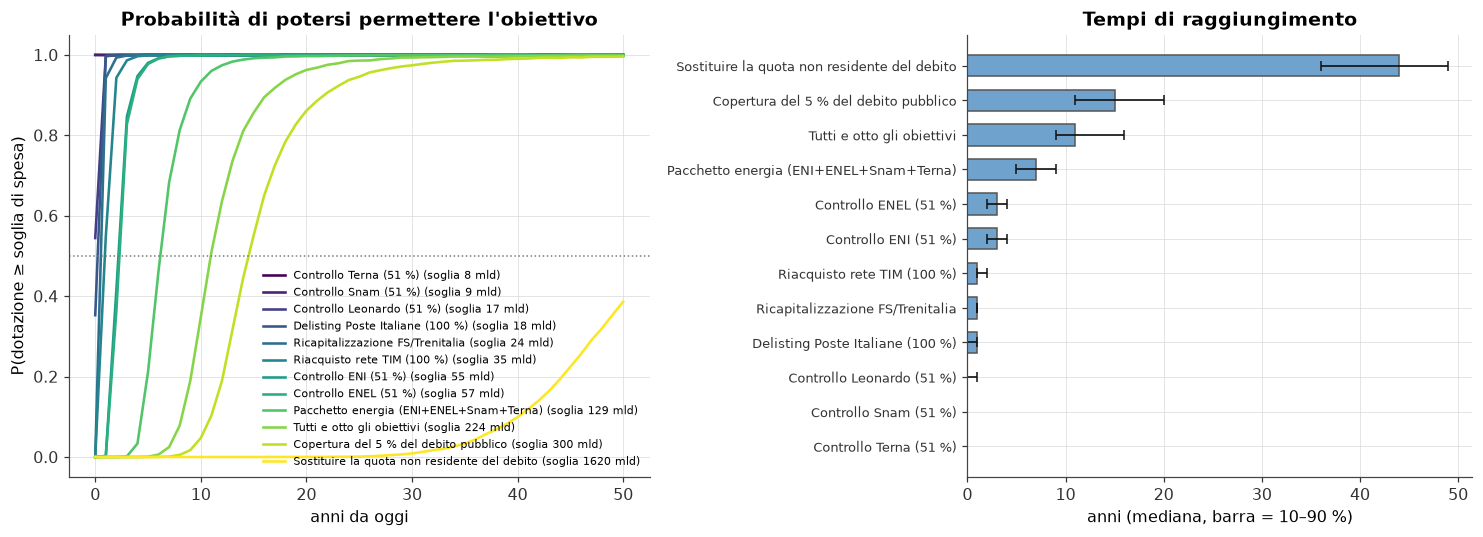

Pacchetto energia: servono 129 mld (riserva inclusa) → anno 7
Tutti e otto gli obiettivi: 224 mld → anno 11

La liquidità non è il vincolo. Il vincolo è politico, regolatorio e di prezzo.


In [18]:
# ── Quando il fondo può permetterselo ───────────────────────────────────────

def primo_raggiungimento(FR, soglia):
    """Anno in cui F_t supera per la prima volta la soglia. NaN se non accade mai."""
    hit = FR >= soglia
    return np.where(hit.any(axis=1), hit.argmax(axis=1), np.nan)


anni_hit = {k: primo_raggiungimento(FR, row["soglia_mld"]) for k, row in BENCH.iterrows()}


def _quando(v):
    """Formatta un anno: 0 significa 'subito, già con la dote iniziale'."""
    if np.isnan(v):
        return "mai"
    return "subito" if v < 1 else f"anno {v:.0f}"


righe = []
for k, row in BENCH.iterrows():
    a = anni_hit[k]
    righe.append({
        "obiettivo": row["nome"],
        "costo": row["costo_mld"],
        "soglia": row["soglia_mld"],
        "P(≤10 anni)": np.mean(FR[:, 10] >= row["soglia_mld"]),
        "P(≤20 anni)": np.mean(FR[:, 20] >= row["soglia_mld"]),
        "quando (mediana)": float(np.nanmedian(a)) if np.any(~np.isnan(a)) else np.nan,
        "volte coperte a 10 anni": np.median(FR[:, 10]) / row["soglia_mld"],
    })
TEMPI = pd.DataFrame(righe).set_index("obiettivo").sort_values("costo")

_disp = TEMPI.copy()
_disp["quando (mediana)"] = TEMPI["quando (mediana)"].map(_quando)

display(_disp.style.format({
    "costo": "{:,.0f}", "soglia": "{:,.0f}",
    "P(≤10 anni)": "{:.0%}", "P(≤20 anni)": "{:.0%}",
    "volte coperte a 10 anni": "{:.1f}×",
}).background_gradient(subset=["P(≤20 anni)"], cmap="Greens"))

fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.0), gridspec_kw={"width_ratios": [1.15, 1]})

ax = axes[0]
ordine = BENCH.sort_values("costo_mld").index
for i, k in enumerate(ordine):
    y = [np.mean(FR[:, t] >= BENCH.loc[k, "soglia_mld"]) for t in range(T + 1)]
    ax.plot(range(T + 1), y, lw=1.7,
            color=plt.cm.viridis(i / max(len(ordine) - 1, 1)),
            label=f"{BENCH.loc[k, 'nome']} (soglia {BENCH.loc[k, 'soglia_mld']:.0f} mld)")
ax.axhline(0.5, color=C["grey"], ls=":", lw=1)
ax.set_xlabel("anni da oggi")
ax.set_ylabel("P(dotazione ≥ soglia di spesa)")
ax.set_title("Probabilità di potersi permettere l'obiettivo")
ax.legend(fontsize=7.0, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
sel = [k for k in ordine if not np.all(np.isnan(anni_hit[k]))]
med = [np.nanmedian(anni_hit[k]) for k in sel]
lo = [np.nanquantile(anni_hit[k], 0.10) for k in sel]
hi = [np.nanquantile(anni_hit[k], 0.90) for k in sel]
yy = np.arange(len(sel))
ax.barh(yy, med, color=C["band3"], edgecolor="#555555", height=0.62)
ax.errorbar(med, yy, xerr=[np.array(med) - np.array(lo), np.array(hi) - np.array(med)],
            fmt="none", ecolor=C["tot"], capsize=3, lw=1.1)
ax.set_yticks(yy)
ax.set_yticklabels([BENCH.loc[k, "nome"] for k in sel], fontsize=8.4)
ax.set_xlabel("anni (mediana, barra = 10–90 %)")
ax.set_title("Tempi di raggiungimento")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
savefig(fig, "09_benchmark")
plt.show()

_energia = BENCH.loc["Pacchetto energia (ENI+ENEL+Snam+Terna)", "soglia_mld"]
print(f"Pacchetto energia: servono {_energia:.0f} mld (riserva inclusa) → "
      f"{_quando(np.nanmedian(anni_hit['Pacchetto energia (ENI+ENEL+Snam+Terna)']))}")
print(f"Tutti e otto gli obiettivi: {BENCH.loc['Tutti e otto gli obiettivi','soglia_mld']:.0f} mld → "
      f"{_quando(np.nanmedian(anni_hit['Tutti e otto gli obiettivi']))}")
print(f"\nLa liquidità non è il vincolo. Il vincolo è politico, regolatorio e di prezzo.")


## §12 — Il dividendo sociale: quanto, a chi, e cosa costa

### 12.1 La regola

La specifica dice: *«se ci sono residui perché le cose vanno meglio del previsto, stacca un
dividendo sociale»*. Tradotto in formula, con una regola prudente:

$$D_t = \min\Big(\underbrace{0{,}30}_{\text{quota del surplus}}\cdot\max\big(0,\ F_t - F_t^{\text{base}}\big),\ \underbrace{0{,}03 \cdot F_t}_{\text{tetto}}\Big),\quad t \ge 5$$

Tre scelte dentro questa formula, tutte discutibili:

- **Surplus rispetto al piano, non rispetto a zero.** Se il fondo rende il 4 % e il piano prevedeva
  il 4 %, non c'è nessun residuo: non si distribuisce nulla, perché non è successo niente di
  straordinario. Distribuire l'intero rendimento (come fanno i fondi sovrani veri, tipo il fondo
  norvegese con la sua *spending rule* al 3 %) è un'altra scelta possibile e la trovi come
  `regola = "quota_nav"`.
- **Solo il 30 % del surplus.** Il resto resta a capitale: un fondo che distribuisce tutto ciò che
  guadagna non cresce mai, e il punto dell'operazione era crescere.
- **Tetto al 3 % del patrimonio e niente dividendi prima dell'anno 5.** Il 3 % è lo standard dei
  fondi sovrani veri: sopra quella soglia il patrimonio reale inizia a erodersi. Il tetto protegge
  dal caso in cui un anno eccezionale produca un surplus enorme che, se distribuito, svuoterebbe
  la cassa.

### 12.2 Il piano deve essere prudente (e qui c'è un pezzo di matematica che conta)

C'è un trabocchetto. Se costruissimo il «previsto» con i valori **medi** dei parametri, il fondo
supererebbe il piano solo in metà dei mondi — perché la **mediana** di un processo composto cresce
meno della **media**. È la disuguaglianza di Jensen applicata all'interesse composto: con una
volatilità del 16 %, il divario è di circa `σ²/2 ≈ 1,3 %` all'anno. Su 30 anni, un punto e tre
decimi all'anno è un fattore 1,5 sulla dotazione.

Quindi il «piano» sottrae **1,5 punti percentuali** al rendimento atteso (`sconto_baseline_rendimento`):
1,3 servono a compensare la disuguaglianza, il resto è margine di sicurezza. Solo così «meglio del
previsto» significa qualcosa di raggiungibile, invece di una soglia che metà dei mondi non tocca mai.
Se ti sembra un imbroglio, hai ragione a pensarci: è una scelta, è dichiarata, ed è modificabile.

### 12.3 Quanto vale, e perché la mediana è zero

Qui arriva il risultato più scomodo del notebook, e va detto senza girarci intorno:

> **Il dividendo sociale mediano, in un anno qualsiasi, è zero euro.**

Non è un bug. È la conseguenza logica di una regola che distribuisce *solo i residui favorevoli*:
in metà dei mondi simulati il fondo sta sotto il piano, quindi non c'è niente da distribuire. Il
«reddito per tutti» che si legge nei volantini è, nell'anno tipico, **nulla**. La *media* è positiva
ma è trascinata dai mondi in cui le cose vanno bene — esattamente il tipo di asimmetria che una
misura strutturale non dovrebbe avere.

Le tabelle sotto riportano perciò **media e mediana**, e la probabilità che in un dato anno non si
distribuisca nulla. Se una forza politica vuole promettere un dividendo sociale, deve dire quale
delle due cifre sta usando: sono diverse di un fattore enorme. E deve soprattutto dire che cosa
succede nell'altra metà dei mondi.

C'è un secondo risultato controintuitivo. Poiché distribuisce solo il 30 % del surplus e c'è un
tetto al 3 % del NAV, **il tetto morde prima della quota**: alzare il payout dal 30 % al 70 % riduce
la dotazione a 30 anni di appena il 3 %, perché nella gran parte degli anni è il tetto a
determinare l'importo (mentre il dividendo cumulato quasi raddoppia). Chi volesse davvero un «reddito per tutti» dovrebbe alzare il **tetto**, non
la percentuale — e a quel punto il fondo smetterebbe di crescere. Il grafico in fondo alla sezione
lo mostra: la linea della dotazione è quasi piatta, le barre dei dividendi salgono.



DIVIDENDO SOCIALE — regola: eccesso_su_baseline · payout 30% del surplus · tetto 3% del NAV · dal 5° anno



,mld € distribuiti (media),€/abitante medio,€/abitante mediano,€/abitante P95,P(nessun dividendo)
orizzonte,,,,,
anno 10,2.1,35,0,133,62%
anno 20,4.9,84,0,313,62%
anno 30,9.0,153,0,564,61%


Dividendi cumulati su 30 anni: media 114 mld € reali, mediana 74 mld
  → per abitante, cumulato: mediana 1.261 € (P5 0 · P95 6.025)
Percentuale di mondi in cui il fondo paga almeno un euro: 85%

Il tetto del 3% del NAV morde nel 24% degli anni-percorso.
Dividendo medio al 30° anno: 153 €/abitante — mediano 0 €.
Il divario mediana/media non è un errore: distribuendo solo i residui favorevoli,
in metà dei mondi non si distribuisce nulla. Il 'reddito per tutti' è zero
nell'anno tipico, e la media è trascinata dai mondi in cui le cose vanno bene.


,F30,anni_energia,div_cum
payout,,,
0.000000,801,7,0
0.100000,737,7,740
0.200000,716,7,"1,075"
0.300000,708,7,"1,208"
0.500000,703,7,"1,313"
0.700000,700,7,"1,367"


Con payout 0 %: F30 = 801 mld; con payout 70 %: 700 mld (−13%).
Da 30 % a 70 % la dotazione cambia di poco (≈3 %): nella maggior parte degli anni
è il tetto del 3 % del NAV a determinare l'importo, non la quota del surplus.
La leva vera è il tetto, non la percentuale.


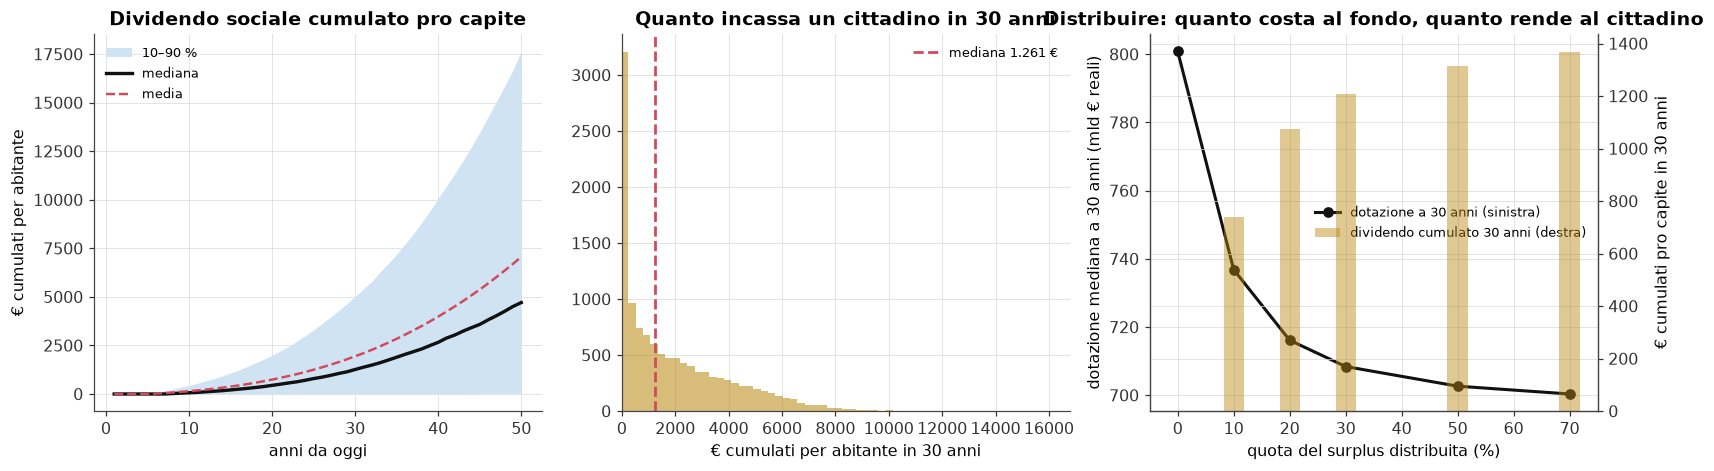

In [19]:
# ══════════════════════════════════════════════════════════════════════════════
# §12 — Dividendo sociale: quantificazione
# ══════════════════════════════════════════════════════════════════════════════

POP = float(P0["spesa.popolazione"])
DIV_ANNO = DR[:, :T]                       # dividendo reale, anni 1..T
pro_capite = DIV_ANNO * 1e9 / POP          # € per abitante per anno, reali

cum30 = np.sum(DIV_ANNO[:, :30], axis=1)              # mld reali cumulati su 30 anni
pro_capite_cum30 = cum30 * 1e9 / POP
cum_pro_capite = np.cumsum(pro_capite, axis=1)        # cumulato anno per anno
paga_almeno_una_volta = np.mean(cum30 > 0.01)

print(f"DIVIDENDO SOCIALE — regola: {P0['spesa.regola']} · payout "
      f"{P0['spesa.payout_quota']:.0%} del surplus · tetto {P0['spesa.payout_max_nav']:.0%} "
      f"del NAV · dal {int(P0['spesa.anno_inizio'])}° anno\n")

righe = []
for h in [10, 20, 30]:
    d = DIV_ANNO[:, h - 1]
    righe.append({
        "orizzonte": f"anno {h}",
        "mld € distribuiti (media)": d.mean(),
        "€/abitante medio": d.mean() * 1e9 / POP,
        "€/abitante mediano": np.median(d) * 1e9 / POP,
        "€/abitante P95": np.quantile(d, 0.95) * 1e9 / POP,
        "P(nessun dividendo)": np.mean(d < 0.01),
    })
DIV_TAB = pd.DataFrame(righe).set_index("orizzonte")
display(DIV_TAB.style.format({
    "mld € distribuiti (media)": "{:,.1f}", "€/abitante medio": "{:,.0f}",
    "€/abitante mediano": "{:,.0f}", "€/abitante P95": "{:,.0f}",
    "P(nessun dividendo)": "{:.0%}",
}))

print(f"Dividendi cumulati su 30 anni: media {cum30.mean():.0f} mld € reali, "
      f"mediana {np.median(cum30):.0f} mld")
_it = lambda x: f"{x:,.0f}".replace(",", ".")
print("  → per abitante, cumulato: mediana "
      f"{_it(np.median(pro_capite_cum30))} € (P5 {_it(np.quantile(pro_capite_cum30, .05))} · "
      f"P95 {_it(np.quantile(pro_capite_cum30, .95))})")
print(f"Percentuale di mondi in cui il fondo paga almeno un euro: {paga_almeno_una_volta:.0%}")

# Quanto spesso è il TETTO a mordere, invece del 30 % del surplus?
_cap = float(P0["spesa.payout_max_nav"])
_payout = float(P0["spesa.payout_quota"])
_surplus = np.maximum(SIM["F"][:, :-1] - BASE_MAIN[None, :-1], 0.0)
_share_cap = float(np.mean(_payout * _surplus >= _cap * SIM["F"][:, :-1]))
print(f"\nIl tetto del {_cap:.0%} del NAV morde nel {_share_cap:.0%} degli anni-percorso.")
print(f"Dividendo medio al 30° anno: {_it(np.mean(pro_capite[:, 29]))} €/abitante "
      f"— mediano {_it(np.median(pro_capite[:, 29]))} €.")
print("Il divario mediana/media non è un errore: distribuendo solo i residui favorevoli,\n"
      "in metà dei mondi non si distribuisce nulla. Il 'reddito per tutti' è zero\n"
      "nell'anno tipico, e la media è trascinata dai mondi in cui le cose vanno bene.")

fig, axes = plt.subplots(1, 3, figsize=(15.4, 4.4))

ax = axes[0]
med = np.median(cum_pro_capite, axis=0)
lo = np.quantile(cum_pro_capite, 0.10, axis=0)
hi = np.quantile(cum_pro_capite, 0.90, axis=0)
ax.fill_between(np.arange(1, T + 1), lo, hi, color=C["band1"], lw=0, label="10–90 %")
ax.plot(np.arange(1, T + 1), med, color=C["tot"], lw=2.2, label="mediana")
ax.plot(np.arange(1, T + 1), cum_pro_capite.mean(axis=0), color=C["accent"], lw=1.6,
        ls="--", label="media")
ax.set_xlabel("anni da oggi")
ax.set_ylabel("€ cumulati per abitante")
ax.set_title("Dividendo sociale cumulato pro capite")
ax.legend(fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
ax.hist(pro_capite_cum30, bins=60, color=C["ipp"], alpha=0.55)
ax.axvline(np.median(pro_capite_cum30), color=C["accent"], lw=1.8, ls="--",
           label=f"mediana {np.median(pro_capite_cum30):,.0f} €".replace(",", "."))
ax.axvline(0, color=C["tot"], lw=1)
ax.set_xlabel("€ cumulati per abitante in 30 anni")
ax.set_title("Quanto incassa un cittadino in 30 anni")
ax.set_xlim(left=0)
ax.legend(fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

# (c) trade-off: quanto costa distribuire, e chi decide davvero il payout
ax = axes[2]
payouts = [0.0, 0.10, 0.20, 0.30, 0.50, 0.70]
_soglia_energia = BENCH.loc["Pacchetto energia (ENI+ENEL+Snam+Terna)", "soglia_mld"]
res = []
for q in payouts:
    _p = {**P0, "spesa.payout_quota": q}
    _r = np.random.default_rng(77)
    _pp = costruisci_parametri(2000, _r, base=_p)
    _s = simula_fondo(_pp, 2000, T, _r, baseline=BASE_MAIN)
    _prob = np.array([np.mean(_s["F_reale"][:, t] >= _soglia_energia) for t in range(T + 1)])
    _hit = np.where(_prob >= 0.5)[0]
    res.append(dict(
        payout=q,
        F30=np.median(_s["F_reale"][:, 30]),
        anni_energia=int(_hit[0]) if len(_hit) else np.nan,
        div_cum=np.median(np.sum(_s["D_reale"][:, :30], axis=1) * 1e9 / POP),
    ))
TRADEOFF = pd.DataFrame(res).set_index("payout")
display(TRADEOFF.style.format({"F30": "{:,.0f}", "anni_energia": "{:.0f}", "div_cum": "{:,.0f}"})
        .set_caption("Compromesso: quanto distribuisci, quanto resta al fondo"))

_ax2 = ax.twinx()
ax.plot(TRADEOFF.index * 100, TRADEOFF["F30"], marker="o", color=C["tot"], lw=2,
        label="dotazione a 30 anni (sinistra)")
_ax2.bar(TRADEOFF.index * 100, TRADEOFF["div_cum"], width=3.6,
         color=C["ipp"], alpha=0.45, label="dividendo cumulato 30 anni (destra)")
ax.set_xlabel("quota del surplus distribuita (%)")
ax.set_ylabel("dotazione mediana a 30 anni (mld € reali)")
_ax2.set_ylabel("€ cumulati pro capite in 30 anni")
ax.set_title("Distribuire: quanto costa al fondo, quanto rende al cittadino")
ax.set_xlim(-5, 75)
ax.spines[["top"]].set_visible(False)
_ax2.spines[["top"]].set_visible(False)
_h1, _l1 = ax.get_legend_handles_labels()
_h2, _l2 = _ax2.get_legend_handles_labels()
ax.legend(_h1 + _h2, _l1 + _l2, fontsize=8.2, loc="center right")

print(f"Con payout 0 %: F30 = {TRADEOFF.loc[0.0, 'F30']:.0f} mld; con payout 70 %: "
      f"{TRADEOFF.loc[0.70, 'F30']:.0f} mld (−{1 - TRADEOFF.loc[0.70, 'F30'] / TRADEOFF.loc[0.0, 'F30']:.0%}).")
print("Da 30 % a 70 % la dotazione cambia di poco (≈3 %): nella maggior parte degli anni\n"
      "è il tetto del 3 % del NAV a determinare l'importo, non la quota del surplus.\n"
      "La leva vera è il tetto, non la percentuale.")

plt.tight_layout()
savefig(fig, "10_dividendo")
plt.show()


## §13 — Quale manopola sposta davvero l'ago

Un modello con 80 parametri è inutile se non si sa **quali contano**. Qui facciamo un'analisi
*one-at-a-time*: si cambia un parametro, si tengono fissi tutti gli altri, si guarda di quanto si
muove la dotazione mediana a 30 anni. Non è un'analisi di sensibilità globale (per quella servirebbero
gli indici di Sobol, e con 80 parametri è una tesi di dottorato), ma risponde alla domanda pratica:
**dove devo stare attento se voglio che i numeri siano credibili?**

Il risultato è istruttivo e va contro l'intuizione da talk show. Le leve che contano sono:

1. **Il rendimento del portafoglio** (±2 pp) e **quanto si riesce a incassare davvero dalle
   cartelle** (tasso di realizzo RCF, ±40 %): valgono **entrambe ~360 mld** di escursione sulla
   dotazione a 30 anni, e sono così vicine che l'ordine tra le due cambia da una run all'altra.
   Non è un caso: la riscossione è il **58 %** del gettito, e un tasso di realizzo che passa dallo
   0,6 % all'1,4 % è la differenza tra un'agenzia che funziona e una che non funziona; il
   rendimento è l'unico motore che lavora anche mentre dormi, e due punti all'anno su 30 anni sono
   un fattore 1,8.
2. **La crescita del PIL nominale** (1,5 % ↔ 3,5 %): ~216 mld. Trascina tutte le entrate, quindi
   pesa più di qualunque aliquota.

Poi, a distanza, tutto il resto: **rischio politico** (~95 mld: meno di quanto si creda, perché
colpisce solo IPP e ISA e solo per il 17 % del tempo), **payout sociale** (~87 mld: distribuire
rallenta, ovvio), **tassi BTP** (~78), **compliance IPP** (~71), e infine **l'aliquota della
successione** (~60 mld), quella su cui si scrivono gli editoriali. Su una dotazione di ~730 mld a
30 anni, l'ISA sposta meno del 9 %: è un dettaglio, non una politica economica.

La lezione: **il dibattito pubblico discute la leva che conta meno e ignora quella che conta di
più.** Nessuno fa campagna elettorale sul tasso di realizzo dell'Agenzia delle Entrate-Riscossione.
Ed è un peccato, perché è lì che ci sono i soldi.


Scenario base: F30 mediano 720 mld reali · pacchetto energia all'anno 7.0


,F30 basso,F30 alto,Δ F30,anni basso,anni alto
parametro,,,,,
rischio politico 2 % ↔ 20 %/anno,760,669,-91,6.0,7.0
payout sociale 0 % ↔ 60 %,797,711,-86,7.0,7.0
quota BTP 0 % ↔ 60 %,736,691,-45,6.0,7.0
aliquota ISA 3 % ↔ 9 %,690,749,+60,7.0,6.0
compliance IPP 72 % ↔ 95 %,683,754,+71,7.0,6.0
"tassi BTP 2 % ↔ 5,5 %",694,772,+77,7.0,6.0
"crescita PIL 1,5 % ↔ 3,5 %",625,839,+214,7.0,6.0
realizzo RCF −40 % ↔ +40 %,567,919,+352,8.0,5.0
rendimento atteso ±2 pp,532,893,+362,7.0,6.0


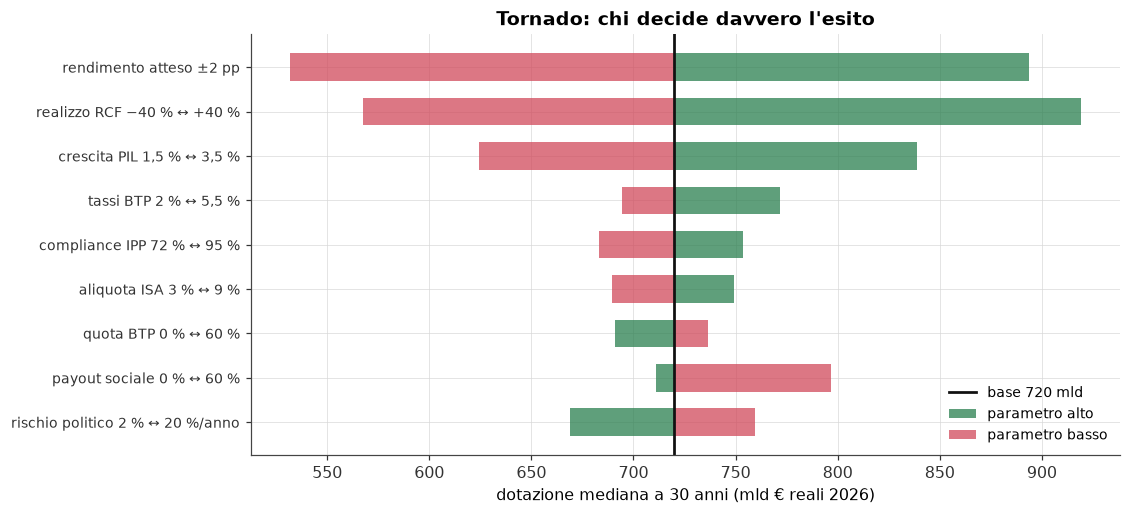


Classifica per escursione della dotazione a 30 anni:
  1. rendimento atteso ±2 pp                +362 mld
  2. realizzo RCF −40 % ↔ +40 %             +352 mld
  3. crescita PIL 1,5 % ↔ 3,5 %             +214 mld
  4. rischio politico 2 % ↔ 20 %/anno        -91 mld
  5. payout sociale 0 % ↔ 60 %               -86 mld
  6. tassi BTP 2 % ↔ 5,5 %                   +77 mld
  7. compliance IPP 72 % ↔ 95 %              +71 mld
  8. aliquota ISA 3 % ↔ 9 %                  +60 mld  ← e se ne parla per mesi
  9. quota BTP 0 % ↔ 60 %                    -45 mld

La leva più potente non è un'imposta: è la capacità di incassare le cartelle.
Chi discute solo di patrimoniale e successioni sta litigando sul 10 % del problema.


In [20]:
# ══════════════════════════════════════════════════════════════════════════════
# §13 — Sensibilità: il tornado plot
# ══════════════════════════════════════════════════════════════════════════════

_COSTO_ENERGIA = BENCH.loc["Pacchetto energia (ENI+ENEL+Snam+Terna)", "soglia_mld"]
NS = CFG.sim.n_paths_sens


def metrica(override=None, n=NS, seed=1234):
    """Simula uno scenario e restituisce le metriche di interesse."""
    r = np.random.default_rng(seed)
    p = costruisci_parametri(n, r, base=P0, override=override)
    s = simula_fondo(p, n, T, r, baseline=None)
    a = primo_raggiungimento(s["F_reale"], _COSTO_ENERGIA)
    return {
        "F30": float(np.median(s["F_reale"][:, 30])),
        "anni_energia": float(np.nanmedian(a)) if np.any(~np.isnan(a)) else np.nan,
        "div30": float(np.median(np.sum(s["D_reale"][:, :30], axis=1))),
    }


BASE_MET = metrica()
print(f"Scenario base: F30 mediano {BASE_MET['F30']:.0f} mld reali · "
      f"pacchetto energia all'anno {BASE_MET['anni_energia']:.1f}")

# (parametro, valore basso, valore alto, etichetta)
SHOCKS = [
    ("mercati.drift_atteso",            0.035, 0.075, "rendimento atteso ±2 pp"),
    ("politica.p_fav_a_avv",            0.02, 0.20,   "rischio politico 2 % ↔ 20 %/anno"),
    ("fonti.rcf_tasso_realizzo_annuo",  0.0060, 0.0140, "realizzo RCF −40 % ↔ +40 %"),
    ("fonti.ipp_compliance",            0.72, 0.95,   "compliance IPP 72 % ↔ 95 %"),
    ("fonti.isa_aliquota_media",        0.030, 0.090, "aliquota ISA 3 % ↔ 9 %"),
    ("macro.gdp_nominale_crescita",     0.015, 0.035, "crescita PIL 1,5 % ↔ 3,5 %"),
    ("mercati.btp_quota",               0.00, 0.60,   "quota BTP 0 % ↔ 60 %"),
    ("spesa.payout_quota",              0.00, 0.60,   "payout sociale 0 % ↔ 60 %"),
    ("mercati.btp_yield_lungo",         0.020, 0.055, "tassi BTP 2 % ↔ 5,5 %"),
]

righe = []
for chiave, vlo, vhi, lab in SHOCKS:
    ml = metrica({chiave: vlo})
    mh = metrica({chiave: vhi})
    righe.append({
        "parametro": lab,
        "F30 basso": ml["F30"], "F30 alto": mh["F30"],
        "Δ F30": mh["F30"] - ml["F30"],
        "anni basso": ml["anni_energia"], "anni alto": mh["anni_energia"],
    })

TORN = pd.DataFrame(righe).set_index("parametro").sort_values("Δ F30")
display(TORN.style.format({"F30 basso": "{:,.0f}", "F30 alto": "{:,.0f}", "Δ F30": "{:+,.0f}",
                           "anni basso": "{:.1f}", "anni alto": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(10.4, 4.8))
y = np.arange(len(TORN))
ax.barh(y, TORN["F30 alto"] - BASE_MET["F30"], left=BASE_MET["F30"],
        color=C["equity"], alpha=0.75, height=0.62, label="parametro alto")
ax.barh(y, TORN["F30 basso"] - BASE_MET["F30"], left=BASE_MET["F30"],
        color=C["accent"], alpha=0.75, height=0.62, label="parametro basso")
ax.axvline(BASE_MET["F30"], color=C["tot"], lw=1.8, label=f"base {BASE_MET['F30']:.0f} mld")
ax.set_yticks(y)
ax.set_yticklabels(TORN.index, fontsize=9)
ax.set_xlabel("dotazione mediana a 30 anni (mld € reali 2026)")
ax.set_title("Tornado: chi decide davvero l'esito")
ax.legend(fontsize=9, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
savefig(fig, "11_tornado")
plt.show()

_ord = TORN.reindex(TORN["Δ F30"].abs().sort_values(ascending=False).index)
print("\nClassifica per escursione della dotazione a 30 anni:")
for _i, (_nome, _r) in enumerate(_ord.iterrows(), 1):
    _mark = "  ← e se ne parla per mesi" if "ISA" in _nome else ""
    print(f"  {_i}. {_nome:<34} {_r['Δ F30']:+8.0f} mld{_mark}")

print("\nLa leva più potente non è un'imposta: è la capacità di incassare le cartelle.")
print("Chi discute solo di patrimoniale e successioni sta litigando sul 10 % del problema.")


## §14 — Scenari a confronto: cinque modi in cui può andare

I numeri della §10 sono una media di mondi possibili. Qui ne raccontiamo cinque, uno per uno,
perché è così che si ragiona di politica: non «quanto renderà», ma «cosa succede se».

| Scenario | Cosa cambia | Perché è interessante |
|---|---|---|
| **Base** | tutto al valore centrale | il mondo «tipico» |
| **Ottimista** | rischio politico 2 %/anno, compliance 92 %, rendimento 6,5 % | se la proposta funziona davvero |
| **Pessimista** | rischio politico 18 %/anno, rendimento 4,0 % | se il Paese non collabora |
| **Abolizione 2031** | patrimoniale e successoria cancellate per sempre dal 2031 | lo scenario che nessuno mette nei volantini |
| **Shock spread 2031** | +400 pb sui BTP in un anno (stile 2011) | cosa fa la duration al fondo |
| **Solo equity** | 100 % azioni, zero BTP | quanto costano le cedole in termini di crescita |
| **Glide-path BTP** | dal 30 % al 60 % di BTP in 15 anni | la «sostituzione del debito privato» |


,F10,F20,F30,F30 P10,F30 P90,div cumulato 30a,€/ab/anno al 30° (media),anni pacchetto energia
Base,204,437,734,433,"1,082",229,143,7.0
Ottimista,232,511,868,547,"1,220",311,166,6.0
Pessimista,174,352,545,339,776,179,99,8.0
Abolizione 2031,152,269,424,220,763,1,23,8.0
Shock spread 2031,209,449,744,442,"1,097",249,151,7.0
Solo equity,207,446,748,360,"1,335",356,216,7.0
Glide-path BTP,202,421,669,491,871,37,37,7.0


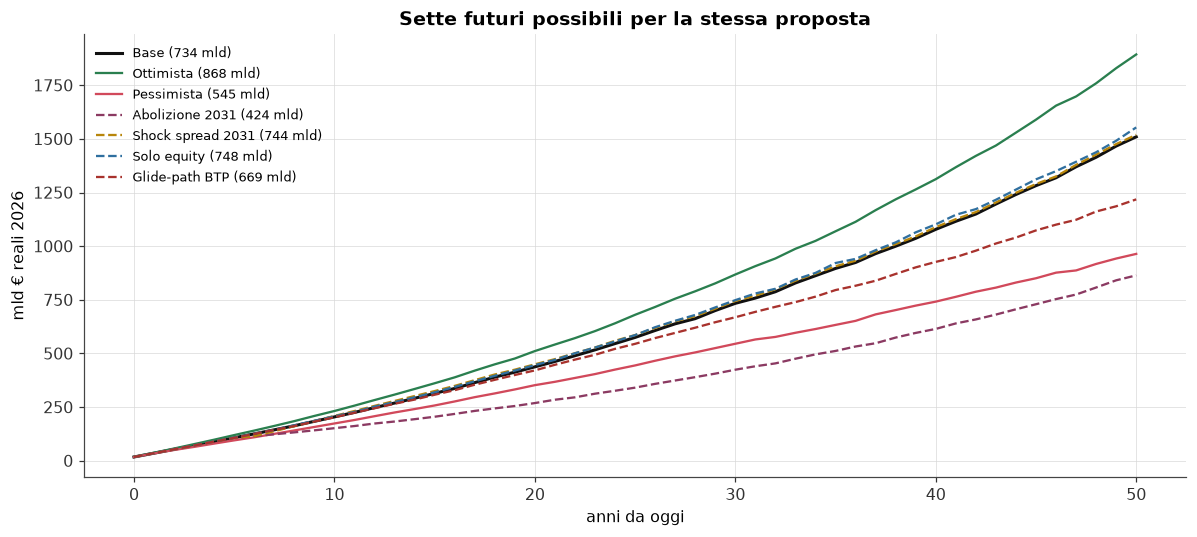

Da notare: lo scenario 'Abolizione 2031' non arriva a zero — il fondo continua a
incassare la riscossione (RCF) e a rendere sul capitale accumulato. Ma si ferma
a poco più della metà del percorso base, e il dividendo sociale si riduce a un
residuo: poche decine di euro per abitante all'anno, contro ~150 del caso base.


In [21]:
# ══════════════════════════════════════════════════════════════════════════════
# §14 — Scenari
# ══════════════════════════════════════════════════════════════════════════════

SCENARI = {
    "Base": {},
    "Ottimista": {"politica.p_fav_a_avv": 0.02,
                  "fonti.ipp_compliance": 0.92,
                  "mercati.drift_atteso": 0.065},
    "Pessimista": {"politica.p_fav_a_avv": 0.18,
                   "mercati.drift_atteso": 0.040},
    "Abolizione 2031": {"politica.anno_abolizione": 6},
    "Shock spread 2031": {"mercati.spread_shock_anno": 6,
                          "mercati.spread_shock_bp": 400.0},
    "Solo equity": {"mercati.btp_politica": "equity_only"},
    "Glide-path BTP": {"mercati.btp_politica": "glide"},
}

NSC = 3000
SCEN_RES = {}
SCEN_PATHS = {}

for nome, ov in SCENARI.items():
    r = np.random.default_rng(4242)
    p = costruisci_parametri(NSC, r, base=P0, override=ov)
    s = simula_fondo(p, NSC, T, r, baseline=None)
    SCEN_RES[nome] = {
        "F10": np.median(s["F_reale"][:, 10]),
        "F20": np.median(s["F_reale"][:, 20]),
        "F30": np.median(s["F_reale"][:, 30]),
        "F30 P10": np.quantile(s["F_reale"][:, 30], 0.10),
        "F30 P90": np.quantile(s["F_reale"][:, 30], 0.90),
        "div cumulato 30a": np.median(np.sum(s["D_reale"], axis=1)),
        "€/ab/anno al 30° (media)": np.mean(s["D_reale"][:, 29]) * 1e9 / POP,
        "anni pacchetto energia": np.nanmedian(primo_raggiungimento(s["F_reale"], _COSTO_ENERGIA)),
    }
    SCEN_PATHS[nome] = np.median(s["F_reale"], axis=0)

SCEN = pd.DataFrame(SCEN_RES).T
display(SCEN.style.format({
    "F10": "{:,.0f}", "F20": "{:,.0f}", "F30": "{:,.0f}", "F30 P10": "{:,.0f}",
    "F30 P90": "{:,.0f}", "div cumulato 30a": "{:,.0f}", "€/ab/anno al 30° (media)": "{:,.0f}",
    "anni pacchetto energia": "{:.1f}",
}).set_caption("Mediane, mld € reali 2026 (salvo il dividendo pro capite)"))

fig, ax = plt.subplots(figsize=(11.0, 5.0))
_colors = [C["tot"], C["equity"], C["accent"], C["isa"], C["ipp"], C["rcf"], C["btp"]]
for (nome, path), col in zip(SCEN_PATHS.items(), _colors):
    ax.plot(np.arange(T + 1), path, lw=2.0 if nome == "Base" else 1.5,
            ls="-" if nome in ("Base", "Ottimista", "Pessimista") else "--",
            color=col, label=f"{nome} ({SCEN.loc[nome, 'F30']:.0f} mld)")
ax.set_xlabel("anni da oggi")
ax.set_ylabel("mld € reali 2026")
ax.set_title("Sette futuri possibili per la stessa proposta")
ax.legend(fontsize=8.6, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
savefig(fig, "12_scenari")
plt.show()

print("Da notare: lo scenario 'Abolizione 2031' non arriva a zero — il fondo continua a\n"
      "incassare la riscossione (RCF) e a rendere sul capitale accumulato. Ma si ferma\n"
      "a poco più della metà del percorso base, e il dividendo sociale si riduce a un\n"
      "residuo: poche decine di euro per abitante all'anno, contro ~150 del caso base.")


## §15 — Limiti, e dove il modello sarebbe tentato di barare

Nessun modello è neutrale. Ecco i punti in cui questo potrebbe mentire, e cosa fa per non farlo.

### 15.1 Il peccato originale: il gettito è dirottato, non creato

I 17 mld/anno della dote iniziale sono **gettito che oggi finanzia altro**. Se il fondo li
investe e rende il 3,5 % reale mentre lo Stato, per quelle stesse risorse, avrebbe emesso debito
al 3,5 % reale, il guadagno netto è **zero**. La ricchezza nuova nasce solo dall'eventuale
**differenziale** tra rendimento degli asset e costo del finanziamento, e solo sulla parte di
patrimonio che viene effettivamente redistribuita.

Il grafico della §10 («attivo lordo» vs «valore netto creato») è l'unico modo onesto di
presentare la faccenda. La differenza è tipicamente un fattore 2-3: il numero grande che fa scena
è per due terzi **spostamento** e per un terzo **creazione**.

### 15.2 Un fondo pubblico che compra BTP non riduce il debito pubblico

Già detto nella §7.3, ma va ripetuto: nel bilancio consolidato, il debito comprato dal fondo è un
credito del fondo verso il Tesoro, e i due si elidono. **Il debito netto non scende.** Scende solo
la quota in mano ai privati e agli stranieri. È un obiettivo legittimo (stabilità, minore esposizione
agli umori del mercato) ma è un obiettivo **diverso** da «ridurre il debito», e i due vengono
sistematicamente confusi nel dibattito.

### 15.3 Il premio che si paga ai privati

Comprare ENEL al 35 % sopra il prezzo di mercato significa **regalare** 7 mld a chi vende. È il
prezzo di ogni nazionalizzazione, ed è il motivo per cui le nazionalizzazioni vere si fanno in
momenti di crisi (quando il prezzo è depresso), non quando l'azienda va bene. Nel modello il premio
è esplicito (35 %); nella propaganda non c'è mai.

### 15.4 Cose che il modello non vede

- **Regole europee.** Un fondo pubblico che compra azioni di società quotate italiane è aiuto di
  Stato? Dipende dal mandato, dalla governance, dal fatto che operi come investitore di mercato
  (*market economy operator principle*). Nella pratica può essere incompatibile con il quadro sugli
  aiuti di Stato. Qui non è modellato: è un vincolo **binario**, non un parametro.
- **Regole di bilancio.** Se il fondo è nel perimetro delle amministrazioni pubbliche, le sue
  passività contano nel debito. La sua struttura giuridica (fondazione? società? ente?) cambia
  tutto il quadro contabile. Non modellato.
- **Fuga di capitali.** Una patrimoniale dello 0,1 % è bassa, ma il segnale politico può spostare
  residenza fiscale e patrimoni. Nel modello è dentro `ipp_compliance`, in modo grezzo. Nella
  realtà è un effetto di annuncio, non di aliquota.
- **Incidenza economica.** Chi paga davvero la patrimoniale? In parte i proprietari, in parte i
  prezzi degli immobili, in parte i figli. Il modello assume che la paghi chi la riceve la cartella.
- **Capacità amministrativa.** Stimare il patrimonio di 25 milioni di famiglie richiede un catasto
  aggiornato e incroci di dati che oggi non esistono. Il modello lo tratta come una `compliance`.
- **Correlazione tra crisi politica e crisi di mercato.** Nel modello sono indipendenti. Nella
  realtà un governo che abolisce una patrimoniale è spesso un governo che riduce le tasse in una
  fase di crescita, e uno che la introduce lo fa in una fase di crisi fiscale. La correlazione
  peggiorerebbe la coda sinistra.

### 15.5 Cose che il modello fa e che è giusto riconoscergli

- Distingue reale e nominale, sempre.
- Usa total return con dividendi reinvestiti, non prezzi.
- Rende esplicito il rischio politico invece di assumere che le leggi non cambino.
- Non nasconde la circolarità dei BTP.
- Dichiara che i dati di mercato sono rozzi e che il gettito fiscale è un'opinione quantificata.


In [22]:
# ══════════════════════════════════════════════════════════════════════════════
# §15 — Export dei risultati
# ══════════════════════════════════════════════════════════════════════════════
RES_DIR = PROJECT_ROOT / "results"
RES_DIR.mkdir(exist_ok=True)

# quantili della dotazione, anno per anno
_q = pd.DataFrame({
    "anno": anni,
    "P5": np.quantile(FR, 0.05, axis=0),
    "P25": np.quantile(FR, 0.25, axis=0),
    "mediana": np.median(FR, axis=0),
    "P75": np.quantile(FR, 0.75, axis=0),
    "P95": np.quantile(FR, 0.95, axis=0),
    "mediana_nominale": np.median(F, axis=0),
})
_q.to_csv(RES_DIR / "dotazione_quantili.csv", index=False)

pd.DataFrame({
    "anno": np.arange(1, T + 1),
    "dividendo_mediano_mld": np.median(DR, axis=0),
    "dividendo_medio_mld": DR.mean(axis=0),
    "euro_pro_capite_mediano": np.median(DR * 1e9 / POP, axis=0),
    "P(nessun dividendo)": np.mean(D[:, :] < 0.01, axis=0),
}).to_csv(RES_DIR / "dividendo_sociale.csv", index=False)

TEMPI.to_csv(RES_DIR / "benchmark_nazionalizzazione.csv")
BENCH[["nome", "nota", "costo_mld"]].to_csv(RES_DIR / "benchmark_costi.csv")
TAB.to_csv(RES_DIR / "parametri.csv", index=False)
DIAG.to_csv(RES_DIR / "mcmc_diagnostica.csv", index=False)
SCEN.to_csv(RES_DIR / "scenari.csv")

print(f"Esportati {len(list(RES_DIR.glob('*.csv')))} CSV in {RES_DIR}")
for f in sorted(RES_DIR.glob("*.csv")):
    print(f"  · {f.name}")
print(f"Figure in {FIG_DIR}:")
for f in sorted(FIG_DIR.glob("*.png")):
    print(f"  · {f.name}")


Esportati 7 CSV in /home/massimiliano-romanello/Documenti/Fuffaguru_AVS/results
  · benchmark_costi.csv
  · benchmark_nazionalizzazione.csv
  · dividendo_sociale.csv
  · dotazione_quantili.csv
  · mcmc_diagnostica.csv
  · parametri.csv
  · scenari.csv
Figure in /home/massimiliano-romanello/Documenti/Fuffaguru_AVS/figures:
  · 01_waterfall_dote.png
  · 02_sensibilita_fonti.png
  · 03_entrate.png
  · 04_rendimenti.png
  · 05_btp.png
  · 06_dati.png
  · 07_mcmc_diagnostica.png
  · 08_risultati.png
  · 09_benchmark.png
  · 10_dividendo.png
  · 11_tornado.png
  · 12_scenari.png


In [23]:
# ══════════════════════════════════════════════════════════════════════════════
# §16 — Riassunto in una schermata
# ══════════════════════════════════════════════════════════════════════════════
_line = "─" * 74


def _fmt(x, dec=0):
    return f"{x:,.{dec}f}".replace(",", ".")


print(_line)
print("  FUFFAGURU_AVS · Fondo Popolare Sovrano · riassunto della simulazione")
print(_line)
print(f"  Orizzonte            : {T} anni · {NP:,} traiettorie · {S} estrazioni dal posterior".replace(",", "."))
print(f"  Dote iniziale F₀     : {_fmt(float(np.median(SIM['F0'])), 1)} mld €/anno")
print(f"    di cui RCF         : {_fmt(BASE0['RCF'], 1)}  ({BASE0['RCF'] / BASE0['totale']:.0%})")
print(f"    di cui IPP         : {_fmt(BASE0['IPP'], 1)}  ({BASE0['IPP'] / BASE0['totale']:.0%})")
print(f"    di cui ISA         : {_fmt(BASE0['ISA'], 1)}  ({BASE0['ISA'] / BASE0['totale']:.0%})")
print(_line)
print("  DOTAZIONE (mld € reali 2026)          mediana       P5 – P95")
for h in [10, 20, 30]:
    print(f"    anno {h:>2}                          {_fmt(np.median(FR[:, h])):>10}"
          f"   {_fmt(np.quantile(FR[:, h], .05)):>7} – {_fmt(np.quantile(FR[:, h], .95))}")
print(_line)
print("  NAZIONALIZZAZIONI (anno mediano, P10-P90)")
for k in ["TIMrete", "Poste", "Snam", "Terna", "Leonardo", "ENI", "ENEL", "FS",
          "Pacchetto energia (ENI+ENEL+Snam+Terna)", "Tutti e otto gli obiettivi",
          "Debito 5 %", "Debito estero"]:
    a = anni_hit[k]
    if np.all(np.isnan(a)):
        print(f"    {BENCH.loc[k,'nome'][:44]:<46} mai entro {T} anni")
    elif np.nanmedian(a) < 1:
        print(f"    {BENCH.loc[k,'nome'][:44]:<46} subito")
    else:
        print(f"    {BENCH.loc[k,'nome'][:44]:<46} {np.nanmedian(a):4.0f}"
              f"   ({np.nanquantile(a,.1):.0f}–{np.nanquantile(a,.9):.0f})")
print(_line)
print("  DIVIDENDO SOCIALE")
print(f"    €/abitante all'anno, 30° anno : media {_fmt(np.mean(pro_capite[:, 29]))} €"
      f" · mediana {_fmt(np.median(pro_capite[:, 29]))} €")
print(f"    cumulato 30 anni per abitante : mediana {_fmt(np.median(pro_capite_cum30))} €"
      f" · media {_fmt(np.mean(pro_capite_cum30))} €")
print(f"    mondi in cui paga qualcosa    : {paga_almeno_una_volta:.0%}")
print(_line)
print("  ONESTÀ CONTABILE")
print(f"    attivo lordo mediano a 30 anni: {_fmt(np.median(FR[:, 30]))} mld € reali")
print(f"    valore netto creato           : {_fmt(np.median(cum_val[:, 29]))} mld € reali"
      f"  ({np.median(cum_val[:, 29]) / np.median(FR[:, 30]):.0%})")
print(_line)


──────────────────────────────────────────────────────────────────────────
  FUFFAGURU_AVS · Fondo Popolare Sovrano · riassunto della simulazione
──────────────────────────────────────────────────────────────────────────
  Orizzonte            : 50 anni · 12.000 traiettorie · 600 estrazioni dal posterior
  Dote iniziale F₀     : 17.4 mld €/anno
    di cui RCF         : 10.0  (58%)
    di cui IPP         : 5.8  (34%)
    di cui ISA         : 1.5  (9%)
──────────────────────────────────────────────────────────────────────────
  DOTAZIONE (mld € reali 2026)          mediana       P5 – P95
    anno 10                                 205       123 – 298
    anno 20                                 432       239 – 664
    anno 30                                 712       353 – 1.193
──────────────────────────────────────────────────────────────────────────
  NAZIONALIZZAZIONI (anno mediano, P10-P90)
    Riacquisto rete TIM (100 %)                       1   (1–2)
    Delisting Poste Italiane (

## §17 — Il punto: dove finisce l'analisi e dove comincia la fuffa

### Quello che il modello dice, in cinque frasi

1. **La proposta è finanziariamente fattibile.** Con ~17 mld l'anno, rendimenti prudenti e un po'
   di rischio politico, il fondo arriva a **~200 mld reali in 10 anni, ~430 in 20, ~720 in 30**
   (mediane; il ventaglio 5-95 % è largo circa un fattore 3). La liquidità per comprare ENI, ENEL,
   Snam, Terna o la rete TIM **c'è, e arriva presto**: il pacchetto energia (129 mld, riserva
   inclusa) è alla portata in mediana all'anno 7, tutti e otto gli obiettivi (224 mld) all'anno 11.
   Chi dice che «non ci sono i soldi» non ha fatto i conti.
2. **Il vincolo non è il denaro, è il prezzo e il permesso.** Comprare il 42 % di ENI significa
   pagare il 35 % di premio a chi vende e avere l'autorizzazione di mezza Europa. Il modello lo
   mette in conto come una riga di costo; nella realtà è il vero ostacolo, e non è economico.
3. **Contano l'incasso e il rendimento, non le aliquote.** Nel tornado plot le due leve più potenti
   sono il **rendimento** e il **tasso di realizzo della riscossione**, entrambe attorno a **~360
   mld** di escursione (così vicine che l'ordine cambia tra una run e l'altra); seguono la
   **crescita del PIL** (~216) e il **rischio politico** (~95). L'**aliquota della successione**
   vale ~60 mld: su una dotazione di ~730 mld a 30 anni è l'8 %. È la leva su cui si scrivono gli
   editoriali, ed è quella che sposta meno.
4. **Il dividendo sociale è un premio di risultato, non un reddito.** Nella configurazione proposta
   **la mediana annua è zero euro**: nell'anno tipico non si distribuisce nulla, perché il fondo sta
   sotto il piano. La media è di ~150 €/abitante all'anno al 30° anno, trascinata dai mondi in cui
   le cose vanno bene; l'86 % dei mondi paga qualcosa almeno una volta, con un cumulato mediano di
   ~1.250 € pro capite in 30 anni. Non è un assegno universale: è la restituzione di un extra. Chi
   lo presenta come una misura strutturale sta vendendo qualcosa che il modello non produce.
5. **Due terzi del numero grande non sono ricchezza nuova.** Sono gettito dirottato, azioni
   comprate da privati, BTP comprati da altri creditori. È la parte che i volantini non dicono.

### Dove sta la fuffa

La fuffa non è nell'idea in sé: un fondo sovrano che investe in infrastrutture e partecipate è uno
strumento legittimo, e la letteratura sui fondi sovrani (Norvegia, Singapore, Cile) esiste. La
fuffa sta in **tre slittamenti semantici** che questo modello aiuta a smascherare:

- **«Ridurre il debito»** invece di «cambiare chi detiene il debito». Sono cose diverse, e la
  prima non succede.
- **«Investire»** invece di «spendere». Comprare ENEL non è investire: è comprare un'azienda che
  già esiste, pagandola più di quanto vale sul mercato.
- **«Reddito per tutti»** invece di «eventuale surplus distribuito». La differenza è tutta nella
  parola *eventuale*, e nella varianza che il ventaglio della §10 mostra brutalmente.

### Il paradosso che chiude il cerchio

Se il fondo funziona, cioè se rende più del costo del debito, allora conviene **non comprare le
partecipate** e lasciare il capitale investito nel mercato: comprare ENI al 35 % di premio
distrugge valore rispetto a tenere lo stesso capitale in un ETF globale. Se invece l'obiettivo è
il **controllo politico** delle aziende, allora il fondo sovrano è uno strumento inutilmente
costoso per ottenerlo: lo Stato può semplicemente cambiare la golden share, la governance o la
legge. Il fondo è la soluzione tecnicamente elegante a un problema che non è tecnico.

**Questo è il punto.** Un fondo sovrano ha senso quando c'è un eccesso di risparmio da allocare
(Norvegia) o un obiettivo di sviluppo di lungo periodo (Singapore). In un Paese a debito alto e
crescita bassa, un fondo finanziato con nuove imposte è **un giro di cassa**: prende risorse
costose e le impiega in attivi che rendono poco più. Può avere senso politico — dare ai cittadini
una partecipazione visibile nelle aziende di casa — ma non è un moltiplicatore di ricchezza. È
un modo di **spendere meglio**, non di **spendere di più**, e vale solo se il rendimento supera
davvero il costo del debito. Nel modello succede, ma di poco: uno o due punti percentuali l'anno,
che è esattamente la differenza tra un'analisi e uno slogan.

---

### Come si gioca con questo notebook

Cinque mosse per esplorare, in ordine di interesse:

1. **`politica.p_fav_a_avv = 0.02`** → che succede se il rischio politico è basso come in Germania?
   E a `0.25`, come in un Paese con alternanza turbolenta?
2. **`mercati.drift_atteso = 0.035`** → e se il fondo rendesse come i BTP? Spoiler: la proposta
   perde ogni senso economico, e il dividendo sociale sparisce.
3. **`fonti.isa_aliquota_media = 0.12`** → e se si tassassero le successioni davvero, tipo Francia?
   Guarda quanto poco cambia la dotazione a 30 anni, e quanto invece cambia il dibattito pubblico.
4. **`spesa.payout_quota = 0.8`** → il «reddito per tutti» spinto al massimo: guarda cosa succede
   alla dotazione e ai tempi di nazionalizzazione. È il modo migliore per capire il trade-off.
5. **`mercati.btp_politica = "glide"` con `btp_quota_max = 0.9`** → il massimo della «sostituzione
   del debito privato». Guarda il rendimento scendere e la volatilità calare. È il compromesso
   politicamente più realistico.

Per modificare un parametro al volo senza toccare la dataclass:

```python
p = {**P0, "mercati.drift_atteso": 0.04, "politica.p_fav_a_avv": 0.03}
sim = simula_fondo(p, 8000, 50, np.random.default_rng(1), baseline=None)
print(np.median(sim["F_reale"][:, 30]))
```

Buona simulazione. E se i numeri ti sembrano troppo belli, controlla di aver lasciato
`alpha_mode = "t_student"`: con `"uniform"` e drift a zero il fondo non cresce affatto, e scopri
che metà dell'operazione era… il rendimento.
